# DX703 Final Project Milestone: Data Exploration and Baseline Modeling

### Due Date: Sunday, November 15th at 11:59pm (with 2 hour plus 1 minute grace period)

**No late submissions!**


## Purpose and scope

This is the **first of two project submissions**. Choose **one** classification dataset—**Food-101** (images) or **HuffPost News Category** (text)—and carry it from initial exploration through a reproducible **baseline model**.

In this milestone you will:

1. Explore both datasets briefly; select and investigate one (**10 pts**).
2. Frame its classification problem, challenges, and evaluation strategy (**15 pts**).
3. Clean and preprocess your data and create reproducible train/validation/test splits (**30 pts**).
4. Train and evaluate a simple baseline using **training and validation data only** (**30 pts**).

**The later final submission** will cover a more capable custom model, a pretrained/transfer-learning model, comparison and selection, a refined final model, and the final technical report. Details of that submission will be posted separately.

### Important conventions

- Retain your chosen dataset for the entire project. Remove the unused dataset's starter cells **after** exploring both.
- Use a fixed random seed, state all data-selection choices and important hyperparameters, and keep the notebook runnable from top to bottom.
- You may use a documented, reproducible subset for experiments if computing resources are limited; explain its size and selection process. Do not represent subset performance as full-dataset performance.
- **Keep the test set untouched in this milestone.** Select models and discuss baseline performance using *validation* results. Save test-set evaluation for the final submission.
- Write each graded explanation in its designated Python string answer variable (`a1a`, `a1b`, etc.). Do not modify the following **Graded Answer** print cells. You may add code cells, plots, or comments as necessary. Follow the approximate word-count guidelines in each problem (100–150 words for Problems 1, 3, and 4; 75–125 words for Problem 2).
- Include an AI-use disclosure at the end in accordance with CDS policy.


### Grading — 85 points total

| Problem | Grading basis | Points |
|---|---|---:|
| 1. Choose the Dataset | 5 questions × 2 pts, including supporting code, tables, and plots | **10** |
| 2. Frame the Problem | 5 questions × 3 pts, including supporting evidence | **15** |
| 3. Data Preparation and Splits | Programming: 18 pts; 4 written answers × 3 pts | **30** |
| 4. Baseline Model | Programming: 18 pts; 4 written answers × 3 pts | **30** |
| **Total** | | **85** |

**How your work will be assessed:** For Problems 1–2, each question will be assessed as a whole, including your written response and the supporting code, tables, or plots. For Problems 3–4, programming and written answers receive separate point allocations.

Programming will be assessed primarily for **correctness and completeness**, with attention to reproducibility, organization, and clarity. Written answers should accurately explain *your own implementation and results*, referring to specific evidence from the notebook. Code may be reviewed and tested, so explanations alone do not earn programming credit. Your submitted notebook must run from beginning to end without errors.

**Use of AI in grading:** We will use AI tools to assist with reviewing code, evaluating written responses, and identifying possible errors or omissions. However, **AI will not make final grading decisions. Every proposed point deduction will be reviewed by a human grader before it is applied.** Human graders retain responsibility for determining and assigning final scores.

In [1]:
# ============================================
# Useful Imports
# ============================================

# --- Standard Libraries
import os
import time
import math
import random
from collections import Counter

# --- Core Data / Numerics
import numpy as np
import pandas as pd

# --- Visualization
import matplotlib.pyplot as plt
import seaborn as sns              # optional
import matplotlib.ticker as mticker  # optional (for formatted axes)

# --- NLP / Tokenization
import spacy                         # used for text preprocessing (HuffPost)

# --- Progress Tracking
from tqdm import tqdm                # optional (nice for loops)

from IPython.display import display

# --- TensorFlow / Keras (Deep Learning)
import tensorflow as tf
from tensorflow.keras import layers, models, Input, callbacks, regularizers, initializers
from tensorflow.keras.callbacks import Callback, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam, AdamW
from tensorflow.keras.optimizers.schedules import CosineDecay, ExponentialDecay
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.layers import (
    Dense, Dropout, Flatten, MaxPooling2D, Conv2D,
    SeparableConv2D, GlobalAveragePooling2D, GlobalMaxPooling2D, BatchNormalization
)

# --- (Optional) Classical ML Baseline Tools
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score


# ============================================
# Global Configuration & Small Utilities
# ============================================

# Reproducibility
random_seed = 42
random.seed(random_seed)
np.random.seed(random_seed)
tf.keras.utils.set_random_seed(random_seed)   # sets Python, NumPy, and TensorFlow seeds

# Utility: format seconds as HH:MM:SS

"""
Example usage to time your code:

start_time = time.time()
# ... your code here ...
print("Execution Time:", format_hms(time.time() - start_time))
"""

def format_hms(seconds: float) -> str:
    """Convert seconds to HH:MM:SS format."""
    return time.strftime("%H:%M:%S", time.gmtime(seconds))


In [2]:
# If needed (in a new env):
# !pip install -U datasets pillow

In [2]:
# --- Hugging Face Datasets
from datasets import load_dataset, DatasetDict
from datasets.features import ClassLabel

### Dataset One (Images): Food-101

#### **Load Food-101 as a Dataset**

> Note: this loads a **Hugging Face `Dataset`**, not NumPy or TensorFlow tensors.
> Each sample is stored as a **dictionary** with two keys — `"image"` (a PIL image object) and `"label"` (an integer class ID).
> You can access columns by name, e.g. `food_all["image"]` or `food_all["label"]`, and check the dataset size with `len(food_all)`.
> Unlike arrays, image sizes and aspect ratios may differ across samples — you’ll handle resizing or normalization later during preprocessing.


In [3]:
food_all = load_dataset("ethz/food101", split="train+validation")  # ~101k images total
label_col = "label"

# Sanity check the label column
assert label_col in food_all.features
assert isinstance(food_all.features[label_col], ClassLabel)

food_label_names = food_all.features[label_col].names
print(f"Total images: {len(food_all):,}  |  Classes: {len(food_label_names)}")

Total images: 101,000  |  Classes: 101


#### **Quick sanity checks (rows, label ids, a few image sizes)**

In [4]:
# First 5 rows: label id → name
for i in range(5):
    y = food_all[i][label_col]
    print(f"row {i}: id={y}, name={food_label_names[y]}")

labels_list = list(food_all[label_col])
print("labels length:", len(labels_list), "unique classes:", len(set(labels_list)))
print("min/max label IDs:", min(labels_list), max(labels_list))

for i in range(3):
    print(f"image {i} size:", food_all[i]["image"].size)  # (W, H)

row 0: id=6, name=beignets
row 1: id=6, name=beignets
row 2: id=6, name=beignets
row 3: id=6, name=beignets
row 4: id=6, name=beignets
labels length: 101000 unique classes: 101
min/max label IDs: 0 100
image 0 size: (384, 512)
image 1 size: (512, 512)
image 2 size: (512, 383)


#### **Visual preview: random 3×3 grid from TRAIN**

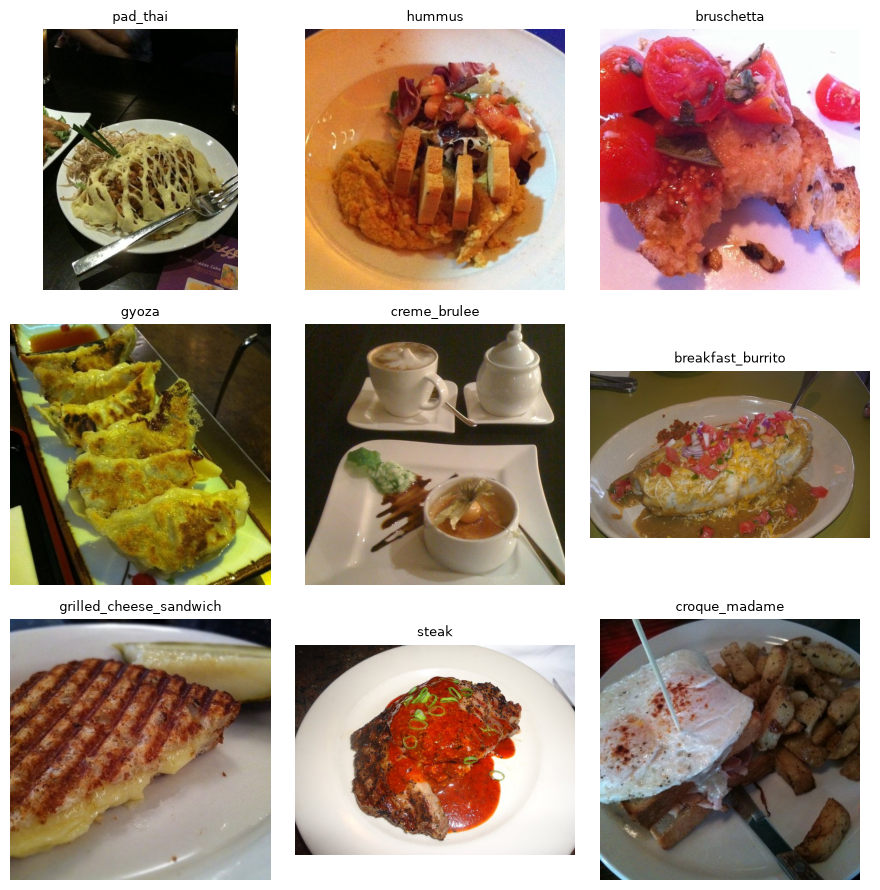

In [5]:
n, cols, seed = 9, 3, 42
idxs = random.Random(seed).sample(range(len(food_all)), n)
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = food_all[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]], fontsize=9)
plt.tight_layout(); plt.show()

---

## Problem 1 — Choose the Dataset (10 pts)

#### Objective
In this problem, you will explore the two provided datasets and select one to use for your final project.  
Your goal is to understand the structure, content, and challenges of the dataset through basic exploratory data analysis (EDA).  
By the end of this milestone notebook, you should be able to explain what makes the dataset interesting, identify potential modeling challenges (e.g., imbalance, ambiguity, quality issues), and justify why it is a good choice for your classification project.


#### What to Do
1. **Load both datasets** and examine the outputs of the template code provided.  
   After this brief inspection, **choose one dataset for your project** and **delete the template code for the other.**  For your chosen dataset, continue with the remaining steps.

2. **Inspect** the dataset's basic properties:  
   - **Number of samples and classes:**  
     Determine how many total examples and distinct categories are present. Verify that the counts match expectations (e.g., 101 food classes or 41 news topics).  
   - **Example records or images:**  
     View several samples to understand the input format, diversity, and potential quality issues.  
     For images, note lighting or composition differences; for text, read a few headlines and summaries to see how expressive they are (done for you in template code). 
   - **Distribution of labels (check for imbalance):**  
     Plot or tabulate label frequencies to see whether some classes dominate. Imbalanced datasets can bias model training and may require special handling.  
   - **Missing or inconsistent data:**  
     Look for empty fields, unreadable images, duplicate entries, or mislabeled samples. Handle or document any issues you find.  
   - **Overlapping or ambiguous class labels:**  
     Identify categories that may not be clearly distinct—e.g., “apple pie” vs. “cheesecake,” or “POLITICS” vs. “WORLD NEWS.”  
     Ambiguity in labels can increase confusion between classes and reduce model accuracy.

3. **Visualize key aspects:**  
   Extend the template code to complete the EDA for your chosen dataset:  
   - **Images:**  
     Create visual summaries to better understand the data (some are implemented in the template code).  
     - Verify that the dataset is balanced across classes.  
     - Display a small grid of random images to check variation in appearance, composition, and background (done in template code).  
     - Compare image sizes to determine whether resizing or normalization will be needed.  
     - Examine lighting and color balance—many web-scraped photos vary widely in brightness, saturation, and white balance.  
   - **Text:**  
     Visualize class balance and linguistic properties (some implemented in the template code).  
     - Plot the number of samples per label to confirm class balance or imbalance.  
     - Compute basic text statistics such as average word count or vocabulary size.  
     - Examine examples for duplicates, near-duplicates, or entries that might fit multiple categories.  
     - *(Optional)* Generate a word-frequency plot or word cloud to highlight distinctive terms for a few classes.

4. **Answer the graded questions below.**


### Check for Corrupted Images

In [4]:
from PIL import Image as PILImage
from datasets import Image as HFImage
import io

food_all_copy = load_dataset("ethz/food101", split="train+validation")

# keep images in terms of bytes rather than decoded
food_all_copy = food_all_copy.cast_column('image', HFImage(decode=False))

corrupted_image_idx = []

for idx, img in enumerate(food_all_copy):
    try:
        image_bytes = img['image']['bytes']

        if image_bytes is None:
            raise ValueError('Image bytes are None')

        # verify image integrity
        with PILImage.open(io.BytesIO(image_bytes)) as i:
            i.verify()

    except (IOError, SyntaxError, ValueError, TypeError) as e:
        print(f"Corrupted image found at index {idx}: {e}")
        corrupted_image_idx.append(idx)

print(f'Total corrupted images: {len(corrupted_image_idx)}')
print(f'Corrupted indices: {corrupted_image_idx}')

Total corrupted images: 0
Corrupted indices: []


### EDA

Class Counts: {'beignets': 1000, 'prime_rib': 1000, 'ramen': 1000, 'hamburger': 1000, 'bruschetta': 1000, 'chicken_wings': 1000, 'pork_chop': 1000, 'greek_salad': 1000, 'sashimi': 1000, 'risotto': 1000, 'pizza': 1000, 'eggs_benedict': 1000, 'guacamole': 1000, 'chocolate_cake': 1000, 'miso_soup': 1000, 'apple_pie': 1000, 'fried_calamari': 1000, 'fried_rice': 1000, 'panna_cotta': 1000, 'hummus': 1000, 'carrot_cake': 1000, 'beet_salad': 1000, 'garlic_bread': 1000, 'hot_dog': 1000, 'steak': 1000, 'tiramisu': 1000, 'fish_and_chips': 1000, 'caesar_salad': 1000, 'tuna_tartare': 1000, 'pancakes': 1000, 'chocolate_mousse': 1000, 'lasagna': 1000, 'pad_thai': 1000, 'cheesecake': 1000, 'baklava': 1000, 'ice_cream': 1000, 'red_velvet_cake': 1000, 'tacos': 1000, 'foie_gras': 1000, 'grilled_cheese_sandwich': 1000, 'frozen_yogurt': 1000, 'seaweed_salad': 1000, 'breakfast_burrito': 1000, 'crab_cakes': 1000, 'strawberry_shortcake': 1000, 'beef_tartare': 1000, 'mussels': 1000, 'dumplings': 1000, 'creme_b

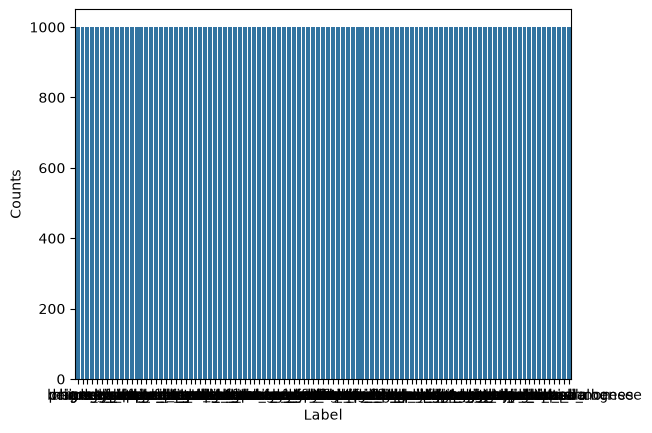

In [5]:
# Your code here, add as many cells as you like. Provide organization and structure by appropriate comments, labels, and variable names. Explain what
# you are doing in case you come back to this in a year. 

# Get the class balance for the food101 dataset
class_counts  = Counter(food_all['label'])
label_names   = food_all.features['label'].names
class_balance = {label_names[label_id]: count for label_id, count in class_counts.items()}
print('Class Counts:', class_balance)
print('Unique Counts per Class:', pd.Series(class_balance.values()).unique())

# check to see if there are any images from food101 dataset that don't have any labels
df = food_all.to_pandas()
print('Total images without labels:', df['label'].isna().sum())

# plot class balance
data = {'Label': class_balance.keys(),
        'Counts': class_balance.values()}
df = pd.DataFrame(data)
sns.barplot(df, x='Label', y='Counts')
plt.show()

In [6]:
import warnings

# Suppress only the Pillow TIFF tag warnings:           
#       Used Gemini: https://share.gemini.google/GqmCJU5IcIhZ
warnings.filterwarnings('ignore', category=UserWarning, module='PIL.TiffImagePlugin')

# gather all image sizes (Width, Height)
img_dimensions = []
for i in food_all:
    img_dimensions.append(i['image'].size)

# check the unique image dimensions
unique_dimensions = list(set(img_dimensions))
print('Unique image dimensions:', unique_dimensions)
print('Unique Dimension Count:', len(unique_dimensions))

img_sizes = []  # regardless of orientation
for i in unique_dimensions:
    w, h = i    # gets width and height from dimension tuple (width, height)
    size = w * h
    img_sizes.append(size)
unique_sizes = set(img_sizes)
print('Unique image sizes:', unique_sizes)
print('Unique image size count:', len(unique_sizes))

Unique image dimensions: [(308, 512), (319, 512), (453, 512), (512, 409), (512, 418), (512, 427), (512, 436), (376, 512), (512, 445), (510, 512), (415, 512), (512, 274), (512, 283), (512, 292), (512, 301), (338, 512), (512, 310), (494, 512), (483, 512), (472, 512), (377, 512), (512, 404), (445, 512), (512, 413), (512, 422), (512, 431), (512, 440), (512, 269), (512, 278), (512, 287), (512, 296), (512, 305), (464, 512), (475, 512), (512, 390), (349, 512), (512, 399), (512, 408), (512, 417), (512, 426), (417, 512), (456, 512), (512, 273), (512, 511), (512, 282), (512, 291), (379, 512), (368, 512), (390, 512), (512, 376), (512, 385), (512, 394), (447, 512), (512, 403), (341, 512), (330, 512), (512, 412), (486, 512), (512, 241), (512, 259), (409, 512), (512, 268), (512, 506), (512, 277), (437, 512), (448, 512), (371, 512), (505, 512), (512, 371), (410, 512), (512, 380), (399, 512), (512, 389), (512, 398), (512, 407), (333, 512), (322, 512), (467, 512), (512, 236), (512, 254), (512, 492), (5

In [7]:
from PIL import Image, ImageStat

def rms_brightness(image):
    """
        Greyscales image and then calculates the root mean square pixel value from 0-256 (0: pure black, 255: pure white)
            Source: https://stackoverflow.com/questions/3490727/what-are-some-methods-to-analyze-image-brightness-using-python
    """
    img  = image.convert('L')
    stat = ImageStat.Stat(img)
    return stat.rms[0]


def perceived_brightness(image):
    """
        Averages RBG values of image, then returns the human perceived brightness value 0-1 (0: pure black, 1: pure white)
            Sources: https://alienryderflex.com/hsp.html https://stackoverflow.com/questions/3490727/what-are-some-methods-to-analyze-image-brightness-using-python
    """
    img   = image.convert('RGB') # ensure all images are RGB
    stat  = ImageStat.Stat(img)
    r,g,b = stat.mean
    return math.sqrt(0.299*(r**2) + 0.587*(g**2) + 0.114*(b**2))

# For all images, record their labels and brightness metrics
brightness_data = []
for i in food_all:
    brightness_data.append({
        'Food Label'            : label_names[i['label']],
        'RMS Brightness'        : rms_brightness(i['image']),
        'Perceived Brightness'  : perceived_brightness(i['image'])
    })
img_characteristics = pd.DataFrame(brightness_data)
img_characteristics.describe()

,RMS Brightness,Perceived Brightness
count,101000.000000,101000.000000
mean,133.247694,119.780921
std,26.084445,27.659153
min,2.851318,2.905803
25%,117.446433,102.035896
50%,133.671916,119.896454
75%,150.476857,138.434911
max,240.370416,236.354698


In [15]:
# Assess the mean brightness metrics per classification
food_label_brightness = img_characteristics.groupby('Food Label')[['RMS Brightness', 'Perceived Brightness']].mean()
perceived_brightness_sorted = food_label_brightness['Perceived Brightness'].sort_values(ascending=False)
rms_brightness_sorted       = food_label_brightness['RMS Brightness'].sort_values(ascending=False)

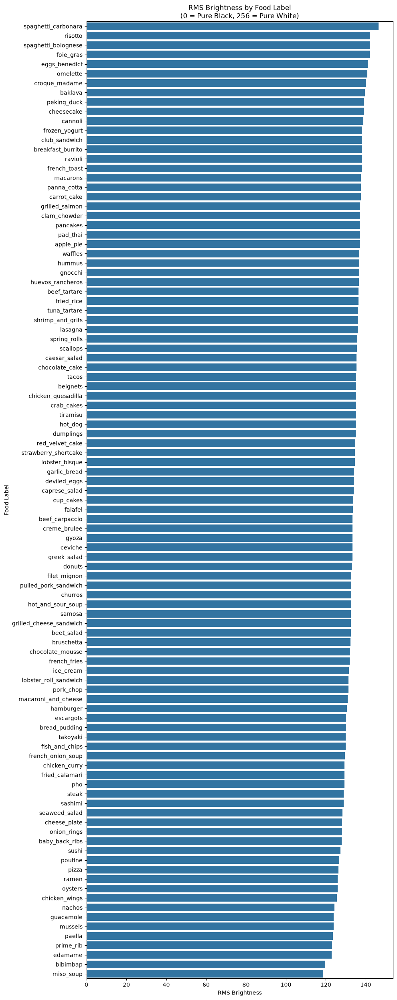

In [16]:
plt.figure(figsize=(10, 25))
sns.barplot(
    x=rms_brightness_sorted.values,
    y=rms_brightness_sorted.index,
    orient='h'
)
plt.title('RMS Brightness by Food Label\n(0 = Pure Black, 256 = Pure White)')
plt.xlabel('RMS Brightness')
plt.tight_layout()

In [17]:
# get numeric/string label pair for easy lookup
numeric_labels = set(food_all['label'])
lookup_data = [
    {
        'Label Index': num_label,
        'Label Name': food_label_names[num_label]
    }
    for num_label in numeric_labels
]
LABELS_IDX_LOOKUP = pd.DataFrame(lookup_data)
LABELS_IDX_LOOKUP.head()

,Label Index,Label Name
0,0,apple_pie
1,1,baby_back_ribs
2,2,baklava
3,3,beef_carpaccio
4,4,beef_tartare


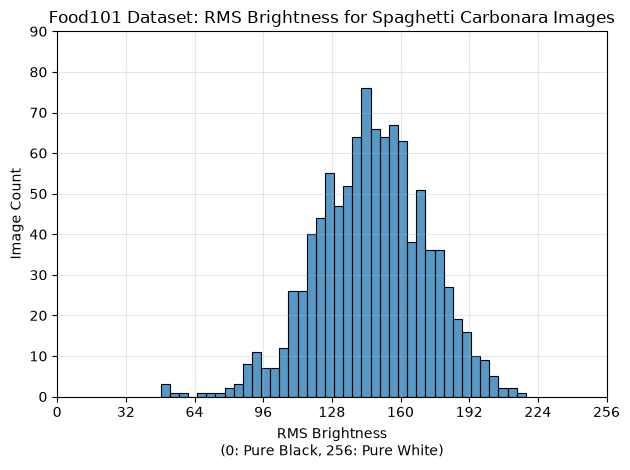

Min RMS Brightness       : 48.1971
Max RMS Brightness       : 218.4245
Median RMS Brightness    : 147.0399
RMS Brightness Range     : 170.2274


In [18]:
# Visualizing maximum RMS Brightness Food Label
max_brightness_idx   = rms_brightness_sorted.argmax()
max                  = rms_brightness_sorted.iloc[max_brightness_idx]
max_label            = rms_brightness_sorted.idxmax()

# max_brightness_idx, max_label, max

# Get label index, all images with label index value, and record their RMS brightness values
max_idx             = LABELS_IDX_LOOKUP[LABELS_IDX_LOOKUP['Label Name'] == max_label]['Label Index'].iloc[0]
max_images          = [i for i in food_all if i['label'] == max_idx]
rms_brightness_max  = [rms_brightness(i['image']) for i in max_images]

sns.histplot(rms_brightness_max, bins=40)
plt.title(f'Food101 Dataset: RMS Brightness for {max_label.replace("_", " ").title()} Images')
plt.ylabel('Image Count')
plt.xlabel('RMS Brightness\n(0: Pure Black, 256: Pure White)')

plt.xlim(0, 256)
plt.xticks(range(0, 257, 32))       # ticks every 32 (8 total ticks)
plt.yticks(range(0, 91, 10))        # frequency ticks 0-90 (checked between three RMS histograms to find common maximum y tick for easier comparability)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Min RMS Brightness       : {np.min(rms_brightness_max):.4f}')
print(f'Max RMS Brightness       : {np.max(rms_brightness_max):.4f}')
print(f'Median RMS Brightness    : {np.median(rms_brightness_max):.4f}')
print(f'RMS Brightness Range     : {(np.max(rms_brightness_max) - np.min(rms_brightness_max)):.4f}')

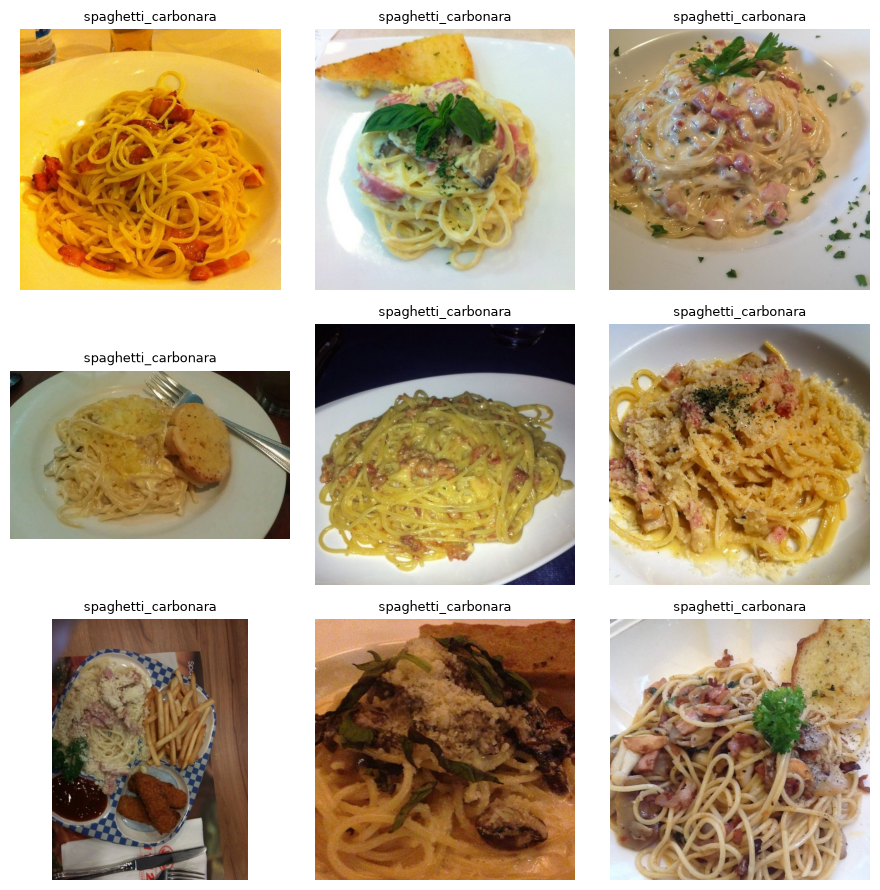

In [19]:
# Visualizing a sample of max RMS brightness food images
numeric_label  = LABELS_IDX_LOOKUP[LABELS_IDX_LOOKUP['Label Name'] == max_label]['Label Index'].iloc[0]
max_rms_images = [i for i in food_all if i['label'] == numeric_label]

n, cols, seed = 9, 3, 42
idxs = random.Random(seed).sample(range(len(max_rms_images)), n)
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = max_rms_images[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]], fontsize=9)
plt.tight_layout(); plt.show()

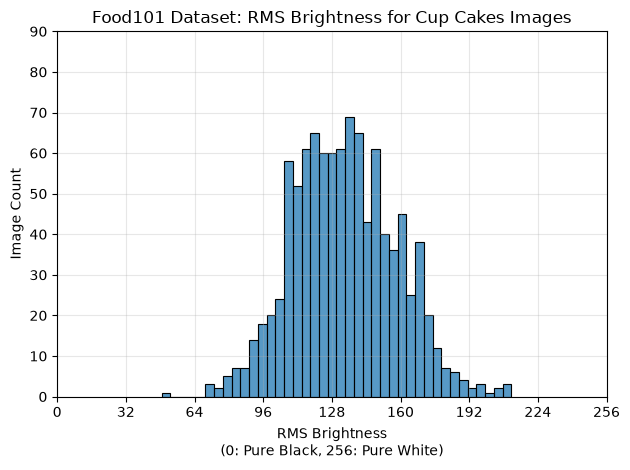

Min RMS Brightness       : 48.6810
Max RMS Brightness       : 211.6392
Median RMS Brightness    : 132.8360
RMS Brightness Range     : 162.9582


In [20]:
# Visualizing median RMS Brightness Food Label
median_brightness_idx   = len(rms_brightness_sorted) // 2
median                  = rms_brightness_sorted.iloc[median_brightness_idx]
median_label            = rms_brightness_sorted.index[median_brightness_idx]

# median_brightness_idx, median_label, median

# Get label index, all images with label index value, and record their RMS brightness values
median_idx             = LABELS_IDX_LOOKUP[LABELS_IDX_LOOKUP['Label Name'] == median_label]['Label Index'].iloc[0]
median_images          = [i for i in food_all if i['label'] == median_idx]
rms_brightness_median  = [rms_brightness(i['image']) for i in median_images]

sns.histplot(rms_brightness_median, bins=40)
plt.title(f'Food101 Dataset: RMS Brightness for {median_label.replace("_", " ").title()} Images')
plt.ylabel('Image Count')
plt.xlabel('RMS Brightness\n(0: Pure Black, 256: Pure White)')

plt.xlim(0, 256)
plt.xticks(range(0, 257, 32))       # ticks every 32 (8 total ticks)
plt.yticks(range(0, 91, 10))        # frequency ticks 0-90 (checked between three RMS histograms to find common maximum y tick for easier comparability)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Min RMS Brightness       : {np.min(rms_brightness_median):.4f}')
print(f'Max RMS Brightness       : {np.max(rms_brightness_median):.4f}')
print(f'Median RMS Brightness    : {np.median(rms_brightness_median):.4f}')
print(f'RMS Brightness Range     : {(np.max(rms_brightness_median) - np.min(rms_brightness_median)):.4f}')

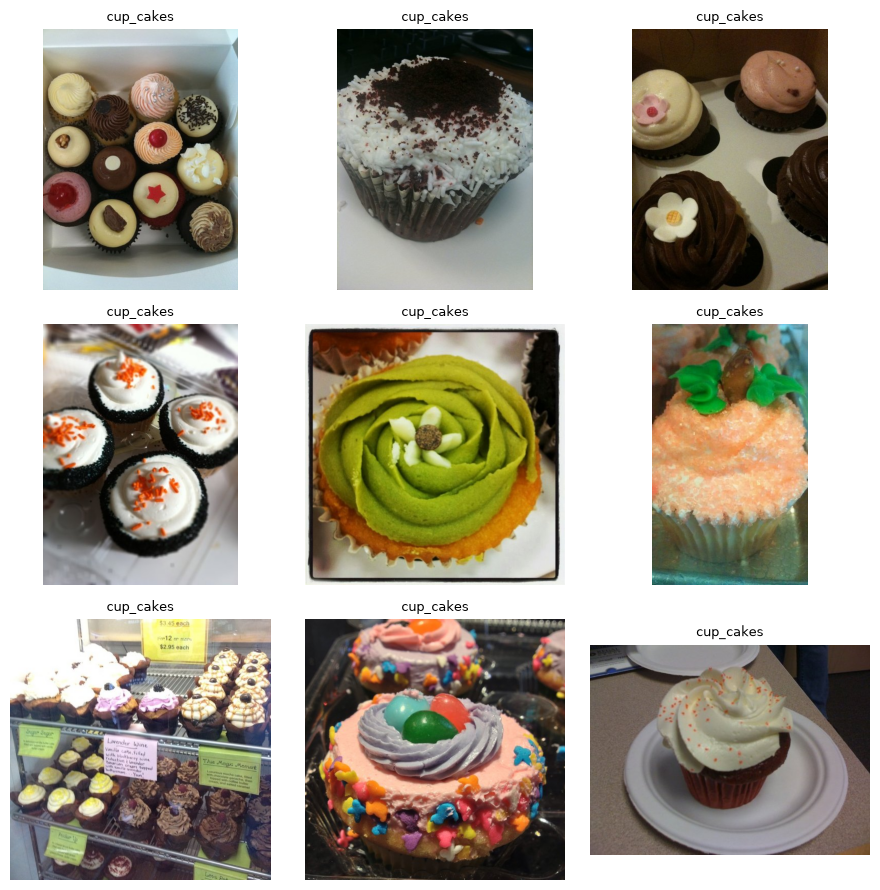

In [21]:
# Visualizing a sample of median RMS brightness food images
numeric_label  = LABELS_IDX_LOOKUP[LABELS_IDX_LOOKUP['Label Name'] == median_label]['Label Index'].iloc[0]
median_rms_images = [i for i in food_all if i['label'] == numeric_label]

n, cols, seed = 9, 3, 42
idxs = random.Random(seed).sample(range(len(median_rms_images)), n)
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = median_rms_images[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]], fontsize=9)
plt.tight_layout(); plt.show()

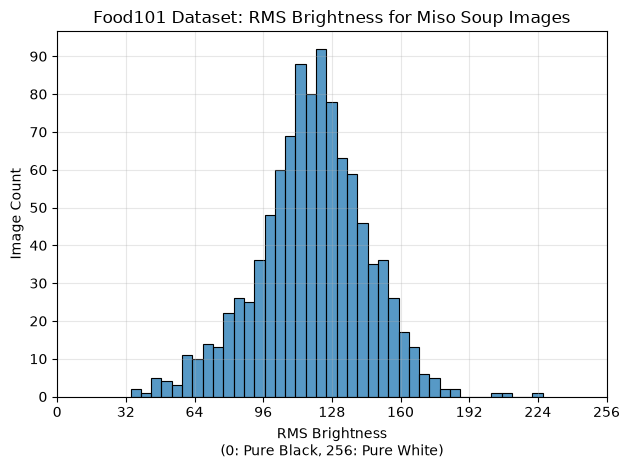

Min RMS Brightness       : 34.2031
Max RMS Brightness       : 226.3113
Median RMS Brightness    : 119.6407
RMS Brightness Range     : 192.1082


In [22]:
# Visualizing minimum RMS Brightness Food Label
min_brightness_idx   = rms_brightness_sorted.argmin()
min                  = rms_brightness_sorted.iloc[median_brightness_idx]
min_label            = rms_brightness_sorted.idxmin()

# min_brightness_idx, min_label, min

# Get label index, all images with label index value, and record their RMS brightness values
min_idx             = LABELS_IDX_LOOKUP[LABELS_IDX_LOOKUP['Label Name'] == min_label]['Label Index'].iloc[0]
min_images          = [i for i in food_all if i['label'] == min_idx]
rms_brightness_min  = [rms_brightness(i['image']) for i in min_images]

sns.histplot(rms_brightness_min, bins=40)
plt.title(f'Food101 Dataset: RMS Brightness for {min_label.replace("_", " ").title()} Images')
plt.ylabel('Image Count')
plt.xlabel('RMS Brightness\n(0: Pure Black, 256: Pure White)')

plt.xlim(0, 256)
plt.xticks(range(0, 257, 32))       # ticks every 32 (8 total ticks)
plt.yticks(range(0, 91, 10))        # frequency ticks 0-90 (checked between three RMS histograms to find common maximum y tick for easier comparability)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Min RMS Brightness       : {np.min(rms_brightness_min):.4f}')
print(f'Max RMS Brightness       : {np.max(rms_brightness_min):.4f}')
print(f'Median RMS Brightness    : {np.median(rms_brightness_min):.4f}')
print(f'RMS Brightness Range     : {(np.max(rms_brightness_min) - np.min(rms_brightness_min)):.4f}')

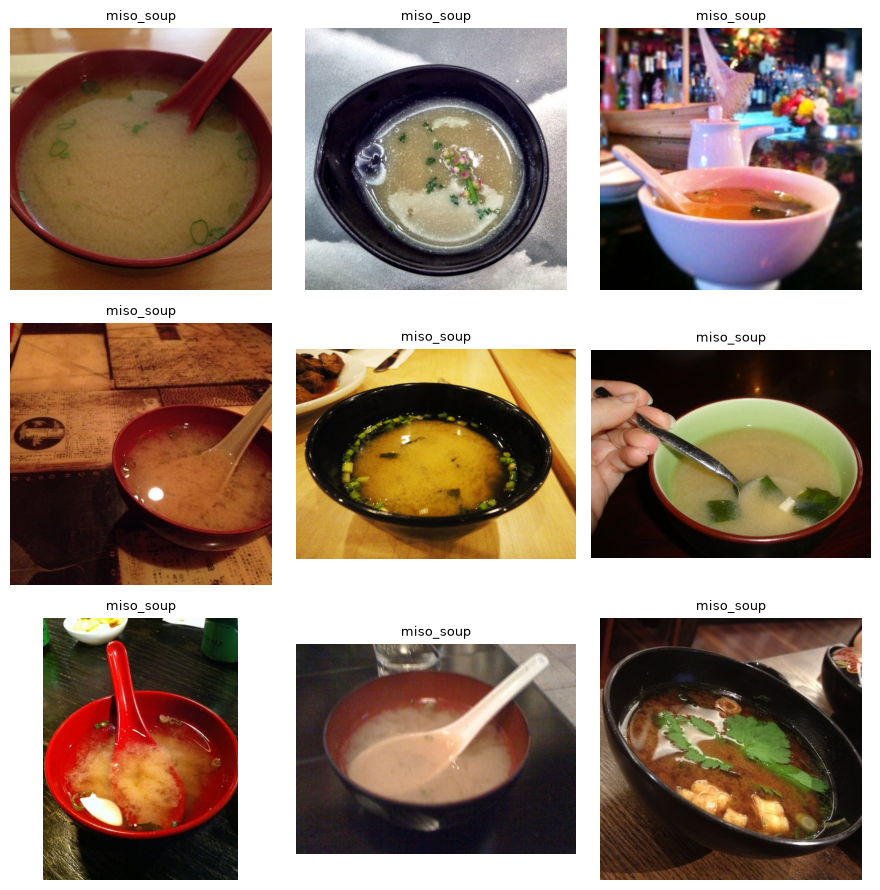

In [23]:
# Visualizing a sample of minimum RMS brightness food images
numeric_label  = LABELS_IDX_LOOKUP[LABELS_IDX_LOOKUP['Label Name'] == min_label]['Label Index'].iloc[0]
min_rms_images = [i for i in food_all if i['label'] == numeric_label]

n, cols, seed = 9, 3, 42
idxs = random.Random(seed).sample(range(len(min_rms_images)), n)
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = min_rms_images[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]], fontsize=9)
plt.tight_layout(); plt.show()

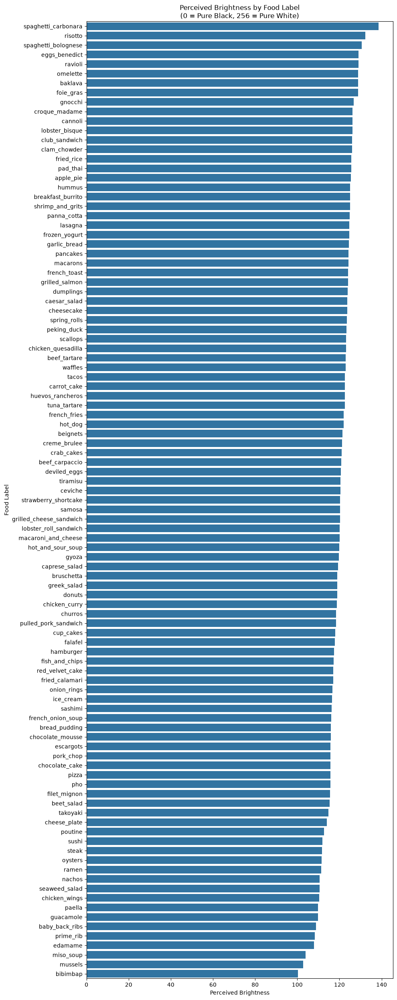

In [24]:
plt.figure(figsize=(10, 25))
sns.barplot(
    x=perceived_brightness_sorted.values,
    y=perceived_brightness_sorted.index,
    orient='h'
)
plt.title('Perceived Brightness by Food Label\n(0 = Pure Black, 256 = Pure White)')
plt.xlabel('Perceived Brightness')
plt.tight_layout()

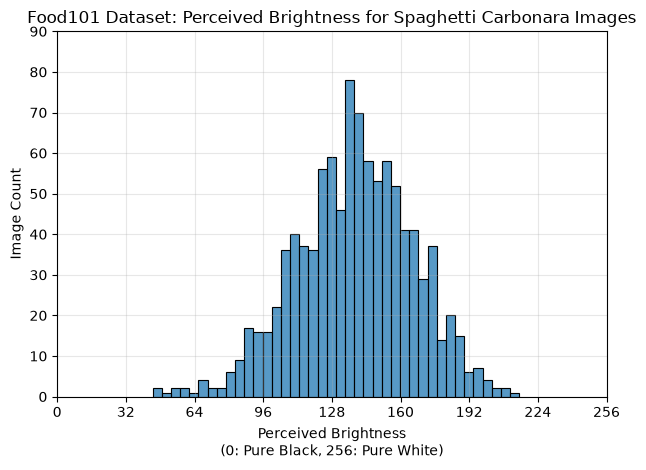

Min Perceived Brightness       : 44.4906
Max Perceived Brightness       : 215.3382
Median Perceived Brightness    : 139.0925
Perceived Brightness Range     : 170.8476


In [25]:
# Visualizing maximum Perceived Brightness Food Label
max_brightness_idx   = perceived_brightness_sorted.argmax()
max                  = perceived_brightness_sorted.iloc[max_brightness_idx]
max_label            = perceived_brightness_sorted.idxmax()

# max_brightness_idx, max_label, max

# Get label index, all images with label index value, and record their RMS brightness values
max_idx                   = LABELS_IDX_LOOKUP[LABELS_IDX_LOOKUP['Label Name'] == max_label]['Label Index'].iloc[0]
max_images                = [i for i in food_all if i['label'] == max_idx]
perceived_brightness_max  = [perceived_brightness(i['image']) for i in max_images]

sns.histplot(perceived_brightness_max, bins=40)
plt.title(f'Food101 Dataset: Perceived Brightness for {max_label.replace("_", " ").title()} Images')
plt.ylabel('Image Count')
plt.xlabel('Perceived Brightness\n(0: Pure Black, 256: Pure White)')

plt.xlim(0, 256)
plt.xticks(range(0, 257, 32))       # ticks every 32 (8 total ticks)
plt.yticks(range(0, 91, 10))        # frequency ticks 0-90 (checked between three perceived brightness histograms to find common maximum y tick for easier comparability)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Min Perceived Brightness       : {np.min(perceived_brightness_max):.4f}')
print(f'Max Perceived Brightness       : {np.max(perceived_brightness_max):.4f}')
print(f'Median Perceived Brightness    : {np.median(perceived_brightness_max):.4f}')
print(f'Perceived Brightness Range     : {(np.max(perceived_brightness_max) - np.min(perceived_brightness_max)):.4f}')

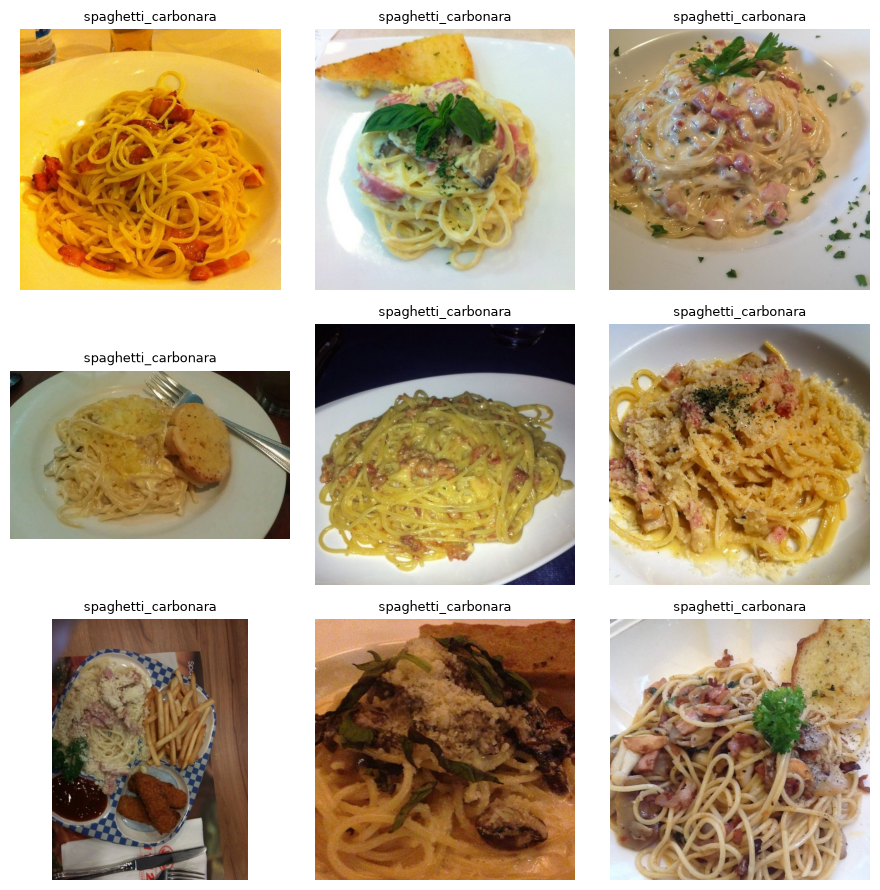

In [26]:
# Visualizing a sample of maximum perceived brightness food images
numeric_label                   = LABELS_IDX_LOOKUP[LABELS_IDX_LOOKUP['Label Name'] == max_label]['Label Index'].iloc[0]
min_perceived_brightness_images = [i for i in food_all if i['label'] == numeric_label]

n, cols, seed = 9, 3, 42
idxs = random.Random(seed).sample(range(len(min_perceived_brightness_images)), n)
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = min_perceived_brightness_images[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]], fontsize=9)
plt.tight_layout(); plt.show()

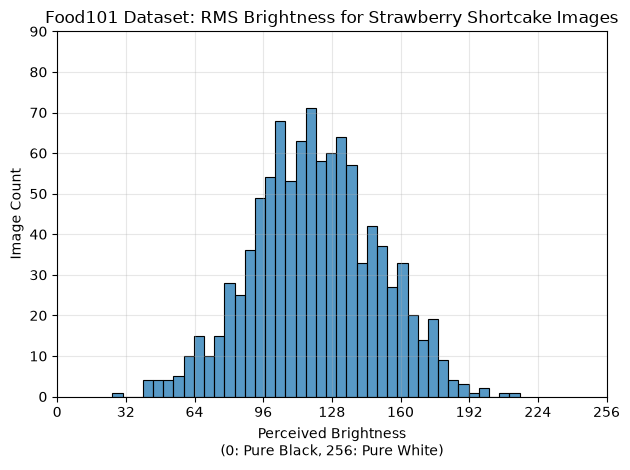

Min Perceived Brightness       : 25.7267
Max Perceived Brightness       : 215.4764
Median Perceived Brightness    : 119.6653
Perceived Brightness Range     : 189.7496


In [27]:
# Visualizing median Perceived Brightness Food Label
median_brightness_idx   = len(perceived_brightness_sorted) // 2
median                  = perceived_brightness_sorted.iloc[median_brightness_idx]
median_label            = perceived_brightness_sorted.index[median_brightness_idx]

# median_brightness_idx, median_label, median

# Get label index, all images with label index value, and record their RMS brightness values
median_idx                   = LABELS_IDX_LOOKUP[LABELS_IDX_LOOKUP['Label Name'] == median_label]['Label Index'].iloc[0]
median_images                = [i for i in food_all if i['label'] == median_idx]
perceived_brightness_median  = [perceived_brightness(i['image']) for i in median_images]

sns.histplot(perceived_brightness_median, bins=40)
plt.title(f'Food101 Dataset: RMS Brightness for {median_label.replace("_", " ").title()} Images')
plt.ylabel('Image Count')
plt.xlabel('Perceived Brightness\n(0: Pure Black, 256: Pure White)')

plt.xlim(0, 256)
plt.xticks(range(0, 257, 32))       # ticks every 32 (8 total ticks)
plt.yticks(range(0, 91, 10))        # frequency ticks 0-90 (checked between three perceived brightness histograms to find common maximum y tick for easier comparability)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Min Perceived Brightness       : {np.min(perceived_brightness_median):.4f}')
print(f'Max Perceived Brightness       : {np.max(perceived_brightness_median):.4f}')
print(f'Median Perceived Brightness    : {np.median(perceived_brightness_median):.4f}')
print(f'Perceived Brightness Range     : {(np.max(perceived_brightness_median) - np.min(perceived_brightness_median)):.4f}')

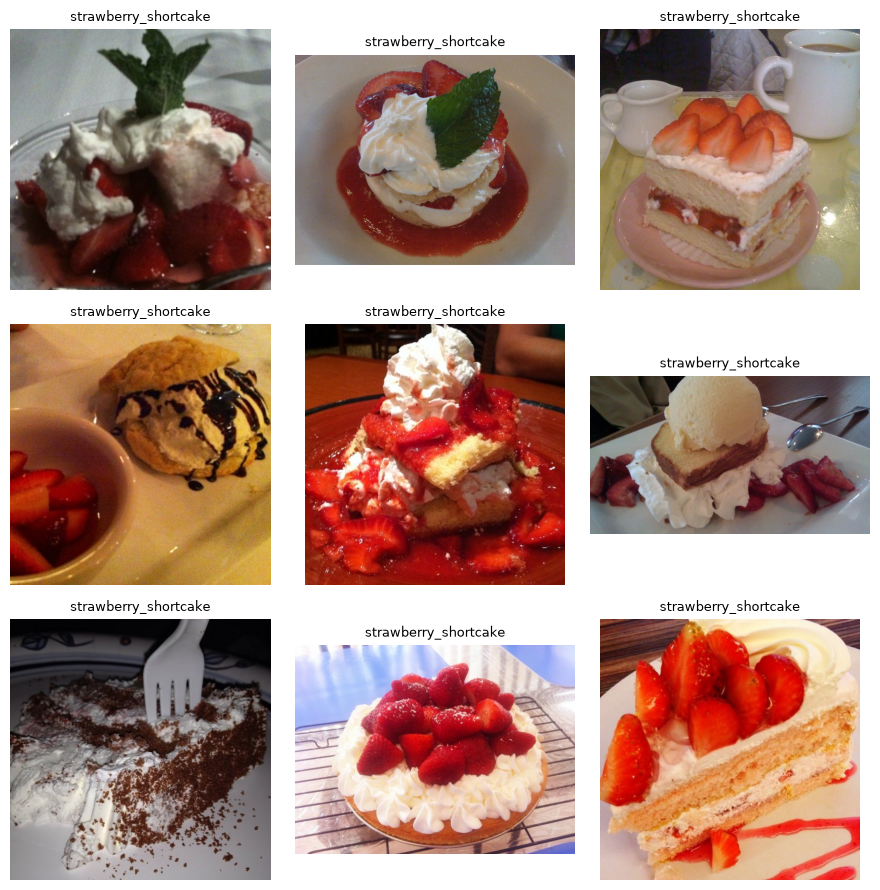

In [28]:
# Visualizing a sample of median perceived brightness food images
numeric_label                   = LABELS_IDX_LOOKUP[LABELS_IDX_LOOKUP['Label Name'] == median_label]['Label Index'].iloc[0]
med_perceived_brightness_images = [i for i in food_all if i['label'] == numeric_label]

n, cols, seed = 9, 3, 42
idxs = random.Random(seed).sample(range(len(med_perceived_brightness_images)), n)
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = med_perceived_brightness_images[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]], fontsize=9)
plt.tight_layout(); plt.show()

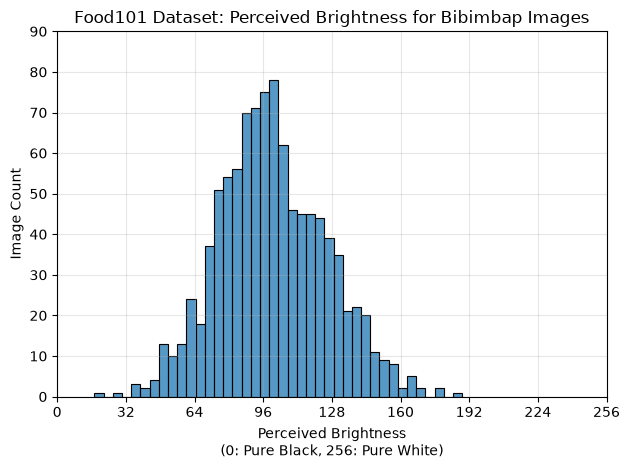

Min Perceived Brightness       : 17.3930
Max Perceived Brightness       : 188.7650
Median Perceived Brightness    : 98.7028
Perceived Brightness Range     : 171.3721


In [29]:
# Visualizing minimum Perceived Brightness Food Label
min_brightness_idx   = perceived_brightness_sorted.argmin()
min                  = perceived_brightness_sorted.iloc[min_brightness_idx]
min_label            = perceived_brightness_sorted.idxmin()

# min_brightness_idx, min_label, min

# Get label index, all images with label index value, and record their RMS brightness values
min_idx                   = LABELS_IDX_LOOKUP[LABELS_IDX_LOOKUP['Label Name'] == min_label]['Label Index'].iloc[0]
min_images                = [i for i in food_all if i['label'] == min_idx]
perceived_brightness_min  = [perceived_brightness(i['image']) for i in min_images]

sns.histplot(perceived_brightness_min, bins=40)
plt.title(f'Food101 Dataset: Perceived Brightness for {min_label.replace("_", " ").title()} Images')
plt.ylabel('Image Count')
plt.xlabel('Perceived Brightness\n(0: Pure Black, 256: Pure White)')

plt.xlim(0, 256)
plt.xticks(range(0, 257, 32))       # ticks every 32 (8 total ticks)
plt.yticks(range(0, 91, 10))        # frequency ticks 0-90 (checked between three perceived brightness histograms to find common maximum y tick for easier comparability)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Min Perceived Brightness       : {np.min(perceived_brightness_min):.4f}')
print(f'Max Perceived Brightness       : {np.max(perceived_brightness_min):.4f}')
print(f'Median Perceived Brightness    : {np.median(perceived_brightness_min):.4f}')
print(f'Perceived Brightness Range     : {(np.max(perceived_brightness_min) - np.min(perceived_brightness_min)):.4f}')

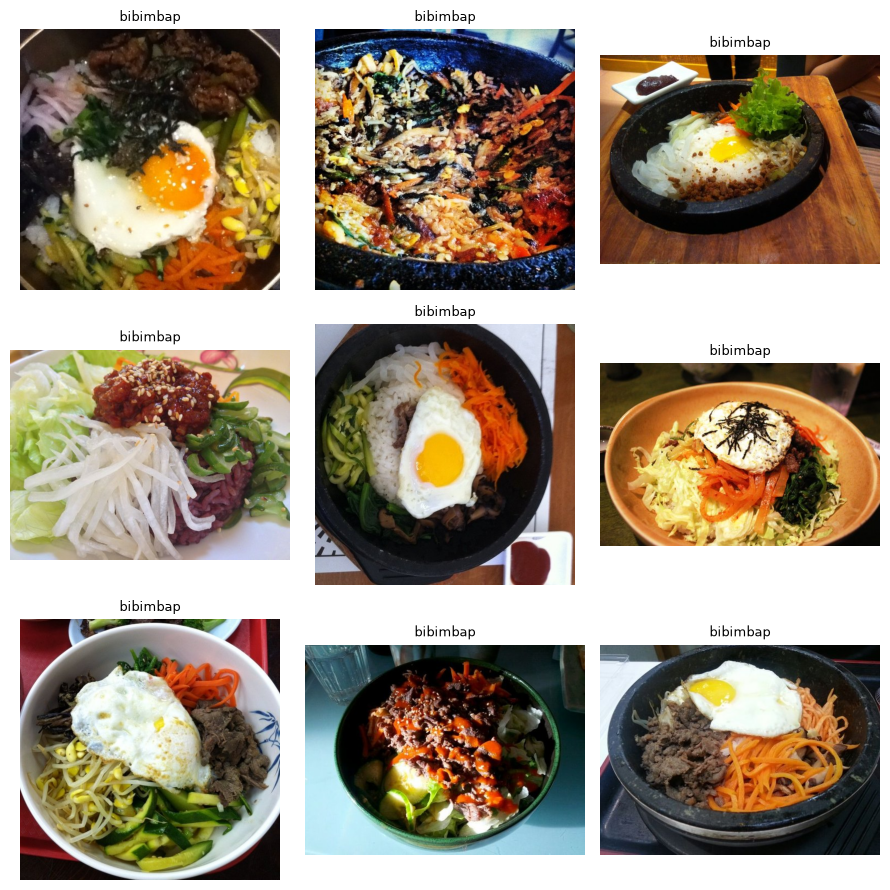

In [30]:
# Visualizing a sample of minimum perceived brightness food images
numeric_label                   = LABELS_IDX_LOOKUP[LABELS_IDX_LOOKUP['Label Name'] == min_label]['Label Index'].iloc[0]
min_perceived_brightness_images = [i for i in food_all if i['label'] == numeric_label]

n, cols, seed = 9, 3, 42
idxs = random.Random(seed).sample(range(len(min_perceived_brightness_images)), n)
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = min_perceived_brightness_images[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]], fontsize=9)
plt.tight_layout(); plt.show()

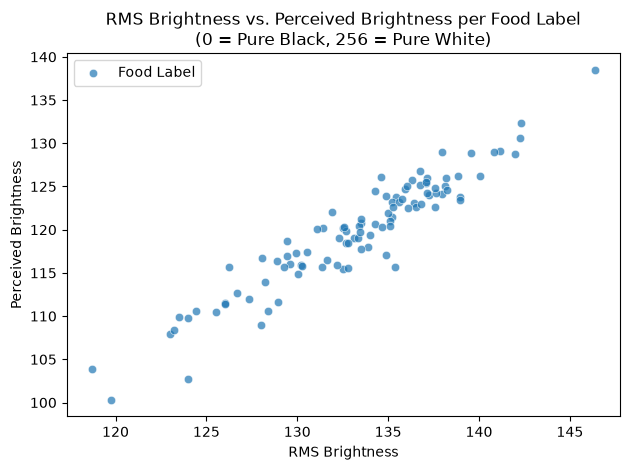

In [31]:
sns.scatterplot(
    x=food_label_brightness['RMS Brightness'],
    y=food_label_brightness['Perceived Brightness'],
    alpha=0.7
)
plt.title('RMS Brightness vs. Perceived Brightness per Food Label\n(0 = Pure Black, 256 = Pure White)')
plt.legend(['Food Label'])
plt.tight_layout()
plt.show()

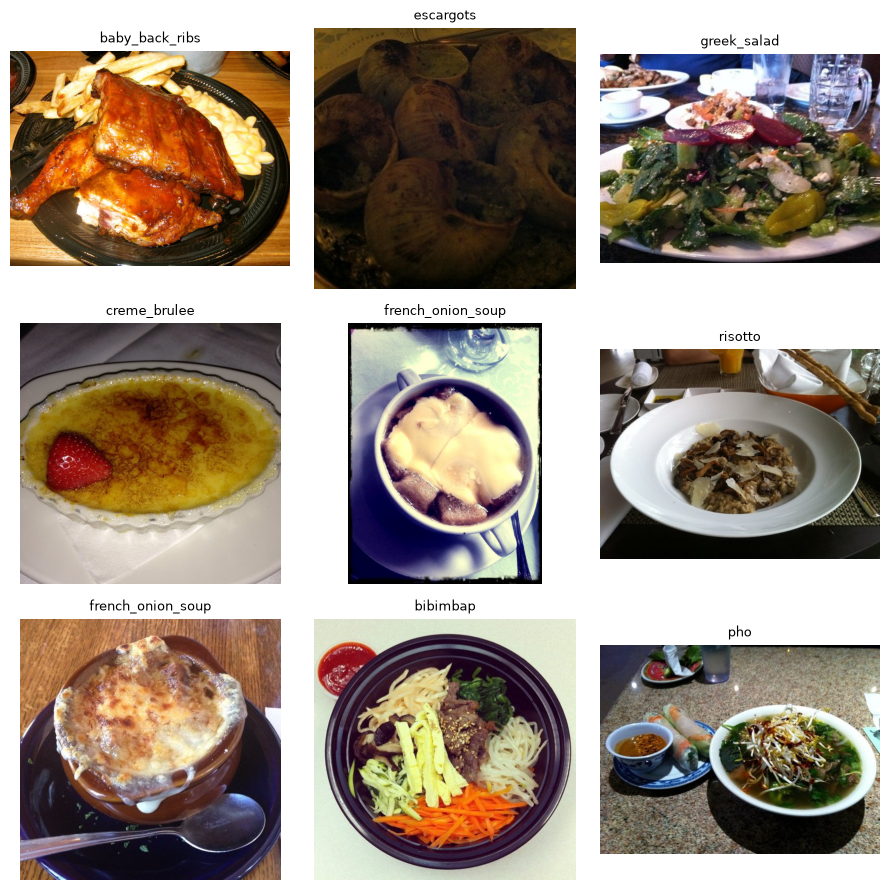

In [32]:
# View a new random sample of images
n, cols, seed = 9, 3, 476
idxs = random.Random(seed).sample(range(len(food_all)), n)
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = food_all[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]], fontsize=9)
plt.tight_layout(); plt.show()

In [7]:
# Using cleanvision to inspect dataset quality (checks duplicates, darkness, lightness, etc.)
from cleanvision import Imagelab

# ignore warnings for better notebook readability
#       Used Gemini: https://share.gemini.google/C0l61UHKiN7o
os.environ["PYTHONWARNINGS"] = "ignore"

imagelab = Imagelab(hf_dataset=food_all, image_key='image')
imagelab.find_issues()
# imagelab.report()

# Source for checking data quality: https://cleanvision.readthedocs.io/en/latest/tutorials/huggingface_dataset.html

Checking for dark, light, odd_aspect_ratio, low_information, exact_duplicates, near_duplicates, blurry, grayscale, odd_size images ...


Computing scores:   0%|          | 0/101000 [00:00<?, ?it/s]

Computing hashes:   0%|          | 0/101000 [00:00<?, ?it/s]

Issue checks completed. 452 issues found in the dataset. To see a detailed report of issues found, use imagelab.report().


In [34]:
imagelab.issues.head()

,odd_size_score,is_odd_size_issue,odd_aspect_ratio_score,is_odd_aspect_ratio_issue,low_information_score,is_low_information_issue,light_score,is_light_issue,grayscale_score,is_grayscale_issue,dark_score,is_dark_issue,blurry_score,is_blurry_issue,exact_duplicates_score,is_exact_duplicates_issue,near_duplicates_score,is_near_duplicates_issue
0,0.928571,False,0.750000,False,0.889266,False,0.947072,False,1,False,0.751984,False,0.429014,False,1.0,False,1.0,False
1,0.928571,False,1.000000,False,0.937820,False,0.874974,False,1,False,0.971737,False,0.474234,False,1.0,False,1.0,False
2,0.927368,False,0.748047,False,0.939400,False,0.936729,False,1,False,0.991625,False,0.480232,False,1.0,False,1.0,False
3,0.884220,False,0.679688,False,0.903561,False,0.830981,False,1,False,0.892534,False,0.471804,False,1.0,False,1.0,False
4,0.928571,False,1.000000,False,0.917898,False,0.691988,False,1,False,0.991697,False,0.459467,False,1.0,False,1.0,False


In [35]:
# Check for exact and near duplicate sets
exact_duplicates_idx = imagelab.issues[imagelab.issues['is_exact_duplicates_issue'] == True]
total_exact_duplicates = len(exact_duplicates_idx)
exact_duplicate_sets_idx = imagelab.info['exact_duplicates']['sets']
print(f'There are {len(exact_duplicate_sets_idx)} duplicate image sets in the food101 dataset')

near_duplicates_idx = (
    imagelab.issues.query('is_near_duplicates_issue')
    .sort_values(by='near_duplicates_score', ascending=False)
    .index.tolist()
)
total_near_duplicates = len(near_duplicates_idx)
near_duplicate_sets_idx = imagelab.info['near_duplicates']['sets']
print(f'There are {len(near_duplicate_sets_idx)} near duplicate image sets in the food101 dataset')

There are 58 duplicate image sets in the food101 dataset
There are 46 near duplicate image sets in the food101 dataset


### Non-food images that are also mislabeled

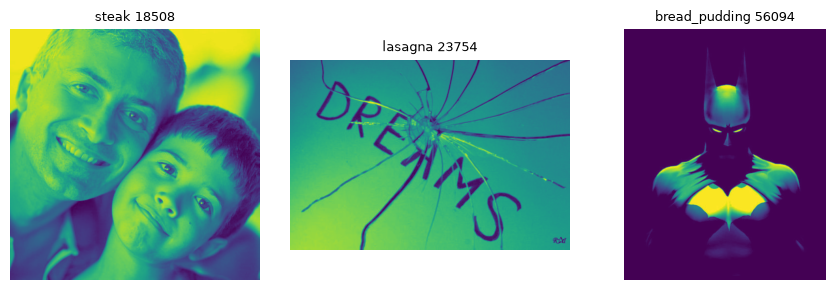

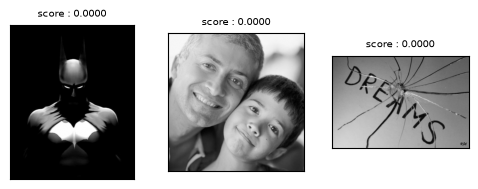

In [36]:
# Check grayscale images since some art not food
grayscale_imgs = imagelab.issues[imagelab.issues['is_grayscale_issue'] == True].index

# Visualize all 3 grayscale images and its labels
n, cols, seed = 3, 3, 476
idxs = grayscale_imgs
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = food_all[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

imagelab.visualize(issue_types=["grayscale"])

Notes:

- Non-food items have incorrect food labels. Unsure why these items were flagged for grayscale issues when the raw images are colored but cleanvision detected them as grayscale.

These should likely be dropped, unless there are significant more non-food images to justify adding a singular non-food label.

In [8]:
# Keep track of mislabeled images for potential removal/label changes
MISLABELED = [
    {
        'Index'                 : 18508,
        'Raw Label'             : 'steak',
        'Actual Description'    : 'people'
    },
    {
        'Index'                 : 23754,
        'Raw Label'             : 'lasagna',
        'Actual Description'    : 'broken glass and text'
    },
    {
        'Index'                 : 56094,
        'Raw Label'             : 'bread_pudding',
        'Actual Description'    : 'batman'
    }
]

MISLABELED_IMAGES_DF = pd.DataFrame(MISLABELED)
MISLABELED_IMAGES_DF

,Index,Raw Label,Actual Description
0,18508,steak,people
1,23754,lasagna,broken glass and text
2,56094,bread_pudding,batman


### Dark Images

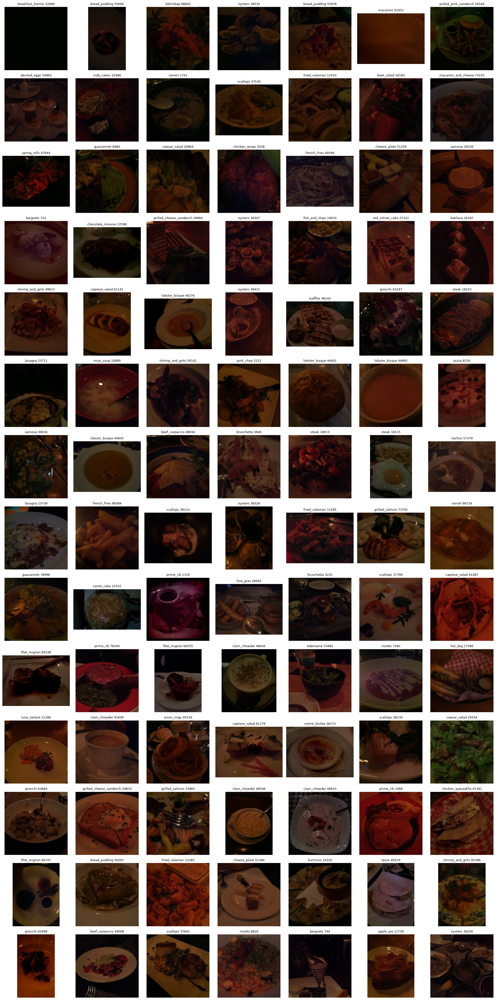

In [38]:
# Check dark images (sorted darkest to lightest)
dark_imgs = imagelab.issues[imagelab.issues['is_dark_issue'] == True].sort_values(by='dark_score').index
# len(dark_imgs) / 14

# Visualize all 98 dark images and its labels
n, cols, seed = 98, 7, 476
idxs = dark_imgs
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = food_all[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

Notes:

- ``breakfast_burrito (index: 32090)`` does not seem usable since it is almost completely black.
- ``macarons 61951`` does not seem usable since it is blurry and doesn't look like macarons.

Overall, lighting could potentially be adjusted/normalized when possible or drop specific samples and account for stratified split to avoid bias.

In [9]:
breakfast_burrito = pd.DataFrame(
    [{
        'Index'                 : 32090,
        'Raw Label'             : 'breakfast_burrito',
        'Actual Description'    : 'completely black, potential qualified for removal'
    }]
)

macarons = pd.DataFrame(
    [{
        'Index'                 : 61951,
        'Raw Label'             : 'macarons',
        'Actual Description'    : 'too blurry, unlike macarons'
    }]
)

MISLABELED_IMAGES_DF = pd.concat([MISLABELED_IMAGES_DF, breakfast_burrito, macarons])
MISLABELED_IMAGES_DF


,Index,Raw Label,Actual Description
0,18508,steak,people
1,23754,lasagna,broken glass and text
2,56094,bread_pudding,batman
0,32090,breakfast_burrito,"completely black, potential qualified for removal"
0,61951,macarons,"too blurry, unlike macarons"


### Odd aspect ratios

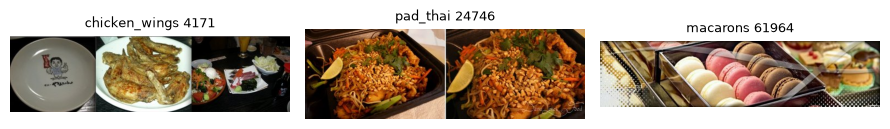

In [40]:
# Check odd aspect ratio images
odd_aspect_ratio_imgs = imagelab.issues[imagelab.issues['is_odd_aspect_ratio_issue'] == True].index

# Visualize all 3 odd aspect ratio images and its labels
n, cols, seed = 3, 3, 476
idxs = odd_aspect_ratio_imgs
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = food_all[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

Notes:

- interesting cases with these images because the first 2 images are multi-image compositions which could result in some issues potentially

Potential options could be to crop the images for the first 2 images so that it only includes one example of it: 
  - 1st should include the middle image within itself since thats where the chicken wings seem to be
  - 2nd should include either the first or second image within itself since they are just different angles

### Check issues report per class label

In [41]:
# update copy of results with class label index and name
issues_df               = imagelab.issues.copy()
issues_df['label_idx']  = [food_all[i]['label'] for i in range(len(issues_df))]
issues_df['label_name'] = issues_df['label_idx'].map(lambda i: food_label_names[i])
issues_df.head()

,odd_size_score,is_odd_size_issue,odd_aspect_ratio_score,is_odd_aspect_ratio_issue,low_information_score,is_low_information_issue,light_score,is_light_issue,grayscale_score,is_grayscale_issue,dark_score,is_dark_issue,blurry_score,is_blurry_issue,exact_duplicates_score,is_exact_duplicates_issue,near_duplicates_score,is_near_duplicates_issue,label_idx,label_name
0,0.928571,False,0.750000,False,0.889266,False,0.947072,False,1,False,0.751984,False,0.429014,False,1.0,False,1.0,False,6,beignets
1,0.928571,False,1.000000,False,0.937820,False,0.874974,False,1,False,0.971737,False,0.474234,False,1.0,False,1.0,False,6,beignets
2,0.927368,False,0.748047,False,0.939400,False,0.936729,False,1,False,0.991625,False,0.480232,False,1.0,False,1.0,False,6,beignets
3,0.884220,False,0.679688,False,0.903561,False,0.830981,False,1,False,0.892534,False,0.471804,False,1.0,False,1.0,False,6,beignets
4,0.928571,False,1.000000,False,0.917898,False,0.691988,False,1,False,0.991697,False,0.459467,False,1.0,False,1.0,False,6,beignets


In [42]:
# Isolate issue flags
issue_cols = [i for i in issues_df.columns.tolist() if not i.startswith('label') and i.endswith('_issue')]

# Get total images per issue by food label class
issues_by_class = issues_df.groupby('label_name')[issue_cols].agg('sum')

# Get total issues per food label class
issues_by_class['total_issues'] = issues_by_class[issue_cols].sum(axis=1)

# Sort by most issues descending order
issues_by_class = issues_by_class.sort_values(by='total_issues', ascending=False)

# Only show food class labels that have at least 1 issue
imgs_with_issues = issues_by_class[issues_by_class['total_issues'] > 0]

print(f'Out of {len(food_label_names)} food label classes, there are {len(imgs_with_issues)} food label classes with at least 1 image quality issue.')
imgs_with_issues

Out of 101 food label classes, there are 92 food label classes with at least 1 image quality issue.


,is_odd_size_issue,is_odd_aspect_ratio_issue,is_low_information_issue,is_light_issue,is_grayscale_issue,is_dark_issue,is_blurry_issue,is_exact_duplicates_issue,is_near_duplicates_issue,total_issues
label_name,,,,,,,,,,
prime_rib,0,0,0,0,0,3,0,5,10,18
miso_soup,0,0,0,0,0,1,16,0,0,17
clam_chowder,0,0,0,0,0,4,9,2,0,15
gnocchi,0,0,0,0,0,3,6,2,2,13
fried_calamari,0,0,0,0,0,3,1,2,4,10
...,...,...,...,...,...,...,...,...,...,...
gyoza,0,0,0,0,0,0,1,0,0,1
donuts,0,0,0,0,0,0,1,0,0,1
frozen_yogurt,0,0,0,0,0,0,1,0,0,1


In [43]:
# function for inspecting specific food label images by its issue type
def inspect_img_issues(class_name, issue_type):
    # Filter issues_df rows by class and issue type
    mask   = ((issues_df['label_name'] == class_name) & (issues_df[issue_type] == True))
    subset = issues_df[mask]

    # get image indices
    indices = subset.index.tolist()
    print(f"Found {len(indices)} images for class '{class_name}' with issue '{issue_type}'.")

    if len(indices) == 0:
        print(f"No images found for '{class_name}' with issue '{issue_type}'.")
        return

    # Display images with maximum 6 images per row
    num_images = len(indices)
    n, cols = num_images, 6
    idxs = indices
    rows = math.ceil(n/cols)

    plt.figure(figsize=(3*cols, 3*rows))
    for i, idx in enumerate(idxs, 1):
        ex = food_all[idx]
        plt.subplot(rows, cols, i)
        plt.imshow(ex["image"]); plt.axis("off")
        plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
    plt.suptitle(f'Class: {class_name} | Issue: {issue_type}', fontweight='bold')
    plt.tight_layout(); plt.show()

In [44]:
odd_size            = issues_df[issues_df['is_odd_size_issue'] > 0]
odd_aspect_ratio    = issues_df[issues_df['is_odd_aspect_ratio_issue'] > 0]
low_info            = issues_df[issues_df['is_low_information_issue'] > 0]
light               = issues_df[issues_df['is_light_issue'] > 0]
grayscale           = issues_df[issues_df['is_grayscale_issue'] > 0]
dark                = issues_df[issues_df['is_dark_issue'] > 0]
blurry              = issues_df[issues_df['is_blurry_issue'] > 0]
exact_dup           = issues_df[issues_df['is_exact_duplicates_issue'] > 0]
near_dup            = issues_df[issues_df['is_near_duplicates_issue'] > 0]

In [45]:
# Display total image count per class for each issue type
issues = {
    'Odd Size'              : odd_size,
    'Odd Aspect Ratio'      : odd_aspect_ratio,
    'Low Information'       : low_info,
    'Light'                 : light,
    'Grayscale'             : grayscale,
    'Dark'                  : dark,
    'Blurry'                : blurry,
    'Exact Duplicate'       : exact_dup,
    'Near Duplicate'        : near_dup
}

print('----     NUMBER OF IMAGES PER CLASS BY ISSUE TYPE    ----\n')

for title, type in issues.items():
    print(f'                    --- {title} ---')
    counts = type['label_name'].value_counts()

    # only display counts that are at least 1
    if len(counts) > 0:
        print(counts.to_string())
    else:
        print('None found.')
    print("\n" + "="*60 + "\n")

----     NUMBER OF IMAGES PER CLASS BY ISSUE TYPE    ----

                    --- Odd Size ---
None found.


                    --- Odd Aspect Ratio ---
label_name
chicken_wings    1
pad_thai         1
macarons         1


                    --- Low Information ---
label_name
bread_pudding    1


                    --- Light ---
None found.


                    --- Grayscale ---
label_name
steak            1
lasagna          1
bread_pudding    1


                    --- Dark ---
label_name
oysters                    5
scallops                   5
lobster_bisque             4
clam_chowder               4
fried_calamari             3
steak                      3
bread_pudding              3
shrimp_and_grits           3
filet_mignon               3
caprese_salad              3
gnocchi                    3
prime_rib                  3
beef_carpaccio             2
lasagna                    2
grilled_cheese_sandwich    2
samosa                     2
french_fries               2
cheese

In [46]:
def inspect_all_classes_for_img_issue(issue_type):
    """
        Loops through each food class that has at least 1 instance of the issue_type 
        and loops through inspect_img_issues function.
    """
    # filter images with for specific issue type
    subset = issues_df[issues_df[issue_type] == True]

    # ends function if there are no images with specified issue type
    if len(subset) == 0:
        print(f'No images found for issue: {issue_type}')
        return

    # filter for classes with at least 1 image per issue type
    class_counts  = subset['label_name'].value_counts()
    valid_classes = class_counts[class_counts >= 1]

    # ends function if there are no food classes with images for specified issue type
    if len(valid_classes) == 0:
        print(f'No food classes have images for issue: {issue_type}')
        return

    print("="*100 + 
          "\n" + 
          f"==========      Found {len(valid_classes)} food classes for issue: {issue_type}     ==========" +
          "\n" +
          "="*100 + 
          "\n"
    )

    # loop through each class and display images
    for class_name, count in valid_classes.items():
        print(f"\n              Class: {class_name}     |       # Images: {count}")
        inspect_img_issues(class_name=class_name, issue_type=issue_type)

In [ ]:
# DISPLAY IMAGE ISSUES PER CLASS PER ISSUE TYPE
inspect_all_classes_for_img_issue('is_odd_aspect_ratio_issue')
inspect_all_classes_for_img_issue('is_low_information_issue')
inspect_all_classes_for_img_issue('is_grayscale_issue')
inspect_all_classes_for_img_issue('is_dark_issue')
inspect_all_classes_for_img_issue('is_blurry_issue')
inspect_all_classes_for_img_issue('is_exact_duplicates_issue')
inspect_all_classes_for_img_issue('is_near_duplicates_issue')

# cleared outputs to save memory

In [10]:
hot_dog = pd.DataFrame(
    [{
        'Index'                 : 17453,
        'Raw Label'             : 'hot_dog',
        'Actual Description'    : 'photo of person'
    },
    {
        'Index'                 : 17482,
        'Raw Label'             : 'hot_dog',
        'Actual Description'    : 'hot dog style bun with veggies and meat, unsure if it is a hot dog'
    },
    {
        'Index'                 : 17665,
        'Raw Label'             : 'hot_dog',
        'Actual Description'    : 'hot dog style bun with veggies and meat, unsure if it is a hot dog'
    }]
)

hamburgers = pd.DataFrame(
    [{
        'Index'                 : 2781,
        'Raw Label'             : 'hamburger',
        'Actual Description'    : 'photo of menu with burger option'
    },
    {
        'Index'                 : 2982,
        'Raw Label'             : 'hamburger',
        'Actual Description'    : 'photo of menu with burger option'
    }
    ]
)

mussels = pd.DataFrame(
    [{
        'Index'                 : 34653,
        'Raw Label'             : 'mussels',
        'Actual Description'    : 'photo of menu with mussels option'
    },
    {
        'Index'                 : 35107,
        'Raw Label'             : 'mussels',
        'Actual Description'    : 'photo of menu with mussels option'
    }
    ]
)

prime_rib = pd.DataFrame(
    [{
        'Index'                 : 1181,
        'Raw Label'             : 'prime_rib',
        'Actual Description'    : 'photo of menu with prime rib sandwich options'
    },
    {
        'Index'                 : 955,
        'Raw Label'             : 'prime_rib',
        'Actual Description'    : 'photo of menu with prime rib sandwich options'
    },
    {
        'Index'                 : 755,
        'Raw Label'             : 'prime_rib',
        'Actual Description'    : 'photo of chef with some meat in background, unclear its prime ribs'
    },
    {
        'Index'                 : 1390,
        'Raw Label'             : 'prime_rib',
        'Actual Description'    : 'photo of chef with some meat in background, unclear its prime ribs'
    }
    ]
)

chicken_wings = pd.DataFrame(
    [{
        'Index'                 : 3894,
        'Raw Label'             : 'chicken_wings',
        'Actual Description'    : 'photo of chicken wings and french fries'
    },
    {
        'Index'                 : 4245,
        'Raw Label'             : 'chicken_wings',
        'Actual Description'    : 'photo of chicken wings and french fries'
    },
    {
        'Index'                 : 4171,
        'Raw Label'             : 'chicken_wings',
        'Actual Description'    : '3 photo composite: empty plate, chicken wings, different meal.'
    }
    ]
)

pad_thai = pd.DataFrame(
    [{
        'Index'                 : 24746,
        'Raw Label'             : 'pad_thai',
        'Actual Description'    : '2 photo composite: both plates of pad thai'
    }]
)

waffles = pd.DataFrame(
    [{
        'Index'                 : 46123,
        'Raw Label'             : 'waffles',
        'Actual Description'    : 'photo of waffles mostly covered up by whipped cream'
    },
    {
        'Index'                 : 91235,
        'Raw Label'             : 'waffles',
        'Actual Description'    : 'photo of waffles mostly covered up by whipped cream'
    }
    ]
)

pancakes = pd.DataFrame(
    [{
        'Index'                 : 22486,
        'Raw Label'             : 'pancakes',
        'Actual Description'    : 'photo of two plates. top half of image could be pancakes covered in a sauce but it is unclear.'
    }]
)

grilled_cheese_sandwich = pd.DataFrame(
    [{
        'Index'                 : 29883,
        'Raw Label'             : 'grilled_cheese_sandwich',
        'Actual Description'    : 'photo of a sub and some fried food. Not grilled cheese.'
    }]
)

steak = pd.DataFrame(
    [{
        'Index'                 : 18115,
        'Raw Label'             : 'steak',
        'Actual Description'    : 'photo of fried egg and chips. Egg may be on top of a steak, but very difficult to tell.'
    }]
)

pho = pd.DataFrame(
    [{
        'Index'                 : 50878,
        'Raw Label'             : 'pho',
        'Actual Description'    : 'close up photo of noodles. Hard to tell if it is pho or ramen.'
    }]
)

clam_chowder = pd.DataFrame(
    [{
        'Index'                 : 48145,
        'Raw Label'             : 'clam_chowder',
        'Actual Description'    : 'some kind of fruit'
    }]
)

nachos = pd.DataFrame(
    [{
        'Index'                 : 57379,
        'Raw Label'             : 'nachos',
        'Actual Description'    : 'dish with chips on the side, not nachos.'
    }]
)

IMAGE_ISSUES_DF = pd.concat([MISLABELED_IMAGES_DF, hot_dog, hamburgers, mussels, prime_rib, chicken_wings, pad_thai, waffles, pancakes, grilled_cheese_sandwich, steak, pho, clam_chowder, nachos])

In [11]:
# Preview of image indices, label, and description for some issues manually found from EDA and cleanvision reports
IMAGE_ISSUES_DF

,Index,Raw Label,Actual Description
0,18508,steak,people
1,23754,lasagna,broken glass and text
2,56094,bread_pudding,batman
0,32090,breakfast_burrito,"completely black, potential qualified for removal"
0,61951,macarons,"too blurry, unlike macarons"
0,17453,hot_dog,photo of person
1,17482,hot_dog,"hot dog style bun with veggies and meat, unsur..."
2,17665,hot_dog,"hot dog style bun with veggies and meat, unsur..."
0,2781,hamburger,photo of menu with burger option
1,2982,hamburger,photo of menu with burger option


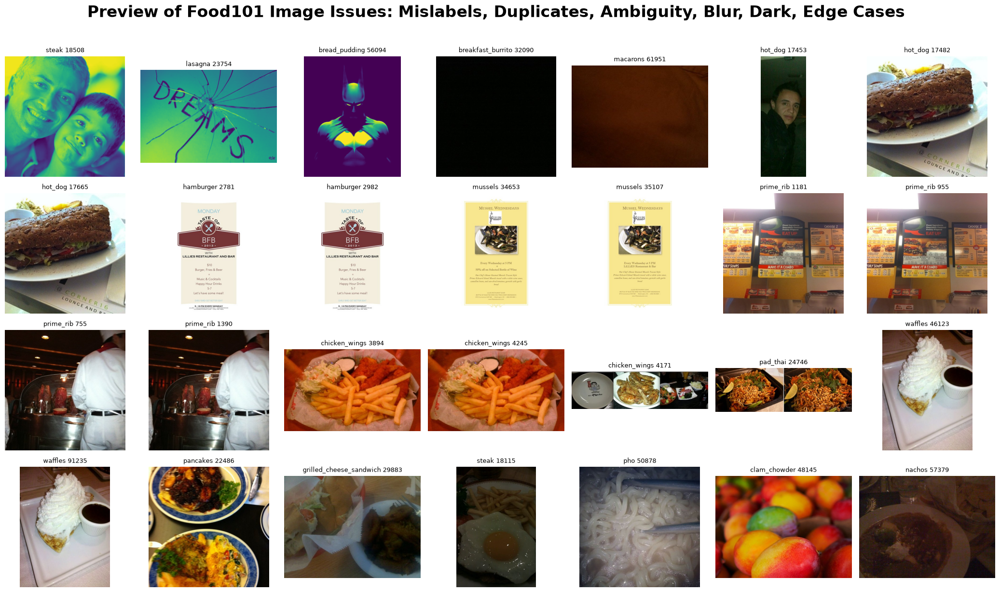

In [50]:
# Visualize all 3 grayscale images and its labels
n, cols, seed = len(IMAGE_ISSUES_DF), 7, 476
idxs = IMAGE_ISSUES_DF['Index'].tolist()
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = food_all[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)

plt.suptitle('Preview of Food101 Image Issues: Mislabels, Duplicates, Ambiguity, Blur, Dark, Edge Cases', fontsize=24, fontweight='bold', y=1.02)
plt.tight_layout(); plt.show()

### Graded Questions (2 pts each)

Write **a coherent response of approximately 100–150 words per question** in its designated Python answer variable. Be specific to your dataset and refer to relevant code, tables, plots, and numerical results where appropriate. Put supporting code in the programming cells rather than in your written answers. These word counts indicate the expected depth of explanation, not rigid limits.

A. **Dataset Summary:**  
   Describe your chosen dataset  (as if explaining to your *clueless boss* what you are working on).
   - State which dataset you are going to use.   
   - What kind of data does it contain (images or text)?  
   - How many samples and classes are there?  
   - What is the task you’ll perform (classification into what categories)?
   - What is the potential business use for this dataset?

In [51]:
# Your answer here, NOT in the next cell

a1a = """
I am going to use the food101 dataset, which is a large dataset of 101 food categories each with 1000 images. 
There are a total of 101000 samples with 101 classes. 
Using this dataset, I will perform multi-class classification to correctly identify the image's food category. 
The potential business use case for this dataset could be to utilize image recognition as part of a search for recipes. 
For example, a user could photograph a meal they enjoyed when eating at a restaurant and they could input the image into a system to identify the food and the software could return a recipe to make that meal at home.
"""

In [52]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1a = {a1a}")

a1a = 
I am going to use the food101 dataset, which is a large dataset of 101 food categories each with 1000 images. 
There are a total of 101000 samples with 101 classes. 
Using this dataset, I will perform multi-class classification to correctly identify the image's food category. 
The potential business use case for this dataset could be to utilize image recognition as part of a search for recipes. 
For example, a user could photograph a meal they enjoyed when eating at a restaurant and they could input the image into a system to identify the food and the software could return a recipe to make that meal at home.



B. **Initial Observations:**  
   What stood out to you from your EDA?  
   - Did you notice any imbalanced or ambiguous classes?  
   - Any patterns, anomalies, or potential sources of bias?  
   - For images: note any variation in lighting, composition, or color.  
   - For text: mention redundancy, topic overlap, or very short examples.

In [53]:
# Your answer here, NOT in the next cell

a1b = """
While the raw data is completely balanced (1000 images per class), there are images with incorrect labels such as the batman and image of two people which were labeled as 'bread_pudding' and 'steak'. 
Other issues found were very dark images that will become an issue. The images vary in brightness, saturation, sharpness, etc.
Another issue potentially could be with how the photos are composed. For example, there is an image of mussels on a menu while most images are just photos of the food on a plate or a close-up shot. 
One or two issues won't lead to significant issues for classification accuracy, but if there is a class that has a lot of diversity in how the composition looks it might make it difficult for machine learning models to determine a distinct pattern for that class.
There are also some ambiguous images in the dataset that are difficult to tell if they are correctly labeled or not. For example, there's an image labeled steak but the main focal point is on a fried egg with potentially steak underneath but it is difficult to tell. 
Another example is image 3894 (as seen in the Preview of Food101 Image Issues visual above the written response cells) which is labeled as chicken wings but it is a plate of chicken wings and french fries. 
Since the dataset contains both chicken_wings and french_fries labels, this could confuse the model.
Ultimately, sources of bias could be whether a certain food label has more visual issues such as lightness/darkness (see the perceived brightness and RMS brightness charts), mislabels, etc. that could lead to worse performance in accurately classifying images within that class compared to other food classes.
"""

In [54]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1b = {a1b}")

a1b = 
While the raw data is completely balanced (1000 images per class), there are images with incorrect labels such as the batman and image of two people which were labeled as 'bread_pudding' and 'steak'. 
Other issues found were very dark images that will become an issue. The images vary in brightness, saturation, sharpness, etc.
Another issue potentially could be with how the photos are composed. For example, there is an image of mussels on a menu while most images are just photos of the food on a plate or a close-up shot. 
One or two issues won't lead to significant issues for classification accuracy, but if there is a class that has a lot of diversity in how the composition looks it might make it difficult for machine learning models to determine a distinct pattern for that class.
There are also some ambiguous images in the dataset that are difficult to tell if they are correctly labeled or not. For example, there's an image labeled steak but the main focal point is on a fried eg

C. **Challenges & Implications:**  
   Based on your inspection, what challenges might affect model performance or training (e.g., imbalance, ambiguous labels, variable quality)?  

In [55]:
# Your answer here, NOT in the next cell

a1c = """
Based on my EDA, the most significant challenge will come from mislabeled images that must be addressed (e.g. removal or change to correct class). 
If the model takes in the mislabeled images, it could result in lower model performance due to the ambiguity or lack of consistency with the types of images.
Another issue has to do with image quality such as brightness, sharpness, saturation, composition, and image size. 
There are classes with significantly higher brightness while other classes are much darker (assessed from calculating RMS brightness and perceived brightness), as well as other qualitative issues such as sharpness and saturation.
Composition could potentially be a significant issue because there could be some overlap within the target categories. As discussed earlier, there are some images where the composition includes multiple labeled food such as the image with chicken wings and french fries (both are individual target categories).
Continuing with compositional issues, there are some images that include multiple images compiled together. This could lead to confusion in identifying the patterns for those given classes if these types of image have a significant share in the training set.
Image size is another issue that could potentially affect model training and performance. However, this can be fixed simply through normalizing all images to a specific image size.
Lastly, there are duplicate and near duplicate images within this dataset. Duplicates could lead to overemphasizing the predictive power for a specific composition of a given food class.
"""

In [56]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1c = {a1c}")

a1c = 
Based on my EDA, the most significant challenge will come from mislabeled images that must be addressed (e.g. removal or change to correct class). 
If the model takes in the mislabeled images, it could result in lower model performance due to the ambiguity or lack of consistency with the types of images.
Another issue has to do with image quality such as brightness, sharpness, saturation, composition, and image size. 
There are classes with significantly higher brightness while other classes are much darker (assessed from calculating RMS brightness and perceived brightness), as well as other qualitative issues such as sharpness and saturation.
Composition could potentially be a significant issue because there could be some overlap within the target categories. As discussed earlier, there are some images where the composition includes multiple labeled food such as the image with chicken wings and french fries (both are individual target categories).
Continuing with compositional 

D. **Preparation Ideas:**  
   What data-cleaning or preprocessing steps might help address these issues?  
   (You will not implement these yet—just describe what you might do later.)

In [57]:
# Your answer here, NOT in the next cell

a1d = """
The most difficult and time consuming part of the data-cleaning and preprocessing stages is dealing with mislabeled images. 
When I used cleanvision to identify specific image issues such as blur, darkness, strange image ratio sizes, duplicates, etc., I randomly came across some mislabeled images that were clearly not food.
While I noted the indices for those images, the major challenge is because the dataset has 101,000 images. Manual inspection would require a very significant amount of time or people to accurately identify all mislabeled images.
I could use a tool such as cleanlab which uses neural networks to classify the images, computes the out-of-sample predicted probabilities via cross-validation, and identifies potential label errors by returning the sample indices. 
This may be an approach to find some, however there's not a guarantee that all mislabeled images will be uncovered.
Another approach that I could try originates from 'Identifying Mislabeled Images in Supervised Learning Utilizing Autoencoder' (https://arxiv.org/abs/2011.03667) which applies unsupervised techniques to the training data before training the classifcation model. 
It encodes and reconstructs the images, projects the image data on to latent space, and uses DBSCAN clustering to identify outliers in the latent space since mislabeled images most likely do not sit close in latent space compared to the images correctly labeled.

As for addressing luminosity, I could normalize the brightness of images prior to model training in order to have a more consistent luminosity across all images.
Normalizing the images for other qualities such as saturation and image size could also be useful steps to preprocess the data.
Image size will need to be standardized anyways so that the tensors have the same shape to train the model.
Sharpness might be a more difficult task to deal with, especially if the images simply do not have enough data for significant enhancement. 
The approach to blurry images might simply be to remove those images.

Duplicate and near duplicate images could be manipulated in order to retain the balanced image count per category. 
Manipulations could include cropping, rotating, adding noise or blur, etc.
Images with overlap in food categories, such as the one with the chicken wings and french fries could be cropped to avoid confusing the model. 
This will likely not be done to a significant amount of images simply because it would require manually inspecting the images or uncovering them in an automated outlier method (e.g. the mislabel detection method from paragraph 1) that might not detect them.

Finally, there are some edge case images that have composites of images within one image file. 
To address this, those images could be cropped to a singular part of the image. 
Additionally, they might be identified as outliers if I run the mislabel DBSCAN pipeline I mentioned in the first paragraph. 
If they are, this would provide a more automated way of detecting these edge cases that I didn't manually find during my EDA. 
Once found, I can manipulate those specific images so that they can still be used in the training process.
"""

In [58]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1d = {a1d}")

a1d = 
The most difficult and time consuming part of the data-cleaning and preprocessing stages is dealing with mislabeled images. 
When I used cleanvision to identify specific image issues such as blur, darkness, strange image ratio sizes, duplicates, etc., I randomly came across some mislabeled images that were clearly not food.
While I noted the indices for those images, the major challenge is because the dataset has 101,000 images. Manual inspection would require a very significant amount of time or people to accurately identify all mislabeled images.
I could use a tool such as cleanlab which uses neural networks to classify the images, computes the out-of-sample predicted probabilities via cross-validation, and identifies potential label errors by returning the sample indices. 
This may be an approach to find some, however there's not a guarantee that all mislabeled images will be uncovered.
Another approach that I could try originates from 'Identifying Mislabeled Images in Superv

E. **Reflection:**  
   Why did you choose this dataset over the other one?  
   - What makes it more interesting, realistic, or relevant for you?  
   - What do you expect to learn from working with it?

In [59]:
# Your answer here, NOT in the next cell

a1e = """
I chose the food101 dataset because I think it will be a greater challenge to work with a large image dataset that is messy and requires more techniques to process the data. 
Also, I am interested in how in the future I could potentially apply this to audio classification since I can convert audio to spectrograms and use similar techniques from this image classification scenario to visual representations of audio.
I expect to learn more about how to work complex methods to improve data quality and see if they can improve model performance for this dataset.
"""

In [60]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1e = {a1e}")

a1e = 
I chose the food101 dataset because I think it will be a greater challenge to work with a large image dataset that is messy and requires more techniques to process the data. 
Also, I am interested in how in the future I could potentially apply this to audio classification since I can convert audio to spectrograms and use similar techniques from this image classification scenario to visual representations of audio.
I expect to learn more about how to work complex methods to improve data quality and see if they can improve model performance for this dataset.



## Problem 2 — Frame the Problem (15 pts)

#### Objective

Identify the **key challenges** in your chosen dataset and outline **practical solutions** you would try, plus how you’ll **evaluate** them later.

#### Steps to follow

1. **Diagnose likely challenges (from your EDA):**

   Examples:
   * **Class imbalance:**
     Report label counts and an imbalance ratio (max / median). List any minority classes.
   * **Length/size variance:**
     For text, show length percentiles (50/75/90/95) and estimate truncation rate at candidate `max_text_length`s (e.g., 256/300/512). For images, summarize native resolutions.
   * **Noise/duplicates/leakage:**
     Note empty or malformed items, near-duplicates, and how you would prevent cross-split leakage.
   * **Ambiguous/overlapping labels:**
     Give 2–3 example pairs you expect to be confusable and why.
   * **Compute constraints:**
     Briefly state limits (RAM/GPU/CPU) that might affect batch size, sequence length, or image size.

2. **Map each challenge to a concrete solution plan:**

   Examples:
   * **Imbalance →** `class_weight` or oversampling; report which one you’d try first and why.
   * **Length/size →** pick a target `max_text_length` (e.g., 95th percentile) with masking; for images, standardize resize/crop and basic augmentation.
   * **Noise/duplicates →** dedupe (hash/near-dup), drop empty/very short items, document any relabeling.
   * **Ambiguity →** consider merging labels (if justified), or add features (bigrams/char-ngrams; simple image augmentations).
   * **Overfitting risk →** early stopping on your primary metric, dropout/weight decay, freeze-then-finetune plan (for pretrained features).

3. **Explore appropriate evaluation metrics:**

   Examples:
   * **Primary metric:** pick one aligned to your data (e.g., **macro-F1** if imbalanced; accuracy if balanced).
   * **Secondary metric(s):** per-class precision/recall, confusion matrix.
   * **Protocol:** stratified Train/Val/Test (e.g., 70/15/15), fixed seed, leakage checks.

4. **Answer the graded questions below.**



In [61]:
from functools import reduce

# identify indexes of dark images found by cleanvision
dark_imgs = imagelab.issues[imagelab.issues['is_dark_issue'] == True].sort_values(by='dark_score').index

# get label for each dark image
dark_labels = [food_label_names[food_all[img_idx]['label']] for img_idx in dark_imgs]

# get the total counts for each label
dark_label_count = Counter(dark_labels)
dark_data = [{'Label': label, 'Dark Image Count': count} for label, count in dark_label_count.items()]
dark_data_df = pd.DataFrame(dark_data).sort_values(by='Dark Image Count', ascending=False)



# identify indexes of blurry images found by cleanvision
blur_imgs = imagelab.issues[imagelab.issues['is_blurry_issue'] == True].sort_values(by='blurry_score').index

# get label for each blurry image
blur_labels = [food_label_names[food_all[img_idx]['label']] for img_idx in blur_imgs]

# get the total counts for each label
blur_label_count = Counter(blur_labels)
blur_data = [{'Label': label, 'Blurry Image Count': count} for label, count in blur_label_count.items()]
blur_data_df = pd.DataFrame(blur_data).sort_values(by='Blurry Image Count', ascending=False)



# identify indexes of duplicate images found by cleanvision
dup_imgs = imagelab.issues[imagelab.issues['is_exact_duplicates_issue'] == True].sort_values(by='exact_duplicates_score').index

# get label for each duplicate image
dup_labels = [food_label_names[food_all[img_idx]['label']] for img_idx in dup_imgs]

# get the total counts for each label
dup_label_count = Counter(dup_labels)
dup_data = [{'Label': label, 'Duplicate Image Count': count} for label, count in dup_label_count.items()]
dup_data_df = pd.DataFrame(dup_data).sort_values(by='Duplicate Image Count', ascending=False)


# identify indexes of near duplicate images found by cleanvision
near_dup_imgs = imagelab.issues[imagelab.issues['is_near_duplicates_issue'] == True].sort_values(by='near_duplicates_score').index

# get label for each near duplicate image
near_dup_labels = [food_label_names[food_all[img_idx]['label']] for img_idx in near_dup_imgs]

# get the total counts for each label
near_dup_label_count = Counter(near_dup_labels)
near_dup_data = [{'Label': label, 'Near Duplicate Image Count': count} for label, count in near_dup_label_count.items()]
near_dup_data_df = pd.DataFrame(near_dup_data).sort_values(by='Near Duplicate Image Count', ascending=False)


# identify indexes of odd aspect ratio images found by cleanvision
odd_ratio_imgs = imagelab.issues[imagelab.issues['is_odd_aspect_ratio_issue'] == True].sort_values(by='odd_aspect_ratio_score').index

# get label for each odd aspect ratio image
odd_ratio_labels = [food_label_names[food_all[img_idx]['label']] for img_idx in odd_ratio_imgs]

# get the total counts for each label
odd_ratio_label_count = Counter(odd_ratio_labels)
odd_ratio_data = [{'Label': label, 'Odd Aspect Ratio Image Count': count} for label, count in odd_ratio_label_count.items()]
odd_ratio_data_df = pd.DataFrame(odd_ratio_data).sort_values(by='Odd Aspect Ratio Image Count', ascending=False)


# combine issues data joining on food label name
dfs = [dark_data_df, blur_data_df, dup_data_df, near_dup_data_df, odd_ratio_data_df]
combined_df = reduce(lambda left, right: pd.merge(left, right, on='Label', how='outer'), dfs)

# fill missing values with 0
count_cols = ['Dark Image Count', 'Blurry Image Count', 'Duplicate Image Count', 'Near Duplicate Image Count', 'Odd Aspect Ratio Image Count']
combined_df[count_cols] = combined_df[count_cols].fillna(0).astype(int)

# get total issue count
combined_df['Total Issues'] = combined_df[count_cols].sum(axis=1)
combined_df = combined_df.sort_values(by='Total Issues', ascending=False).reset_index(drop=True)

combined_df

,Label,Dark Image Count,Blurry Image Count,Duplicate Image Count,Near Duplicate Image Count,Odd Aspect Ratio Image Count,Total Issues
0,prime_rib,3,0,5,10,0,18
1,miso_soup,1,16,0,0,0,17
2,clam_chowder,4,9,2,0,0,15
3,gnocchi,3,6,2,2,0,13
4,fried_calamari,3,1,2,4,0,10
...,...,...,...,...,...,...,...
87,peking_duck,0,1,0,0,0,1
88,frozen_yogurt,0,1,0,0,0,1
89,bibimbap,1,0,0,0,0,1
90,gyoza,0,1,0,0,0,1


In [62]:
combined_df['Blurry Image Count'].sum()

137

In [63]:
combined_df.describe()

,Dark Image Count,Blurry Image Count,Duplicate Image Count,Near Duplicate Image Count,Odd Aspect Ratio Image Count,Total Issues
count,92.000000,92.000000,92.000000,92.000000,92.000000,92.000000
mean,1.065217,1.489130,1.282609,1.000000,0.032609,4.869565
std,1.193428,2.231121,1.578190,1.664101,0.178583,3.299075
min,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
50%,1.000000,1.000000,0.000000,0.000000,0.000000,4.000000
75%,2.000000,2.000000,2.000000,2.000000,0.000000,6.000000
max,5.000000,16.000000,6.000000,10.000000,1.000000,18.000000


For all classes, the main issue comes down to the blurry and near duplicate images (maximum of 16 and 10 respectively). 

In [64]:
print('==========   Dark Image Indices  ==========')
print(dark_imgs.tolist(), '\n')

print('==========   Blurry Image Indices  ==========')
print(blur_imgs.tolist(), '\n')

print('==========   Duplicate Image Indices  ==========')
print(dup_imgs.tolist(), '\n')

print('==========   Near Duplicate Image Indices  ==========')
print(near_dup_imgs.tolist(), '\n')

print('==========   Odd Aspect Ratio Image Indices  ==========')
print(odd_ratio_imgs.tolist(), '\n')

==========   Dark Image Indices  ==========
[32090, 55690, 68693, 38535, 55876, 61951, 54549, 54963, 32486, 1741, 37530, 12433, 16183, 73155, 47644, 9484, 20864, 4328, 40594, 51259, 39226, 725, 22596, 29960, 38307, 19914, 27322, 26187, 49615, 61141, 44276, 38421, 46243, 63247, 18253, 23711, 10890, 50141, 5222, 44401, 44685, 8150, 39034, 44845, 48934, 3646, 18013, 18115, 57379, 23739, 89384, 38214, 38328, 12185, 73792, 66716, 78996, 15552, 1319, 28565, 3225, 37799, 61087, 60338, 76244, 60555, 48030, 53482, 7340, 17580, 21286, 91839, 45516, 61179, 36172, 38130, 20554, 63664, 29810, 73983, 48546, 48610, 1068, 41341, 60747, 56202, 12285, 51394, 14320, 85019, 92398, 63498, 49008, 37642, 6820, 744, 11758, 38250] 

==========   Blurry Image Indices  ==========
[10735, 63498, 18115, 8218, 47799, 17086, 15552, 17453, 10869, 10975, 63569, 79310, 48609, 66591, 51252, 42189, 63060, 69125, 33549, 14510, 36432, 50878, 40972, 48132, 48160, 59933, 71198, 72917, 16602, 28750, 50225, 87704, 53559, 10962

These images will likely bring up some challenges for the model, specifically dark and blurry images. The odd aspect ratios as they are currently would cause issues, but all images will be resized to have a consistent size for deep learning. Duplicate and near duplicates will also be issues. They should either be dropped or manipulated in a way so they are still useful for training while having a diverse set of images.

hamburger


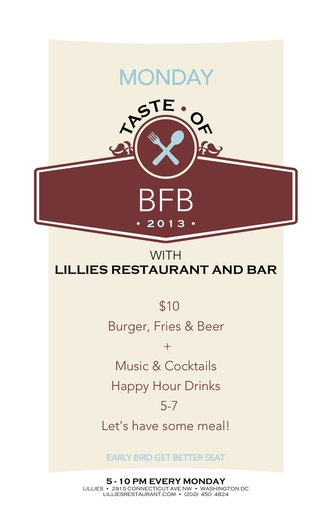

In [65]:
print(food_label_names[food_all[2982]['label']])
food_all[2982]['image']

Menu includes text that says 'burger' but it is not a picture of food. Dropping these types would make the most sense. It will lead to slight imbalances for categories, but it will be limited since each category began with 1000 images.

chicken_wings


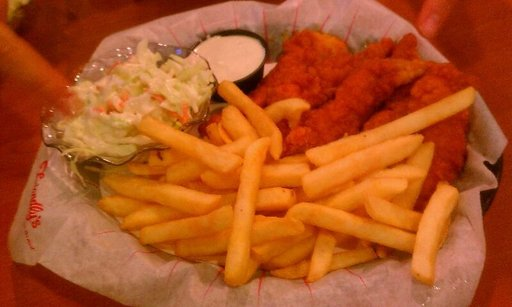

In [66]:
print(food_label_names[food_all[3894]['label']])
food_all[3894]['image']

This is an example of an ambiguous image because it is technically labeled `chicken_wings`, it could confuse the model since a large portion of the image are `french_fries` which is another label in this dataset. It could either be dropped or cropped to the upper right corner.

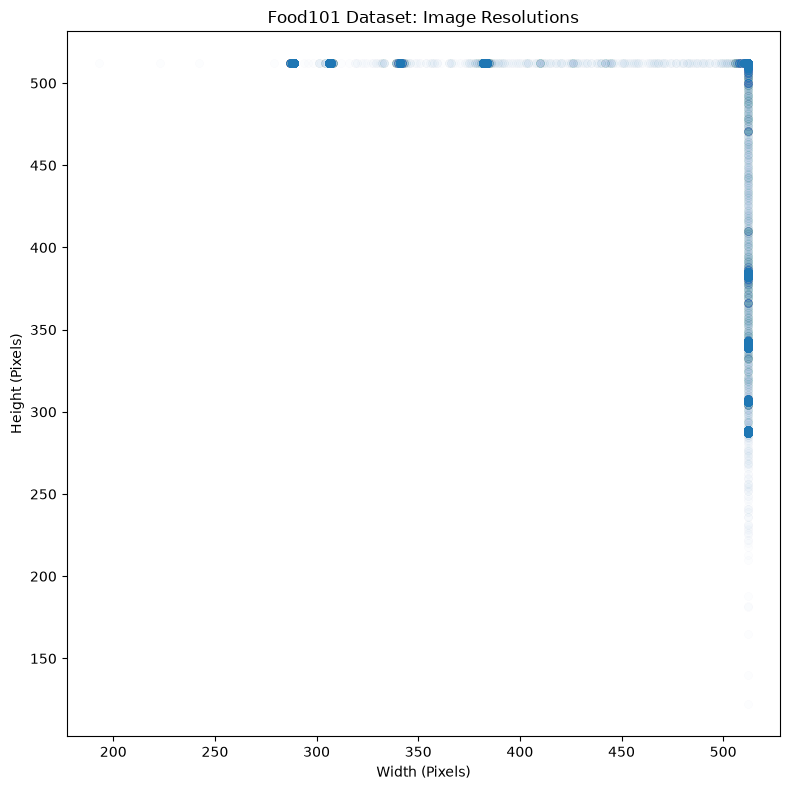

In [67]:
widths  = [i['image'].size[0] for i in food_all]
heights = [i['image'].size[1] for i in food_all]

plt.figure(figsize=(8,8))
sns.scatterplot(
    x=widths,
    y=heights,
    alpha=0.01,
    edgecolor=None
)

plt.xlabel('Width (Pixels)')
plt.ylabel('Height (Pixels)')
plt.title('Food101 Dataset: Image Resolutions')
plt.tight_layout()
plt.show()

In [68]:
print(f'Maximum Width in Pixels: {np.max(widths)}       Minimum Width in Pixels: {np.min(widths)}')
print(f'Maximum Height in Pixels: {np.max(heights)}     Minimum Height in Pixels: {np.min(heights)}')

Maximum Width in Pixels: 512       Minimum Width in Pixels: 193
Maximum Height in Pixels: 512     Minimum Height in Pixels: 122


Will resize all images to 512 x 512

In [69]:
# record all height, width per class
dimension_data = []
for i in food_all:
    dimension_data.append({
        'Food Label'            : label_names[i['label']],
        'Height'                : i['image'].size[1],
        'Width'                 : i['image'].size[0]
    })
dimension_df = pd.DataFrame(dimension_data)

In [70]:
dimension_df['Aspect Ratio'] = dimension_df['Width'] / dimension_df['Height']
dimension_df['Area'] = dimension_df['Width'] * dimension_df['Height']

label_dimensions = (
    dimension_df.groupby('Food Label')
    .agg(
        min_width=('Width', 'min'),
        min_height=('Height', 'min'),

        max_width=('Width', 'max'),
        max_height=('Height', 'max'),
        
        median_width=('Width', 'median'),
        median_height=('Height', 'median'),

        # (1.0 = Square, >1.0 = Landscape, <1.0 = Portrait)
        median_ratio=('Aspect Ratio', 'median'),
        std_ratio=('Aspect Ratio', 'std'),
        iqr_aspect=('Aspect Ratio', lambda x: x.quantile(0.75) - x.quantile(0.25)),

        min_area=('Area', 'min'),
        max_area=('Area', 'max'),
        median_area=('Area', 'median')
    ).reset_index()    
).sort_values(
    by='std_ratio', ascending=False
).reset_index(drop=True)

# Display top 15 most variable food classes for aspect ratios
label_dimensions.head(15)

,Food Label,min_width,min_height,max_width,max_height,median_width,median_height,median_ratio,std_ratio,iqr_aspect,min_area,max_area,median_area
0,macarons,288,122,512,512,512.0,512.0,1.0,0.258329,0.333333,62464,262144,262144.0
1,pho,287,268,512,512,512.0,512.0,1.0,0.255566,0.333333,137216,262144,262144.0
2,hot_dog,193,268,512,512,512.0,512.0,1.0,0.254189,0.333333,98816,262144,262144.0
3,sushi,288,210,512,512,512.0,512.0,1.0,0.254101,0.333333,107520,262144,262144.0
4,chicken_wings,288,140,512,512,512.0,512.0,1.0,0.249747,0.333333,71680,262144,262144.0
5,steak,287,254,512,512,512.0,512.0,1.0,0.246156,0.333333,130048,262144,262144.0
6,pizza,287,287,512,512,512.0,512.0,1.0,0.246070,0.333333,146944,262144,262144.0
7,pork_chop,287,249,512,512,512.0,512.0,1.0,0.245390,0.333333,127488,262144,262144.0
8,waffles,288,287,512,512,512.0,512.0,1.0,0.243382,0.333333,146944,262144,262144.0
9,cheesecake,288,286,512,512,512.0,512.0,1.0,0.242583,0.333333,146432,262144,262144.0


In [71]:
label_dimensions.describe()

,min_width,min_height,max_width,max_height,median_width,median_height,median_ratio,std_ratio,iqr_aspect,min_area,max_area,median_area
count,101.000000,101.000000,101.0,101.0,101.0,101.0,101.0,101.000000,101.000000,101.000000,101.0,101.000000
mean,285.594059,262.297030,512.0,512.0,512.0,512.0,1.0,0.227411,0.164285,133809.425743,262144.0,262141.465347
std,12.317612,34.016333,0.0,0.0,0.0,0.0,0.0,0.012104,0.160824,17820.165059,0.0,25.472952
min,193.000000,122.000000,512.0,512.0,512.0,512.0,1.0,0.197254,0.000000,62464.000000,262144.0,261888.000000
25%,287.000000,247.000000,512.0,512.0,512.0,512.0,1.0,0.220380,0.000000,124416.000000,262144.0,262144.000000
50%,287.000000,276.000000,512.0,512.0,512.0,512.0,1.0,0.226334,0.155073,141312.000000,262144.0,262144.000000
75%,288.000000,287.000000,512.0,512.0,512.0,512.0,1.0,0.235418,0.333333,146944.000000,262144.0,262144.000000
max,304.000000,288.000000,512.0,512.0,512.0,512.0,1.0,0.258329,0.333333,147456.000000,262144.0,262144.000000


Overall, the median image for all classes are square images with a resolution of 512x512 pixels. However, there is still significant variation between the classes as seen in the top 15 food labels sorted by the standard deviation of the aspect ratios. Overall between the food labels the standard deviation of the aspect ratios ranges from roughly 0.197 to 0.258.

### Graded Questions (3 pts each)

Write **a coherent response of approximately 75–125 words per question** in its designated Python answer variable. Be specific to your dataset and refer to relevant code, tables, plots, and numerical results where appropriate. Put supporting code in the programming cells rather than in your written answers. These word counts indicate the expected depth of explanation, not rigid limits. Straightforward factual questions (such as identifying inputs and outputs) may be answered more briefly when fully addressed.

A. **State the prediction task**  
   - Describe what your model will predict (the *label*).  
   - *Examples:*  
     - “Given a photo of food, predict which of 101 categories it belongs to.”  
     - “Given a news headline + summary, predict its topical category.”  

In [73]:
# Your answer here, NOT in the next cell

a2a = """
Given a photo of food, the prediction task is to categorize which image it belongs to out of the 101 food labels.
"""

In [74]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2a = {a2a}")

a2a = 
Given a photo of food, the prediction task is to categorize which image it belongs to out of the 101 food labels.



B. **Define inputs and outputs**  
   - *Inputs:* what information the model receives (e.g., pixel data, tokenized text).  
   - *Outputs:* the categorical label the model will predict.  

In [75]:
# Your answer here, NOT in the next cell

a2b = """
The model will receive the pixel data for each image and output a probability distribution across all the 101 classes as to what the image is likely classified as. The final predicted class label will be chosen by picking the highest probability from the distribution.
"""

In [76]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2b = {a2b}")

a2b = 
The model will receive the pixel data for each image and output a probability distribution across all the 101 classes as to what the image is likely classified as. The final predicted class label will be chosen by picking the highest probability from the distribution.



C. **Identify possible challenges**  
   - Imbalanced classes, noisy data, ambiguous labels, overlapping features, or missing data  
   - *Images:* variation in lighting, color, composition, or size.  
   - *Text:* class imbalance, duplicate stories, short or ambiguous headlines.  

In [77]:
# Your answer here, NOT in the next cell

a2c = """
While the raw dataset is balanced across the 101 classes (1000 images per class), challenges with data quality and inaccurate labels could lead to lower model accuracy.
As shown in the issue table, which records the count of images for a given issue type and its total images with issues, there is variation in the classes.
For example, miso_soup has the most blurry images in the dataset (16) and prime_rib has the most total issues in the dataset (18). 
Variation in blur, darkness, color, size, and aspect ratio are potential challenges for this model.
While images can be normalized for specific quality issues such as color, size, aspect ratio.
Blur will likely be a more difficult challenge because blur can be caused by low information or through the lens not focusing properly.
After quality, identifying all mislabeled images in the dataset will be the most significant process simply due to the size of the dataset being unrealistic to manually verify.
"""

In [78]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2c = {a2c}")

a2c = 
While the raw dataset is balanced across the 101 classes (1000 images per class), challenges with data quality and inaccurate labels could lead to lower model accuracy.
As shown in the issue table, which records the count of images for a given issue type and its total images with issues, there is variation in the classes.
For example, miso_soup has the most blurry images in the dataset (16) and prime_rib has the most total issues in the dataset (18). 
Variation in blur, darkness, color, size, and aspect ratio are potential challenges for this model.
While images can be normalized for specific quality issues such as color, size, aspect ratio.
Blur will likely be a more difficult challenge because blur can be caused by low information or through the lens not focusing properly.
After quality, identifying all mislabeled images in the dataset will be the most significant process simply due to the size of the dataset being unrealistic to manually verify.



D. **Propose how you will prepare or improve the data to address the challenges**  
   - *Images:* resizing, normalization, data augmentation (flips, rotations, brightness, color jitter).  
   - *Text:* tokenization, stop-word removal, TF-IDF, class balancing, embeddings (choose an embedding approach and specify its vector size). 

In [79]:
# Your answer here, NOT in the next cell

a2d = """
The first step is to normalize the image size to 512x512 in order to have a consistent matrix of pixel values for the model's input. 
If 512x512 leads to significant issues in terms of computational cost when training the model, I will reduce the size while maintaining the 1.0 aspect ratio.

Once the images are normalized for size and aspect ratio, the next step to preprocess the data will be to identify mislabeled images.
To do this, I will follow the framework from the experiment conducted by Yunhao Yang and Andrew Whinston (https://arxiv.org/abs/2011.03667) which encodes and reconstructs the images, project the image data on to latent space in a lower dimension, then use DBSCAN to identify outliers.
This assumes that the labeled images will be mostly clustered closely for each given food label and outliers (potential mislabeled images) will be farther away.
Once identified, I can see if the image's label can be restored to the accurate one or if the image is irrelevant I will remove it from the dataset.

Next, I will normalize the images for brightness in order to deal with the darker images. 
To deal with color variation, I could introduce randomized color jitter, randomly convert a fraction of training data to greyscale, or zero out one of the RGB channels.
To deal with blur (at least 137 images), I will drop the images.
Since there are not many (~0.14% images from the dataset), it will lead to slight class imbalances which can be dealt with through stratified training sets.
"""

In [80]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2d = {a2d}")

a2d = 
The first step is to normalize the image size to 512x512 in order to have a consistent matrix of pixel values for the model's input. 
If 512x512 leads to significant issues in terms of computational cost when training the model, I will reduce the size while maintaining the 1.0 aspect ratio.

Once the images are normalized for size and aspect ratio, the next step to preprocess the data will be to identify mislabeled images.
To do this, I will follow the framework from the experiment conducted by Yunhao Yang and Andrew Whinston (https://arxiv.org/abs/2011.03667) which encodes and reconstructs the images, project the image data on to latent space in a lower dimension, then use DBSCAN to identify outliers.
This assumes that the labeled images will be mostly clustered closely for each given food label and outliers (potential mislabeled images) will be farther away.
Once identified, I can see if the image's label can be restored to the accurate one or if the image is irrelevant I will

E. **Specify success metrics**  
   - Identify the metrics you plan to use to evaluate model performance—typically **accuracy** and/or **F1-score**, which are standard for classification tasks.  
   - Briefly explain **why** these metrics are appropriate for your dataset and goal. For instance, accuracy may suffice for well-balanced datasets, while F1-score better reflects performance when some classes are under-represented.
   - If your dataset is **imbalanced**, consider computing **per-class metrics** (e.g., precision, recall, or F1 for each label) or **macro-averaged** scores, which give equal weight to each class regardless of its size—ensuring that minority classes are evaluated fairly.
In some cases, weighted averages (which weight classes by their frequency) or **confusion matrices** can also provide useful insight.
> You haven't run any models yet, and we haven’t studied every possible metric, but you’re encouraged to ask your favorite generative AI tool which evaluation metrics might best fit your dataset!
   - Clearly state how you will interpret success—for example, “Our goal is to achieve at least 80% overall accuracy without large per-class disparities.”

In [81]:
# Your answer here, NOT in the next cell

a2e = """
The primary evaluation metric for model performance will be accuracy due to its ease of interpretability.
The expectation after preprocessing is that the dataset will be mostly balanced where no class significantly dominates the model training.
Macro F1-score will be used as a secondary metric to ensure robust performance across all classes.
The trade-off with accuracy is that it can sometimes hide differences in classes since it considers the full true prediction rate while macro F1-score is an average across all classes which will go down if some classes perform significantly worse than others.

The goal is to achieve at least a 90% overall accuracy with stable levels per class. To ensure this, the target range for macro F1 should be at least 86-90%.
"""

In [82]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2e = {a2e}")

a2e = 
The primary evaluation metric for model performance will be accuracy due to its ease of interpretability.
The expectation after preprocessing is that the dataset will be mostly balanced where no class significantly dominates the model training.
Macro F1-score will be used as a secondary metric to ensure robust performance across all classes.
The trade-off with accuracy is that it can sometimes hide differences in classes since it considers the full true prediction rate while macro F1-score is an average across all classes which will go down if some classes perform significantly worse than others.

The goal is to achieve at least a 90% overall accuracy with stable levels per class. To ensure this, the target range for macro F1 should be at least 86-90%.



## Problem 3 — Data Preparation and Splits (30 pts)

### Goals

Implement the **data preparation and preprocessing steps** that you proposed in **Problems 1–2**. You’ll clean, normalize, and split your data so that it’s ready for modeling and reproducible modeling.

### Steps to Follow

1. **Load your chosen dataset**

   * Use `datasets.load_dataset()` from **Hugging Face** to load **Food-101** or **HuffPost**.
   * Display basic information (e.g., number of samples, feature names, example entries).

2. **Apply cleaning and normalization**

   * **Images:**

     * Ensure all images are in RGB format.
     * Resize or crop to a consistent shape (e.g., `224 × 224`).
     * Drop or fix any corrupted files.
   * **Text:**

     * Concatenate headline + summary (for HuffPost).
     * Strip whitespace, convert to lowercase if appropriate, and remove empty samples.
     * Optionally remove duplicates or extremely short entries.

3. **Standardize or tokenize the inputs**

   * **Images:**

     * Normalize pixel values (e.g., divide by 255.0).
     * Define a minimal augmentation pipeline (e.g., random flip, crop, or rotation).
   * **Text:**

     * Create a tokenizer or `TextVectorization` layer.
     * Set a target `max_length` based on your analysis from your earlier exploration in this notebook (e.g., 95th percentile).
     * Apply padding/truncation and build tensors for input + labels.

4. **Handle dataset-specific challenges**

   * If you identified **class imbalance**, compute label counts and, if needed, create a dictionary of `class_weights`.
   * If you noted **length or size variance**, verify that your truncation or resizing works as intended.
   * If you planned **noise filtering**, include the cleaning step and briefly explain your criteria (e.g., remove items with missing text or unreadable images).

5. **Create reproducible splits**

   * Split your cleaned dataset into **train**, **validation**, and **test** subsets (e.g., 80 / 10 / 10).
   * Use a fixed random seed for reproducibility (`random_seed = 42`).
   * Use **stratified splits**  (e.g., with `train_test_split` and `stratify = labels`).
   * Display the size of each subset.

6. **Document your pipeline**

   * Summarize your preprocessing steps clearly in Markdown or code comments.
   * Save or display a few representative examples after preprocessing to confirm the transformations are correct.




**Test-set policy:** Create and verify the test split, but **do not train on or evaluate models against it** in this milestone. Fit preprocessing parameters (e.g. vocabulary, scaling) on training data only; apply the fitted transformations to validation and test examples. Apply random augmentation to training data only.


In [12]:
food101       = food_all
class_counts  = Counter(food101['label'])
label_names   = food101.features['label'].names
class_balance = {label_names[label_id]: count for label_id, count in class_counts.items()}

print(f'There are a total of {len(food101):,} images in the food101 dataset.\n')
print('Image Counts per Class:', pd.Series(class_balance.values()).unique()[0])         # there was only 1 number in list, so I converted it to just the value and not the list ( [1000] )
print(f'Number of Classes: {len(label_names)}')
print('\nClasses:')
print(label_names)

# ensure all images are in RGB format
non_rgb = []
for idx, image in enumerate(food101):
    if image['image'].mode != "RGB":
        # record index and the image mode if it isnt in RGB format
        non_rgb.append({idx: image['image'].mode})

if not non_rgb:
    print('\nAll images are in RGB format')
else:
    print(f'\nNot all images are in RGB format. Found {len(non_rgb)} non-RGB images.')
    print(non_rgb)

There are a total of 101,000 images in the food101 dataset.

Image Counts per Class: 1000
Number of Classes: 101

Classes:
['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare', 'beet_salad', 'beignets', 'bibimbap', 'bread_pudding', 'breakfast_burrito', 'bruschetta', 'caesar_salad', 'cannoli', 'caprese_salad', 'carrot_cake', 'ceviche', 'cheesecake', 'cheese_plate', 'chicken_curry', 'chicken_quesadilla', 'chicken_wings', 'chocolate_cake', 'chocolate_mousse', 'churros', 'clam_chowder', 'club_sandwich', 'crab_cakes', 'creme_brulee', 'croque_madame', 'cup_cakes', 'deviled_eggs', 'donuts', 'dumplings', 'edamame', 'eggs_benedict', 'escargots', 'falafel', 'filet_mignon', 'fish_and_chips', 'foie_gras', 'french_fries', 'french_onion_soup', 'french_toast', 'fried_calamari', 'fried_rice', 'frozen_yogurt', 'garlic_bread', 'gnocchi', 'greek_salad', 'grilled_cheese_sandwich', 'grilled_salmon', 'guacamole', 'gyoza', 'hamburger', 'hot_and_sour_soup', 'hot_dog', 'huevos_rancheros'

'L' means greyscale. See the images earlier in the notebook.

#### Resize Images

In [13]:
# Standardizing image size to 512x512 and pad pixels to maintain original aspect ratio without distorting/stretching image
from PIL import ImageOps, Image

# change image size if needed
IMAGE_SIZE = (512, 512)

def normalize_image_size(image, image_size=IMAGE_SIZE):
    """
        Normalizes images to the specified image_size (pixels) while maintaining the original aspect ratio through padding remaining pixels black.
    """
    # handles already loaded PIL Image objects and file paths
    img = image if isinstance(image, Image.Image) else Image.open(image)

    # formats to RGB
    img = img.convert("RGB")

    # Return resized image (padded if scaled up)
    return ImageOps.pad(img, image_size, method=Image.Resampling.LANCZOS, color=(0,0,0))


def resize_batch(batch):
    """
        Processes images in batches for better performance.
    """
    batch['image'] = [normalize_image_size(img, IMAGE_SIZE) for img in batch['image']]
    return batch

print(f'Resizing images to {IMAGE_SIZE[0]}x{IMAGE_SIZE[1]}...')
resized_food101 = food101.map(
    resize_batch,
    batched=True,
    batch_size=1000,
    num_proc=os.cpu_count()          # maximum multi-processing for faster processing
)

print(f'\nSuccessfully resized {len(resized_food101):,} images.')

Resizing images to 512x512...


Map (num_proc=18):   0%|          | 0/101000 [00:00<?, ? examples/s]


Successfully resized 101,000 images.


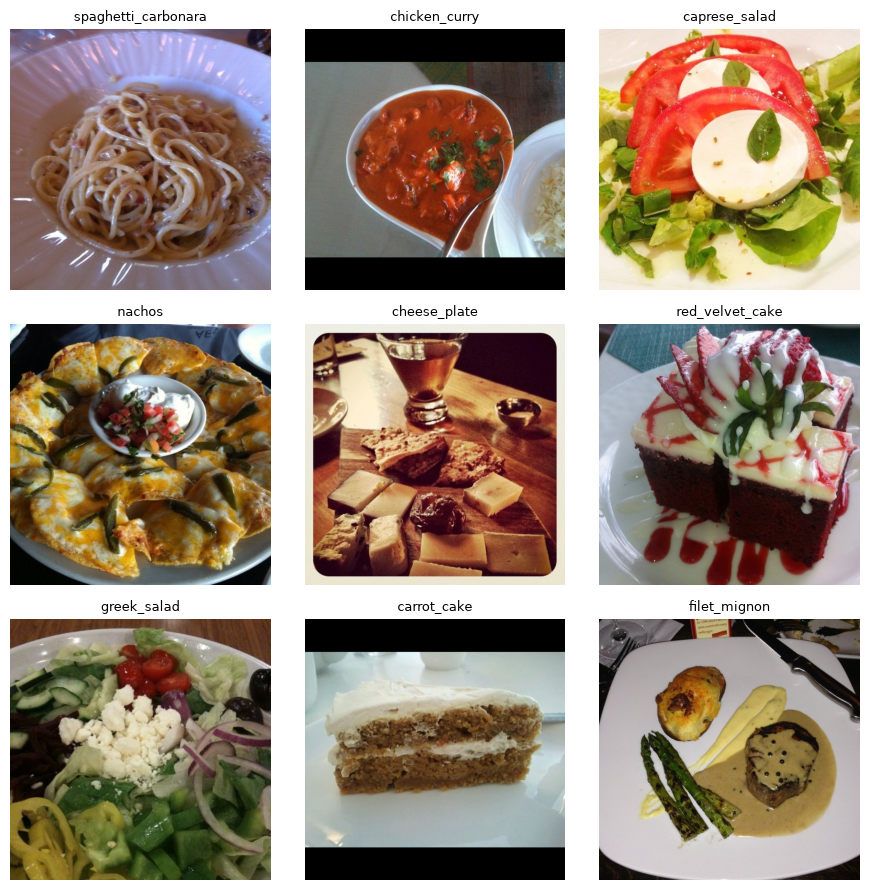

In [13]:
# Check to make sure images are still readable and padded
n, cols, seed = 9, 3, 456
idxs = random.Random(seed).sample(range(len(resized_food101)), n)
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]], fontsize=9)
plt.tight_layout(); plt.show()

#### Find Mislabeled Images

Using Yunhao Yang and Andrew Whinston's *Identifying Mislabeled Images in Supervised Learning Utilizing Autoencoder* method (University of Texas at Austin https://arxiv.org/abs/2011.03667)

In [14]:
# Using pre-trained feature extractor rather than training a new one due to the large dataset and image size
from tensorflow.keras.applications import EfficientNetB2
from tensorflow.keras.applications.efficientnet import preprocess_input

start_time = time.time()

# using pre-trained EfficientNetB2 on ImageNet
print('Loading EfficientNetB2')
base_model = EfficientNetB2(weights='imagenet', include_top=False, pooling='avg', input_shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3))

# extract embeddings in batches to prevent kernel crashes
batch_size = 32
all_embeddings = []
print(f'Extracting feature embeddings in batches of {batch_size}\n')

for i in range(0, len(resized_food101), batch_size):
    batch = resized_food101.select(range(i, min(i + batch_size, len(resized_food101))))

    # convert batch into numpu array
    batch_arr = np.array([np.array(img['image']) for img in batch], dtype=np.float32)

    # preprocess and get embeddings
    preprocessed_batch = preprocess_input(batch_arr)
    embeddings_batch = base_model.predict(preprocessed_batch, verbose=0)

    # store embeddings
    all_embeddings.append(embeddings_batch)

    # track progress
    if (i // batch_size) % 100 == 0:
        print(f'Processed {i}/{len(resized_food101)} images...')

# final embedding matrix
embeddings = np.vstack(all_embeddings)

print(f'\nEmbedding Shape: {embeddings.shape}')
print("Execution Time:", format_hms(time.time() - start_time))

Loading EfficientNetB2


2026-11-09 13:42:58.950873: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M5 Max
2026-11-09 13:42:58.957844: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 36.00 GB
2026-11-09 13:42:58.958899: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 14.04 GB
2026-11-09 13:42:58.958942: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-11-09 13:42:58.959178: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Extracting feature embeddings in batches of 32



2026-11-09 13:43:02.313744: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


Processed 0/101000 images...
Processed 3200/101000 images...
Processed 6400/101000 images...
Processed 9600/101000 images...
Processed 12800/101000 images...
Processed 16000/101000 images...
Processed 19200/101000 images...
Processed 22400/101000 images...
Processed 25600/101000 images...
Processed 28800/101000 images...
Processed 32000/101000 images...
Processed 35200/101000 images...
Processed 38400/101000 images...
Processed 41600/101000 images...
Processed 44800/101000 images...
Processed 48000/101000 images...
Processed 51200/101000 images...
Processed 54400/101000 images...
Processed 57600/101000 images...
Processed 60800/101000 images...
Processed 64000/101000 images...
Processed 67200/101000 images...
Processed 70400/101000 images...
Processed 73600/101000 images...
Processed 76800/101000 images...
Processed 80000/101000 images...
Processed 83200/101000 images...
Processed 86400/101000 images...
Processed 89600/101000 images...
Processed 92800/101000 images...
Processed 96000/1

##### Split Embeddings and Indices by Class

In [15]:
# Split embeddings and indices by food label class
from collections import defaultdict

labels = np.array(resized_food101['label'])

# stores embeddings and dataset's indices per class
class_data = defaultdict(lambda: {'embeddings': [], 'indices': []})

# update dictionary with embeddings and labels - embeddings were in order so it maps correctly
for idx, (emb, label) in enumerate(zip(embeddings, labels)):
    class_data[label]['embeddings'].append(emb)
    class_data[label]['indices'].append(idx)

# convert lists to arrays for each class
for label in class_data:
    class_data[label]['embeddings'] = np.array(class_data[label]['embeddings'])
    class_data[label]['indices'] = np.array(class_data[label]['indices'])

# check to ensure they are separated properly
print(f'Grouped embeddings into {len(class_data)} separate classes')


Grouped embeddings into 101 separate classes


##### Use DBSCAN to detect outliers (hopefully mislabeled images)

In [16]:
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from kneed import KneeLocator

start_time = time.time()

# Rahmah's algorithm and KneeLocator to get optimal epsilon for DBSCAN for each class
def find_class_epsilon(class_embeddings, k=5):
    """
        Computes knn distances for single class and uses KneeLocator to identify the best epsilon
    """
    if len(class_embeddings) <= k:
        return 0.15 # default epsilon

    knn = NearestNeighbors(n_neighbors=k)
    knn.fit(class_embeddings)
    distances, _ = knn.kneighbors(class_embeddings)

    # sort distances to the k-th nearest neighbor in ascending order
    k_dist = np.sort(distances[:, k-1])

    # get the elbow
    x_vals = range(len(k_dist))
    y_vals = k_dist
    kneeloc = KneeLocator(x_vals, y_vals, curve='convex', direction='increasing')

    # if not found, go to default
    if kneeloc.elbow is None:
        return 0.15

    optimal_eps = y_vals[kneeloc.elbow]
    return float(optimal_eps)


# Apply Rahmah algorithm and DBSCAN per class to find outliers (hopefully mislabeled images)
outlier_idx = []
class_epsilson = {}     # stores class and its optimal epsilon

for food_class, data in class_data.items():
    class_embeddings = data['embeddings']
    orig_idx = data['indices']

    # Rahmah algorithm and KneeLocator to get optimal epsilon per class
    optimal_eps = find_class_epsilon(class_embeddings)
    class_epsilson[food_class] = optimal_eps

    # run DBSCAN per class
    dbscan = DBSCAN(eps=optimal_eps, metric='euclidean', n_jobs=-1)
    cluster_labels = dbscan.fit_predict(class_embeddings)
    
    # get indices that were flagged as noise from the DBSCAN
    noise = (cluster_labels == -1)
    outliers = orig_idx[noise]

    if len(outliers) > 0 and len(dbscan.core_sample_indices_) > 0:
        core_embeddings = class_embeddings[dbscan.core_sample_indices_]
        noise_embeddings = class_embeddings[noise]

        # calculate distance to nearest core embedding - used for sorting outlier severity
        nn = NearestNeighbors(n_neighbors=1, metric='euclidean').fit(core_embeddings)
        distances, _ = nn.kneighbors(noise_embeddings)

        # record outlier distances
        for idx, dist in zip(outliers, distances.flatten()):
            outlier_idx.append({'index': int(idx), 'distance': float(dist)})

    # if a class has an outlier but no core points, fill in flagged distance
    elif len(outliers) > 0:
        for idx in outliers:
            outlier_idx.append({'index': int(idx), 'distance': 999.0})

# sort outliers by distance in descending order
outlier_imgs = sorted(outlier_idx, key=lambda x: x['distance'], reverse=True)
sorted_outlier_idx = [i['index'] for i in outlier_imgs]

print(f'Detected a total of {len(sorted_outlier_idx):,} outliers across all classes.')
print("Execution Time:", format_hms(time.time() - start_time))

Detected a total of 2,499 outliers across all classes.
Execution Time: 00:00:05


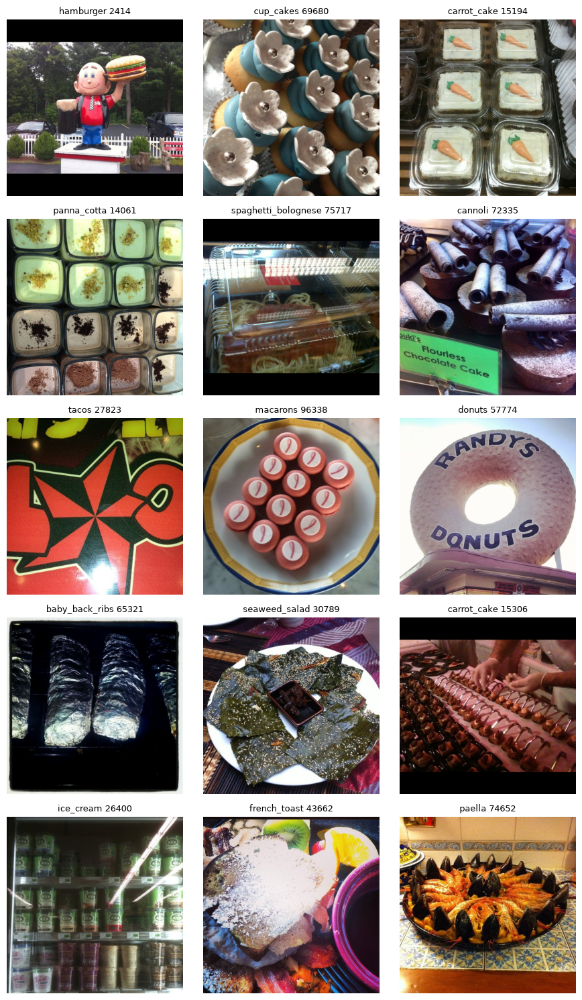

In [17]:
# Check top 15 images to verify this pipeline works
n, cols = 15, 3
idxs = sorted_outlier_idx[:n]
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [20]:
# get counts per class for these outliers
outlier_labels = [food_label_names[resized_food101[idx]['label']] for idx in sorted_outlier_idx]
outlier_counts = Counter(outlier_labels)

summary = []
for class_label, count in outlier_counts.items():
    summary.append({
        'Food Label'            : class_label,
        'Outlier Count'         : count,
        '% Outlier'             : round((count / 1000) * 100, 2)      # manually coded because I already checked to ensure each class is 1000 images
        })
summary_df = pd.DataFrame(summary).sort_values(by='Outlier Count', ascending=False).reset_index(drop=True)
summary_df.to_csv('outliers_per_label.csv', index=False)
summary_df

,Food Label,Outlier Count,% Outlier
0,strawberry_shortcake,74,7.4
1,grilled_cheese_sandwich,54,5.4
2,risotto,53,5.3
3,scallops,52,5.2
4,pho,46,4.6
...,...,...,...
96,spring_rolls,8,0.8
97,huevos_rancheros,8,0.8
98,sushi,7,0.7
99,creme_brulee,4,0.4


In [21]:
# organize each image index and its label
outlier_data = []
for idx in sorted_outlier_idx:
    outlier_data.append({
        'Index'                 : idx,
        'Food Label'            : food_label_names[resized_food101[idx]['label']]
    })
outlier_df = pd.DataFrame(outlier_data)
outlier_df.to_csv('outliers.csv', index=False)
outlier_df

,Index,Food Label
0,2414,hamburger
1,69680,cup_cakes
2,15194,carrot_cake
3,14061,panna_cotta
4,75717,spaghetti_bolognese
...,...,...
2494,65174,hot_and_sour_soup
2495,50936,pho
2496,50682,pho
2497,64517,hot_and_sour_soup


##### Visualize flagged outliers to see if they are mislabeled or need cropping

Note: Cleared outputs after running to save memory

In [ ]:
# check all strawberry_shortcake outliers since they have the highest outlier %
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'strawberry_shortcake']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all grilled_cheese_sandwich outliers since they have the second highest outlier %
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'grilled_cheese_sandwich']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all risotto outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'risotto']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all scallops outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'scallops']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all pho outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'pho']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all grilled_salmon outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'grilled_salmon']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all hot_dog outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'hot_dog']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all churros outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'churros']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all crab_cakes outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'crab_cakes']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all chicken_curry outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'chicken_curry']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all filet_mignon outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'filet_mignon']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all breakfast_burrito outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'breakfast_burrito']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all samosa outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'samosa']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all tuna_tartare outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'tuna_tartare']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all guacamole outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'guacamole']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all poutine outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'poutine']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all spaghetti_bolognese outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'spaghetti_bolognese']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all gyoza outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'gyoza']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all chocolate_mousse outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'chocolate_mousse']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all ice_cream outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'ice_cream']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all hot_and_sour_soup outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'hot_and_sour_soup']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all edamame outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'edamame']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all lobster_roll_sandwich outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'lobster_roll_sandwich']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all ramen outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'ramen']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all fried_rice outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'fried_rice']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all pizza outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'pizza']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all beignets outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'beignets']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all bread_pudding outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'bread_pudding']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all lobster_bisque outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'lobster_bisque']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all french_onion_soup outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'french_onion_soup']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all shrimp_and_grits outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'shrimp_and_grits']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

# `` ------ CONTINUE WITH CHEESE_PLATE ------ ``

In [ ]:
# check all cheese_plate outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'cheese_plate']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all nachos outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'nachos']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all caprese_salad outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'caprese_salad']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all hamburger outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'hamburger']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all ceviche outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'ceviche']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all pork_chop outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'pork_chop']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all spaghetti_carbonara outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'spaghetti_carbonara']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all omelette outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'omelette']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all carrot_cake outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'carrot_cake']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all fish_and_chips outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'fish_and_chips']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all beef_tartare outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'beef_tartare']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all deviled_eggs outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'deviled_eggs']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all beet_salad outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'beet_salad']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all miso_soup outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'miso_soup']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all fried_calamari outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'fried_calamari']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all prime_rib outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'prime_rib']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all club_sandwich outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'club_sandwich']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all steak outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'steak']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all gnocchi outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'gnocchi']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all hummus outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'hummus']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all french_fries outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'french_fries']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all sashimi outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'sashimi']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all greek_salad outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'greek_salad']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all caesar_salad outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'caesar_salad']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all baby_back_ribs outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'baby_back_ribs']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all foie_gras outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'foie_gras']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all peking_duck outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'peking_duck']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all tacos outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'tacos']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all mussels outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'mussels']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all macarons outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'macarons']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all chicken_quesadilla outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'chicken_quesadilla']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all red_velvet_cake outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'red_velvet_cake']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all falafel outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'falafel']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all tiramisu outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'tiramisu']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all pulled_pork_sandwich outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'pulled_pork_sandwich']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all escargots outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'escargots']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all pad_thai outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'pad_thai']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all takoyaki outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'takoyaki']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all panna_cotta outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'panna_cotta']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all chicken_wings outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'chicken_wings']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all lasagna outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'lasagna']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all apple_pie outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'apple_pie']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all frozen_yogurt outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'frozen_yogurt']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all macaroni_and_cheese outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'macaroni_and_cheese']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all waffles outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'waffles']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all seaweed_salad outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'seaweed_salad']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all donuts outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'donuts']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all bibimbap outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'bibimbap']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all bruschetta outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'bruschetta']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all cannoli outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'cannoli']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all croque_madame outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'croque_madame']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all cheesecake outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'cheesecake']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all beef_carpaccio outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'beef_carpaccio']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all ravioli outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'ravioli']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all dumplings outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'dumplings']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all clam_chowder outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'clam_chowder']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all chocolate_cake outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'chocolate_cake']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all pancakes outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'pancakes']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all garlic_bread outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'garlic_bread']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all cup_cakes outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'cup_cakes']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all french_toast outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'french_toast']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all paella outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'paella']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all onion_rings outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'onion_rings']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all oysters outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'oysters']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all spring_rolls outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'spring_rolls']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all huevos_rancheros outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'huevos_rancheros']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all sushi outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'sushi']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all creme_brulee outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'creme_brulee']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# check all eggs_benedict outliers
filtered_outliers = outlier_df[outlier_df['Food Label'] == 'eggs_benedict']['Index'].tolist()

n, cols = len(filtered_outliers), 5
idxs = filtered_outliers
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = resized_food101[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]] + ' ' + str(idx), fontsize=9)
plt.tight_layout(); plt.show()

##### Visualize specific images to crop 

Note: cleared outputs after running to save memory. To see images, rerun notebook.

In [ ]:
# Visualize image 50524 to figure out the best crop for preprocessing
import matplotlib.ticker as ticker
img = resized_food101[50524]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[50612]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[33410]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[74241]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[74210]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[17799]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[17995]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[17907]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[17986]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[17494]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[17750]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[17442]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[17987]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[71579]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[71564]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[71867]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[32368]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[58642]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[95957]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[60111]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[32017]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[32204]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[31566]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[39531]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[39720]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[9505]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[9074]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[9198]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[9120]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[9097]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[9309]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[9113]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[70123]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[70274]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[75290]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[75256]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[22945]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[26536]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[26450]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[53520]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[53269]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[53894]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()    

In [ ]:
img = resized_food101[53598]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[52710]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[53120]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[52722]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[2051]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[1810]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[13009]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[12887]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[8053]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[8079]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[620]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[44982]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[46938]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[57197]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[57706]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[61278]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[60773]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[2626]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[2659]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[4893]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[66761]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[66849]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[59958]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[20040]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[19804]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[10849]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[865]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[1247]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[770]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[18093]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[18665]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[14852]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[40728]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[41071]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[6342]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[5367]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[5772]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[20878]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[20863]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[65990]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[65514]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[28829]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[56633]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[56949]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[28206]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[34613]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[34653]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[34877]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[96260]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[61952]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[61622]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[61667]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[61865]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[41966]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[41283]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[41911]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[41869]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[37310]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[37220]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[54136]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[54273]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[24409]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[52271]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[51954]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[52220]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[52084]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[52066]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[52412]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[14149]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[4169]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[23639]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[23702]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[11874]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[11486]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[11512]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[30317]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[30656]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[73384]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[73273]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[73134]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[46099]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[31452]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[68269]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[68257]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[68342]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[3349]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[72153]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[62743]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[62460]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[25443]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[25109]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[66454]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[35677]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[48440]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[48581]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[79142]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[22074]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[21932]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[81496]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[17166]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[17003]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[16963]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[69006]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[44152]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[74466]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[43288]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[43441]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[67514]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[8888]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[3894]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[4171]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[24746]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
img = resized_food101[18115]['image']

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(5))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))

ax.grid(which='both', color='cyan', linestyle='--', linewidth=0.5, alpha=0.6)
plt.tight_layout()
plt.show()

##### Crop images to improve data quality

In [14]:
# crop format (left, upper, right, lower)
crop_imgs = {
    50524: (160, 0, 380, 260),       # image collage cropped to just the pho
    50612: (300, 240, 512, 512),     # cropping image of pho just to the bowl of pho rather than the whole thing since theres also a sandwich
    33410: (60, 220, 180, 512),      # cropping image to strawberry shortcake and leaving out the cup cakes to not confuse the model between the two labels 
    74241: (0, 310, 470, 512),       # cropping grilled salmon dish to just the salmon since french fries may confuse the model because it is also a label.
    74210: (80, 200, 420, 320),      # wok of salmon with chef and somewhat busy background. cropping into just the food.
    17799: (120, 260, 220, 350),     # cropping image of woman holding container with hot dog to keep main focus of pixels on hot dog and not other details like people or background details.
    17995: (160, 250, 420, 400),     # cropping image of hot dog at baseball game to get rid of background arena details
    17907: (160, 160, 340, 300),     # cropping to just the hot dog since it is a far away top down view of the table
    17986: (140, 300, 400, 400),     # cropping hot dog on elephant stuffed animal's lap so the focus is just on the hot dog.
    17494: (100, 300, 420, 420),     # cropping image of hot dog at baseball game to get rid of background arena details
    17750: (120, 280, 360, 512),     # cropping image of hot dog at baseball game to get rid of background arena details
    17442: (240, 420, 320, 490),     # cropping image of a woman by a table holding a hot dog to just the hot dogs on the table
    17987: (120, 160, 240, 280),     # cropping image around just the hot dog in the person's hands because the rest of the image is empty space/inside of the car
    71579: (100, 320, 380, 512),     # cropping churros to remove background details of people and the stand
    71564: (260, 240, 380, 380),     # cropping out instagram UI to focus just on churros
    71867: (200, 320, 500, 480),     # cropping out restaurant background to focus on churros
    32368: (100, 190, 400, 340),     # cropping out smartphone UI to focus on crabcake sandwich
    58642: (20, 240, 220, 400),      # cropping out person so just the curry is shown without any side dishes as well
    95957: (280, 100, 480, 420),     # cropping out side dish for filet mignon
    60111: (40, 100, 260, 220),      # cropping out side dishes for filet mignon
    32017: (180, 180, 320, 400),     # cropping out background to focus just on breakfast sandwich
    32204: (100, 240, 420, 500),     # cropping out city background to focus on breakfast sandwich
    31566: (40, 200, 280, 300),      # cropping out chef and kitchen to focus on breakfast sandwich
    39531: (260, 260, 512, 512),     # samosa but cropping out collage of menu/food truck to focus on samosa
    39720: (260, 280, 460, 380),     # samosa but cropping to just the dishes with samosas instead of the whole image with the server and background
    9505: (20, 400, 300, 512),       # guacamole but cropped to just the guacamole the man is making
    9074: (180, 380, 400, 512),      # guacamole but cropped to just the guacamole the man is making
    9198: (180, 0, 460, 240),        # guacamole but cropped to just the bowl of guacamole since it is on the far end of the table
    9120: (260, 280, 512, 512),      # guacamole but cropped to bottom left image in the collage since its the guacamole part of the collage
    9097: (300, 280, 420, 280),      # guacamole but cropping onto bowl of guacamole since there's a lot in the background and on the table
    9113: (340, 200, 500, 360),      # guacamole but cropped to guacamole bowl and remove the bag of chips that takes up more of the image
    70123: (200, 300, 390, 440),     # poutine but cropped to just the poutine and getting rid of graphic design in background
    70274: (200, 380, 400, 512),     # poutine but cropped around food to remove the person
    75290: (260, 260, 500, 500),     # collage of images and cropped down to spaghetti bolognese
    75256: (140, 0, 340, 100),       # crop to the spaghetti bolognese on the far end of table
    22945: (240, 100, 480, 300),     # cropped on the chocolate mousse and remove signs/background items
    26536: (200, 200, 400, 420),     # cropped out baseball game to focus on just ice cream bowl
    26450: (160, 60, 400, 260),      # cropped out background to focus on ice cream cup
    53520: (0, 60, 512, 275),        # cropped out label from container of edamame so the focus is on the food
    53269: (100, 320, 300, 512),     # cropped out other dishes to focus on edamame
    53894: (310, 120, 512, 512),     # cropped out soda can to focus on edamame
    53598: (110, 110, 220, 200),     # cropped to focus on bowl of edamame in the back of the table
    52710: (160, 220, 320, 340),     # cropped out other food in fridge to focus on lobster roll sandwiches
    53120: (180, 140, 420, 360),     # cropped out lobster roll sandwich since it barely shows from the wrapper. Will switch to onion rings label
    52722: (240, 140, 512, 420),     # cropped out chips bag to focus on lobster roll sandwich
    2051: (0, 220, 512, 512),        # cropped out woman to focus just on ramen
    1810: (120, 80, 512, 280),       # crop out most of the advertisement sign to focus on the ramen
    13009: (140, 280, 400, 420),     # cropped out side dishes to focus on fried rice
    12887: (300, 160, 500, 320),     # collage of photos, cropped to fried rice image
    8053: (230, 280, 360, 410),      # cropped to pizza and crop out baby/background
    8079: (60, 260, 440, 420),       # cropped to pizza on the stands
    620: (160, 120, 300, 260),       # beignet but cropped to just the food and leave out person/background
    44982: (60, 300, 360, 512),      # lobster bisque but cropped to just the food and leave out the person/background
    46938: (160, 280, 360, 440),     # cropping to french onion soup and remove person/background
    57197: (260, 20, 490, 240),      # collage of nachos but cropping to just one image of nachos
    57706: (20, 20, 490, 260),       # ad for nachos but cropping to just upper nachos image
    61278: (0, 320, 512, 512),       # caprese salad but cropping out background that takes up most of the image.
    60773: (0, 280, 460, 512),       # caprese salad but cropping out background hills and pool to focus on food
    2626: (140, 260, 280, 380),      # hamburger but cropping out background/mountains that take up a lot of space
    2659: (0, 260, 512, 512),        # hamburger but cropping out upper half of collage that shows a building
    4893: (60, 320, 440, 512),       # pork chop but cropping out woman to focus just on food
    66761: (0, 320, 300, 512),       # spaghetti carbonara but cropping out background to focus on food on bottom left corner
    66849: (260, 20, 480, 250),      # cropping 4 image collage to just the spaghetti carbonara
    59958: (0, 260, 340, 440),       # omelette but cropping out energy drink
    20040: (60, 200, 450, 450),      # fish and chips collage but cropping to main image of fried fish on top of fries
    19804: (60, 280, 512, 512),      # fish and chips but cropping out girl
    10849: (0, 300, 140, 512),       # miso soup but cropping out child to focus on bowl of soup
    865: (0, 380, 512, 512),         # prime ribs but cropping out background since it takes up most of the image
    1247: (70, 320, 440, 512),       # prime ribs but cropping out orange item in background that takes up most of the image
    770: (0, 340, 512, 512),         # prime ribs but cropping out person that takes up more than half the image
    18093: (0, 0, 512, 200),         # steak but cropping out bottom half of wine bottles
    18665: (120, 100, 390, 370),     # steak but cropping out instagram UI
    14852: (140, 320, 320, 512),     # hummus but cropping out people/background to focus on hummus dish
    40728: (140, 220, 380, 460),     # french fries but cropping out tree that takes up most of the image
    41071: (220, 320, 420, 460),     # french fries but cropping out blurry people on sides
    6342: (60, 240, 320, 512),       # sashimi but cropping out person that takes up most of the image
    5367: (330, 0, 512, 512),        # greek salad but cropping out sign
    5772: (30, 30, 480, 480),        # greek salad but cropping out frame
    20878: (0, 280, 240, 380),       # caesar salad but cropped out server/background details
    20863: (260, 320, 512, 512),     # caesar salad but crop out labeling that takes up half of image
    65990: (340, 20, 490, 240),      # baby back ribs but crop out other collage images
    65514: (140, 220, 420, 480),     # baby back ribs but crop out graphic design/packaging
    28829: (120, 380, 380, 460),     # foie gras but cropping out chef/background details
    56633: (240, 160, 480, 360),     # peking duck but cropping to dish of dumplings to relabel it since duck dish is ambiguous
    56949: (60, 200, 240, 440),      # peking duck but cropping to dish to remove background that takes up more space
    28206: (160, 340, 280, 480),     # tacos but cropping out child
    34613: (100, 380, 340, 512),     # mussels but cropping out woman
    34653: (180, 140, 340, 260),     # mussels but cropping out menu
    34877: (180, 180, 400, 330),     # mussels but cropping out sign
    96260: (260, 280, 480, 480),     # macarons but cropping out background items
    61952: (80, 50, 240, 490),       # macarons but cropping out other two collage images to focus on one
    61622: (0, 400, 512, 512),       # macarons but cropping out half of plastic container
    61667: (100, 80, 240, 512),      # macarons but cropping out to focus just one food and not signs
    61865: (180, 0, 500, 140),       # macarons but cropping out black and white graphic design that covers most of the image
    41966: (0, 380, 360, 512),       # chicken quesadilla but cropping out background that takes up most of the image
    41283: (0, 200, 300, 380),       # chicken quesadilla but focus on food
    41911: (10, 260, 490, 490),      # chicken quesadilla but cropped out top image in collage
    41869: (0, 260, 512, 470),       # chicken quesadilla but cropped out bag/table to focus on food
    37310: (0, 300, 512, 512),       # falafel but cropping out background details that cover half the image
    37220: (260, 0, 512, 512),       # falafel but cropping out left image in 2 image collage
    54136: (100, 240, 220, 400),     # pulled pork sandwich but cropping out person/background
    54273: (60, 300, 300, 512),      # pulled pork sandwich but crops out background
    24409: (20, 260, 260, 490),      # pad thai but crop out other food/drinks in collage
    52271: (0, 0, 512, 240),         # takoyaki but cropped on the pan
    51954: (60, 320, 340, 440),      # takoyaki but cropped to focus on food not the chefs
    52220: (0, 0, 512, 200),         # takoyaki but cropped to focus on it instead of octopus
    52084: (0, 140, 270, 440),       # takoyaki but focus on main group of them
    52066: (260, 60, 512, 440),      # takoyaki but crop out chef/grills
    52412: (180, 220, 320, 400),     # takoyaki but crop out person
    14149: (120, 280, 320, 512),     # panna cotta but crop out kitchen
    4169: (60, 160, 240, 340),       # chicken wings but cropping out waffles since waffles are also a label
    23639: (16, 300, 420, 480),      # lasagna but cropped out person/background to focus on plate
    23702: (40, 290, 320, 460),      # lasagna but cropped out window blinds/wine bottle
    11874: (200, 110, 512, 430),     # apple pie but crop out coffee and background details
    11486: (200, 200, 420, 380),     # apple pie but cropped out pie since plastic hides it. Recropped to burger to relabel as hamburger
    11512: (0, 200, 512, 512),       # apple pie but crop out background/sun glare
    30317: (0, 260, 512, 512),       # frozen yogurt but crop out restaurant photo in the 2 image collage
    30656: (0, 0, 280, 512),         # frozen yogurt but crop out dog on sidewalk
    73384: (0, 280, 300, 440),       # mac and cheese but crop out person/background
    73273: (120, 300, 420, 512),     # mac and cheese but cropping out background
    73134: (180, 280, 380, 440),     # mac and cheese but crop out person and most of the garlic bread
    46099: (260, 360, 500, 500),     # waffles but cropped to waffles from the 3 image collage
    31452: (80, 0, 440, 260),        # seaweed salad but cropping out labeling/plastic
    68269: (240, 0, 512, 512),       # bibimbap but cropping out food truck from photo collage
    68257: (20, 60, 240, 320),       # bibimbap but cropping out second dish in 2 photo collage
    68342: (60, 20, 320, 320),       # bibimbap but crop out white space/drinks
    3349: (20, 120, 512, 220),       # bruschetta but cropped to board of bruschetta in the back
    72153: (60, 310, 420, 460),      # cannoli but cropped out sparkler and person
    62743: (20, 270, 170, 400),      # croque madame but cropping out fries/background to not confuse model since fries is also a label
    62460: (100, 280, 300, 440),     # croque madame but cropping out drink/table 
    25443: (60, 280, 160, 512),      # cheesecake but focusing on plain cheesecake in left corner
    25109: (260, 180, 500, 500),     # cheesecake but 3 image collage of different desserts so its cropped around the cheesecake only
    66454: (40, 190, 380, 300),      # ravioli but it looks like mussels and some sort of sauce so cropping around mussels to relabel image as mussels
    35677: (280, 100, 420, 320),     # dumplings but cropping out kitchen equipment
    48440: (220, 0, 360, 180),       # clam chowder but cropping out person/background
    48581: (0, 120, 220, 220),       # clam chowder but cropping out sandwich/background
    79142: (220, 160, 512, 360),     # chocolate cake but cropping out tiramisu
    22074: (220, 310, 340, 370),     # pancakes but cropping out child and dishes of different types of food
    21932: (40, 140, 140, 250),      # pancakes but cropping out pancake maker machine/bowl/syrup
    81496: (100, 320, 280, 460),     # garlic bread but cropping out cat
    17166: (180, 120, 480, 300),     # garlic bread but cropping out stuffed animal/background
    17003: (100, 260, 360, 500),     # garlic bread but cropping out menu and container
    16963: (60, 100, 360, 300),      # garlic bread but cropping out person
    69006: (200, 180, 460, 460),     # cup cakes but cropping out sign/frame
    44152: (20, 100, 210, 400),      # french toast but cropping out chips/table
    74466: (280, 80, 420, 420),      # paella but cropping out chef/background
    43288: (140, 280, 380, 360),     # huevos rancheros but cropping out woman
    43441: (0, 190, 420, 512),       # huevos rancheros but cropping out beach background
    67514: (220, 220, 440, 380),     # sushi but cropping out other dishes
    8888: (60, 140, 460, 400),       # eggs benedict but cropping out frame
    3894: (80, 200, 440, 400),       # chicken wings but cropping on fries because it takes up more of the focus. relabeling to french_fries
    4171: (160, 180, 330, 320),      # chicken wings but 3 image collage so I cropped to the wings
    24746: (0, 170, 240, 340),       # pad thai but 2 image collage so I cropped to one of the pad thai images
    18115: (120, 80, 420, 220),      # steak but cropping around fries since they are more visible. relabeling to french_fries
}

def crop_and_normalize(img, idx):
    """
        Checks if image is flagged for cropping. Applies crop and normalizes size. Returned updated image.
    """
    if idx in crop_imgs:
        crop_box = crop_imgs[idx]

        # crop image
        cropped_img = img['image'].crop(crop_box)

        # rescale to standardized size for model inputs
        resized_img = normalize_image_size(cropped_img, IMAGE_SIZE)

        # update image in the dataset row
        img['image'] = resized_img
    
    return img

# update dataset with cropped images
resized_food101 = resized_food101.map(crop_and_normalize, with_indices=True)

# Gemini AI Use: https://share.gemini.google/C6GjbXwZvgYM


Map:   0%|          | 0/101000 [00:00<?, ? examples/s]

In [95]:
food_label_names

['apple_pie',
 'baby_back_ribs',
 'baklava',
 'beef_carpaccio',
 'beef_tartare',
 'beet_salad',
 'beignets',
 'bibimbap',
 'bread_pudding',
 'breakfast_burrito',
 'bruschetta',
 'caesar_salad',
 'cannoli',
 'caprese_salad',
 'carrot_cake',
 'ceviche',
 'cheesecake',
 'cheese_plate',
 'chicken_curry',
 'chicken_quesadilla',
 'chicken_wings',
 'chocolate_cake',
 'chocolate_mousse',
 'churros',
 'clam_chowder',
 'club_sandwich',
 'crab_cakes',
 'creme_brulee',
 'croque_madame',
 'cup_cakes',
 'deviled_eggs',
 'donuts',
 'dumplings',
 'edamame',
 'eggs_benedict',
 'escargots',
 'falafel',
 'filet_mignon',
 'fish_and_chips',
 'foie_gras',
 'french_fries',
 'french_onion_soup',
 'french_toast',
 'fried_calamari',
 'fried_rice',
 'frozen_yogurt',
 'garlic_bread',
 'gnocchi',
 'greek_salad',
 'grilled_cheese_sandwich',
 'grilled_salmon',
 'guacamole',
 'gyoza',
 'hamburger',
 'hot_and_sour_soup',
 'hot_dog',
 'huevos_rancheros',
 'hummus',
 'ice_cream',
 'lasagna',
 'lobster_bisque',
 'lobster

##### Images Drop and Rename Lists

Note: Indices taken from the DBSCAN outliers. This is not an exhaustive list of entire dataset, only the ones flagged by DBSCAN. In a real setting, I'd run this pipeline multiple times in an attempt to uncover all of the mislabeled images. From the research paper (https://arxiv.org/abs/2011.03667), it detected above 67% of the mislabeled images in their experiment. My assumption would be since that the pipeline missed mislabeled images, after relabeling the found mislabeled images I would need to do additional rounds of the pipeline to properly sift through the dataset to ensure I find as many mislabeled images as possible. Of course at scale this becomes quite difficult so there is a judgment to be made for the number of rounds or assuming the pipeline finds mislabeled images and simply dropping the flagged ones in an effort to have a cleaner dataset.

In [15]:
IMAGES_TO_DROP = [
    33022,  # strawberry_shortcake image that is some kind of fruit drink
    33638,  # strawberry_shortcake image that could be a strawberry shortcake but is very ambiguous and not clear
    33713,  # strawberry_shortcake image that could be a strawberry shortcake but is very ambiguous and not clear
    33317,  # strawberry_shortcake image but it is ambiguous since there are no visible strawberries and the cake is covered in almond slices
    33007,  # strawberry_shortcake image but it is ambiguous since it is a green cake with no visible strawberries
    33189,  # strawberry_shortcake image but it is a cup of ice cream or slushy with strawberry looking flavors
    33444,  # strawberry_shortcake image but there are cookies that are strawberry and cream flavor from the package in the background
    33182,  # strawberry_shortcake image but it is collage of different cakes which makes it more ambiguous. Also no strawberries visible.
    29672,  # grilled_cheese_sandwich image but it is unclear what they are. Massive pile of sandwiches with egg maybe?
    29486,  # grilled_cheese_sandwich image but it wrapped in paper so the model wouldn't know if it is a grilled cheese sandwich.
    29908,  # grilled_cheese_sandwich image but it is ambiguous since it could be a burger or a grilled cheese on a burger bun. Dropping rather than relabeling to hamburger.
    7190,   # risotto image but it is ambiguous. Dark food with no clear indication of what it is.
    6994,   # risotto image but dropping because main focus is on a man with a dog. There is a table of ingredients but it will confuse the model.
    6941,   # risotto image but it is ambiguous. Not sure what kind of food it is.
    37614,  # scallops image but it is a night outside resort location with no food.
    37711,  # scallops image but it is ambiguous because a chef is cooking food on a grill and the food is small compared to the majority of the image.
    50931,  # pho image but it is not food at all. purple background with designs.
    2414,   # hamburger image of outside a restaurant with a man holding a hamburger. Dropping because it is more ambiguous while the goal is to detect real food.
    15306,  # carrot_cake image but it is a lot of small servings with very dark lighting and people. Dropping because it might cause issues with model.
    26400,  # ice_cream image of cartons inside a fridge. Dropping because it is the container not the actual food.
    50380,  # pho image but dropping because of computer screen and mouse icon. Its more of an ambiguous image.
    92702,  # pho image but it looks like a kind of cake. Unsure what kind so I will drop it.
    50812,  # pho image but dropping because poor quality containers blur whats inside and it is a big difficult to tell what it is.
    50979,  # pho image but dropping because it is just a leaf on a plate.
    50652,  # pho image but it is actually an empty cup.
    50470,  # pho image but it is actually a bridge at sunset.
    50883,  # pho image but it is most likely tempura vegetables and other dishes.
    74120,  # grilled salmon image but it is a menu.
    73632,  # grilled salmon but ambiguous image since it is covered in sauce to the point you cant tell what it is.
    73699,  # grilled salmon salad but you can barely see the salmon.
    74137,  # grilled salmon but dropping because it doesnt look like salmon and is extremely blurry.
    73735,  # grilled salmon but dropping because it is too ambiguous with several dishes and a person. Not worth cropping.
    74046,  # grilled salmon but doesnt look like it. unsure what kind of food it is.
    17695,  # hot dog but it is actually Thomas the Tank Engine
    17905,  # hot dog but dropping because it is just a hot dog restaurant with no visible food
    17633,  # hot dog but dropping because it looks more like bread (baguette or some kind of long loaf)
    17556,  # hot dog but dropping because it looks like something fried, unsure what it is and poor quality image due to filters/text/etc.
    17786,  # hot dog but dropping because it looks like a food truck with no visible hot dogs
    17345,  # hot dog but dropping because it is a food stand with no visible hot dogs.
    17323,  # hot dog but dropping because it looks like a food truck with no visible hot dogs
    17481,  # hot dog buns but no hot dogs
    17864,  # hot dog but the image is ambiguous. it looks like there might be a hot dog in the wrap but cropping would be too small
    17723,  # hot dog but dropping because it is a corn dog
    17463,  # hot dog but dropping because it is a corn dog
    17453,  # hot dog but it is actually just a photo of a person
    71522,  # churros but it is actually a photo of a man
    71764,  # churros but it is a sign with no food
    71751,  # churros but it is ambiguous. Not ice cream but some kind of sweets
    71325,  # churros stand but churros is too small to crop on
    71996,  # churros but dropping because it is ambiguous. could be sprinkles/chocolate on churros or it could be a donut
    58999,  # chicken curry but dropping because it is just the packaging for butter chicken curry
    58991,  # chicken curry but dropping because it is a baby
    58673,  # chicken curry but dropping because it's two people
    58543,  # chicken curry but dropping because it is just a menu
    58947,  # chicken curry but dropping because it is just naan with a little bit of curry sauce on the bowl.
    58725,  # chicken curry but dropping because it is just people eating on a plane
    59229,  # chicken curry but dropping because it is looks like vegetables and rice
    58935,  # chicken curry but dropping because it is a table of food with low quality. Unsure what food there is.
    59174,  # chicken curry but dropping because it is ambiguous. Many dishes at a kitchen to serve
    60457,  # filet mignon but dropping because it is a group of people
    60706,  # filet mignon but dropping because it is a group of people
    60223,  # filet mignon but dropping because it is a bit ambiguous. definitely meat but low quality
    60334,  # filet mignon but dropping because it is a bit ambiguous. definitely meat but covered mostly in cheese
    95978,  # filet mignon but dropping because it doesnt look like it is filet mignon.
    60392,  # filet mignon but dropping because it is ambiguous. Wrapped in bacon and sauce, unsure what it is.
    32168,  # breakfast sandwich but dropping because it is just a drink and napkins
    31820,  # breakfast sandwich but dropping because it is some sort of microwave meal
    32024,  # breakfast sandwich but dropping because it is some sort of microwave meal
    31804,  # breakfast sandwich but dropping because it is just 3 drinks
    32167,  # breakfast sandwich but dropping because it is wrapped up and cant see the actual sandwich
    32117,  # breakfast sandwich but dropping because crop would require too small image and lose a lot of detail
    31567,  # breakfast sandwich but dropping because it is ambiguous. Ingredients are being made but its not all combined
    32090,  # breakfast sandwich but dropping because it is just a black square
    39167,  # samosa but dropping because it is a person
    39329,  # samosa but dropping because it is a food stand with no visible samosas big enough to crop to
    39566,  # samosa but dropping because I am not sure what food it is
    9529,   # guacamole but dropping because it is a person
    9079,   # guacamole but dropping because it is mainly graphics and the container
    9073,   # guacamole but dropping because it is the ingredients just not made yet
    9578,   # guacamole but dropping because it is too small to crop in on fresh made guacamole in the restaurant
    9155,   # guacamole but dropping because it is unclear if there is any guacamole at the table
    78871,  # guacamole but dropping because it is a bit ambiguous. There is some guacamole in a wrap and a side of chips. 
    9309,   # guacamole but dropping becauae it is an empty bowl
    9671,   # guacamole but dropping because it is just tortilla chips
    69781,  # poutine but dropping because it is a poutine food truck not the food
    75474,  # spaghetti bolognese but dropping because it is an office space, not food.
    100820, # spaghetti bolognese but dropping because it is ambiguous. It looks like only sauce in a container
    75024,  # spaghetti bolognese but dropping because it is clearly not the dish. Looks like a brown meat sauce.
    75547,  # spaghetti bolognese but dropping because it doesnt look like it. Gormet dish of a different pasta with some tomato cubes
    63849,  # gyoza but dropping because it is ambiguous what the chef is making
    97109,  # gyoza but dropping because it is unclear what it is. gormet kind of salad?
    23060,  # chocolate mousse but dropping because it is unclear based on lighting/quality. 
    22971,  # chocolate mousse but dropping because it might confuse model. edible gold leaf over most of the chocolate mousse
    23191,  # chocolate mousse but dropping because it is poor quality and hard to tell if it is cup cakes or mousse
    22531,  # chocolate mousse but dropping because it looks more like chocolate candy
    22838,  # chocolate mousse but dropping because it is the wrapper of chocolate mousse candy
    26346,  # ice cream but dropping because it is the flavor menu board
    26654,  # ice cream but dropping because they are cartons
    26493,  # ice cream but dropping because it is an ice cream stand with only cartons visible
    26321,  # ice cream but dropping because it is a carton
    26833,  # ice cream but dropping because it is a freezer with ice cream. no ice cream visible
    26384,  # ice cream but dropping because it only shows a chef
    26529,  # ice cream but dropping because it is the outside of an ice cream shop
    26656,  # ice cream but dropping because it is an ice cream stand with not enough to crop to
    26675,  # ice cream but dropping because they are cartons
    26345,  # ice cream but dropping because no ice cream visible, only gummy bears and cone
    26839,  # ice cream but dropping because it is an ice cream wrapper
    26820,  # ice cream but dropping because it is an ice cream wrapper
    53918,  # edamame but not able to crop enough of the actual food from the container
    53959,  # edamame but dropping because it looks like some kind of sandwich (no edamame)
    53060,  # lobster roll sandwich but dropping because it is just a food stand
    53237,  # lobster roll sandwich but dropping because it would take too small of a crop to focus on sandwich
    1502,   # ramen but dropping because it is only the ramen cups without showing the food
    2207,   # ramen but dropping because it is a painting of soup
    1958,   # ramen but dropping since you cant see ramen in bowl that the server is holding
    1713,   # ramen but dropping because it is packages of ramen instead of a clearer image of the meal
    2150,   # ramen but dropping because it is a package of ramen instead of a clearer image of the meal
    1952,   # ramen but dropping because it is a package of ramen
    1824,   # ramen but dropping because most of the image is an ad with too small of a crop to focus on ramen
    13444,  # fried rice but dropping because it is a package of sweet apple
    13203,  # fried rice but dropping because it is a man
    13062,  # fried rice but dropping because it is a man
    13079,  # fried rice but dropping because it is a chef
    13152,  # fried rice but dropping because it is vegetables on the grill, not fried rice.
    13395,  # fried rice but dropping because it is vegetables and meat on the grill, not fried rice.
    12780,  # fried rice but dropping because it is unclear what it is. Fried food but not fried rice
    7567,   # pizza but dropping because no pizza shown, only a pizza shop
    8121,   # pizza but dropping because it is a vietnam logo
    8110,   # pizza but dropping because its a pizza box
    8199,   # pizza but dropping because its a kitchen
    7907,   # pizza but dropping because it is a baby
    7915,   # pizza but dropping because its just a restaurant
    8002,   # pizza but dropping because its just restaurant graphic design
    7548,   # pizza but dropping because its just restaurant graphic design
    8195,   # pizza but dropping because its a group of people
    7722,   # pizza but dropping because most of the image are people. They're eating pizza but i think it would confuse the model if I included it
    7888,   # pizza but dropping because its an inside of brick oven 
    7886,   # pizza but its just drinks
    228,    # beignet but its people
    508,    # beignet but its people
    279,    # beignet but its people 
    98,     # beignet but its people
    171,    # beignet but its a sign
    381,    # beignet but its a sign
    165,    # beignet but its a chef and too small to crop on the food
    646,    # beignet but its some other kind of pastry
    355,    # beignet but its a chef
    747,    # beignet but not enough shows to justify cropping (mostly paper bag full of them and 1 small beignet on far left)
    55800,  # bread pudding but mostly container. not worth cropping
    56094,  # bread pudding but its batman
    55583,  # bread pudding but ambiguous because it has ice cream which is also another label
    55700,  # bread pudding but its actually a tomato based dish
    55911,  # bread pudding but its a menu
    44283,  # lobster bisque but its a container
    44401,  # lobster bisque but unsure what food it is. definitely not soup consistency
    44995,  # lobster bisque but its spaghetti and lobster
    44575,  # lobster bisque but its packaging
    44261,  # lobster bisque but its ambiguous. unsure so dropping to be safe
    44590,  # lobster bisque but its a lobster not the soup
    44304,  # lobster bisque but its a lobster not the soup
    44306,  # lobster bisque but its a lobster not the soup
    47013,  # french onion soup but it looks more like pastry
    46557,  # french onion soup but it looks like a different kind of soup
    47022,  # french onion soup but it looks like a different kind of soup
    46796,  # french onion soup but it looks more like pastry
    46861,  # french onion soup but it is ambiguous what type of soup it is
    46667,  # french onion soup but it is ambiguous what type of soup it is
    49980,  # shrimp and grits but its an office
    50151,  # shrimp and grits but its the outside of a restaurant
    49833,  # shrimp and grits but its a water scene
    51683,  # cheese plate but its just a plate no food
    51154,  # cheese plate but its just a plate no food
    57657,  # nachos but its just a child
    57093,  # nachos but its just a person
    60759,  # caprese salad but its just two chefs doing food prep
    2384,   # hamburger but dropping because its not food
    2948,   # hamburger but dropping because its not food
    2677,   # hamburger but dropping because its not food
    2781,   # hamburger but dropping because its not food
    2982,   # hamburger but dropping because its not food
    2573,   # hamburger but dropping because its not food
    2456,   # hamburger but dropping because burgers are completely wrapped
    2510,   # hamburger but its just wrappers and empty plate
    2654,   # hamburger but dropping because its not food
    2912,   # hamburger but its just an empty plate
    70787,  # ceviche but dropping because its ambiguous
    66803,  # spaghetti carbonara but its an egg. Ambiguous that it is deviled or benedict so dropping instead.
    67146,  # spaghetti carbonara but its a different pasta dish (tomato based)
    67324,  # spaghetti carbonara but its a different pasta dish (penne)
    67285,  # spaghetti carbonara but its a completely different dish
    66930,  # spaghetti carbonara but its empty plates
    67065,  # spaghetti carbonara but its a completely different dish
    59852,  # omelette but its a chef and a customer
    95632,  # omelette but its some sort of fried meat
    59637,  # omelette but its boiled eggs
    59863,  # omelette but its a mug
    59408,  # omelette but its a completely different dish
    59381,  # omelette but dropping because its being made by a chef and not finished yet
    15306,  # carrot cake but dropping because its hard to tell what the dishes are (several small servings)
    15340,  # carrot cake but its a restaurant
    15193,  # carrot cake but dropping due to it being wrapped in plastic and hard to crop properly
    20127,  # fish and chips but its a flower
    19842,  # fish and chips but its a drink
    34170,  # beef tartare but its a completely different dish
    33880,  # beef tartare but its an inside of a building
    34313,  # beef tartare but its a chef
    34191,  # beef tartare but its clams. Can't relabel since its not mussels
    33778,  # beef tartare but dropping because there's a bunch of small dishes with dark lighting. not worth cropping
    34128,  # beef tartare but unsure what food it is. covered in cheese
    16461,  # beet salad but its ambiguous. could be strips of beet and other vegetables but also looks like some fries. dropping to be safe
    16364,  # beet salad but its an empty plate
    81100,  # beet salad but ambiguous what kind of salad it is. drop to be safe
    16341,  # beet salad but completely different dish
    15911,  # beet salad but looks like squash or some kind of fruit
    10535,  # miso soup but no visible soup only containers
    10599,  # miso soup but no visible soup only containers
    11201,  # miso soup but no visible soup only containers
    1164,   # prime rib but collage of images and hard to tell if there are ribs in any of them
    1083,   # prime rib but horse logo
    1435,   # prime rib but outdoor seating
    955,    # prime rib but menu
    1181,   # prime rib but menu
    755,    # prime rib but its far in background not worth cropping
    1390,   # prime rib but its far in background not worth cropping
    40224,  # club sandwich but completely different dish
    40476,  # club sandwich but completely different dish
    40008,  # club sandwich but completely different dish
    18735,  # steak but aging meat on racks
    18166,  # steak but building
    18508,  # steak but 2 people
    18467,  # steak but restaurant seating
    63193,  # gnocchi but its people
    63494,  # gnocchi but its people
    63519,  # gnocchi but completely different dish (pasta/vegetables)
    63002,  # gnocchi but completely different dish
    96753,  # gnocchi but completely different dish
    63436,  # gnocchi but completely different dish
    63545,  # gnocchi but completely different dish
    63122,  # gnocchi but completely different dish
    63045,  # gnocchi but completely different dish
    14735,  # hummus but its hummus containers 
    14664,  # hummus but its hummus containers
    14976,  # hummus but its hummus containers
    14497,  # hummus but its a person
    14813,  # hummus but its people
    14264,  # hummus but its a building
    14912,  # hummus but its a different dish
    41052,  # french fries but its McDonalds logo
    40921,  # french fries but its a drink
    40825,  # french fries but its a different dish
    6747,   # sashimi but too much packaging. dropping to not confuse model
    6422,   # sashimi but its ambiguous. menu says sushi but image is zoomed in too much it could be sushi or sashimi
    5282,   # greek salad but its restaurant seating
    5807,   # greek salad but its wrapping
    5424,   # greek salad but its just greens and a lemon slice
    5533,   # greek salad but packing makes it hard to crop well. dropping to not confuse model
    5551,   # greek salad but packing makes it hard to crop well. dropping to not confuse model
    20652,  # caesar salad but doesnt seem like it is
    20556,  # caesar salad but its a person
    20968,  # caesar salad but its a person
    20956,  # caesar salad but its a different dish
    20392,  # caesar salad but its a different dish
    65321,  # baby back ribs but dropping because they are completely wrapped in tin foil
    65535,  # baby back ribs but just bones
    65710,  # baby back ribs but just bones
    28862,  # foie gras but ambiguous what it is
    28977,  # foie gras but ambiguous what it is
    28825,  # foie gras but dropping because its packaging. drop to be safe
    29000,  # foie gras but dropping because its packaging. drop to be safe
    28660,  # foie gras but on grill with large flame. dropping to not confuse model
    28675,  # foie gras but dropping because its packaging. drop to be safe
    28745,  # foie gras but dropping because its packaging. drop to be safe
    29188,  # foie gras but dropping because its packaging. drop to be safe
    28896,  # foie gras but dropping because it would require small crop to focus on it
    56527,  # peking duck but its a chef
    56724,  # peking duck but its a different dish
    56351,  # peking duck but its a different dish
    56840,  # peking duck but its a menu
    56945,  # peking duck but none visible
    56914,  # peking duck but window blinds
    56623,  # peking duck but packaging
    94744,  # peking duck but ambiguous dish
    27823,  # tacos but restaurant signs
    28481,  # tacos but restaurant signs
    27806,  # tacos but restaurant signs
    27842,  # tacos but restaurant signs
    28000,  # tacos but restaurant signs
    27799,  # tacos but swans
    28234,  # tacos but different dish
    28412,  # tacos but different dish
    34666,  # mussels but ambiguous dish
    34750,  # mussels but seafood stand
    87470,  # mussels but clams
    35107,  # mussels but menu
    62077,  # macarons but flowers
    62227,  # macarons but dropping because crop would be too small. actual macarons are quite small compared to the rest of the composition
    62181,  # macarons but ambiguous image
    41783,  # chicken quesadilla but blurry image with main focus on drink. not worth cropping
    41529,  # chicken quesadilla but ambiguous angle which makes it hard to tell what the food is
    41787,  # chicken quesadilla but its salad (not greek, caesar, or seafood so dropping)
    27465,  # red velvet cake but a lot of glare and too small to crop
    27380,  # red velvet cake but main cake is green while the red velvet cake is at the bottom. too difficult to crop
    37485,  # falafel collage but too blurry/ambiguous
    37214,  # falafel collage but too blurry/ambiguous
    36870,  # falafel collage with falafel building and other food
    19469,  # tiramisu but it looks more like cake
    54602,  # pulled pork sandwich but its a restaurant
    42675,  # escargots but ambiguous
    42142,  # escargots but its packaging
    42079,  # escargots but ambiguous
    24116,  # pad thai but not food
    24047,  # pad thai but not cooked yet (shows ingredients in outdoor kitchen)
    24407,  # pad thai but chef/kitchen
    24528,  # pad thai but chef/kitchen
    24417,  # pad thai but ambiguous
    24585,  # pad thai but ambiguous
    24272,  # pad thai but ambiguous
    24328,  # pad thai but ambiguous
    52311,  # takoyaki but card game
    51975,  # takoyaki but restaurant
    51774,  # takoyaki but restaurant
    52473,  # takoyaki but too difficult to crop
    52198,  # takoyaki but ambiguous
    51997,  # takoyaki but food stand rather than the food
    13664,  # panna cotta but its pudding
    4281,   # chicken wings but its CNN news logo
    4330,   # chicken wings but its a stuffed animal
    4108,   # chicken wings but its a group of people
    3904,   # chicken wings but in marinade bag rather than on plates/grills/etc.
    23754,  # lasagna but its broken glass and text
    23643,  # lasagna but collage of photos with food and people
    23367,  # lasagna but its people
    23472,  # lasagna but its woodchips at a playground
    23767,  # lasagna but its a restaurant
    23292,  # lasagna just packaging
    11437,  # apple pie but ambiguous sandwich looking food
    30290,  # frozen yogurt but restaurant
    30058,  # frozen yogurt but restaurant
    30423,  # frozen yogurt but restaurant
    30053,  # frozen yogurt but restaurant
    30259,  # frozen yogurt but restaurant
    30667,  # frozen yogurt but restaurant
    30741,  # frozen yogurt but cartons
    30142,  # frozen yogurt but candy ingredients rather than the frozen yogurt
    30181,  # frozen yogurt but candy ingredients rather than the frozen yogurt
    73341,  # mac and cheese but its a lion
    73065,  # mac and cheese but its fried mozzarella sticks
    46477,  # waffles but its people
    46214,  # waffles but its people
    46378,  # waffles but its people
    45805,  # waffles but its baked goods
    57774,  # donut but its a sign not the actual food
    58156,  # donut but its a sign not the actual food
    58224,  # donut but its a restaurant
    58009,  # donut but its a restaurant
    57927,  # donut but its a restaurant
    58301,  # donut but its shaped like a person and ambiguous. dropping to not confuse model on typical donuts
    68901,  # bibimbap but its a keyboard
    68384,  # bibimbap but its a keyboard
    68869,  # bibimbap but its a restaurant
    76825,  # bruschetta but its pretzel sticks
    3006,   # bruschetta but its a box
    3402,   # bruschetta but its boxes/books
    72217,  # cannoli but ambiguous what kind of dessert it is
    62822,  # croque madame but it looks like salad (plain, unable to relabel)
    62655,  # croque madame but its a different dish
    62656,  # croque madame but it looks like crepes with an egg
    24949,  # cheesecake but its a restaurant
    49370,  # beef carpaccio but it looks like salad with fish (not sure if its seaweed salad so dropping to be safe)
    49299,  # beef carpaccio but thicker pieces of meat in a cup
    92140,  # beef carpaccio but ambiguous 
    66565,  # ravioli but its a food truck
    66250,  # ravioli but its the packaging
    66289,  # ravioli but its people
    66724,  # ravioli but its ambiguous
    35911,  # dumplings but dropping because too many types of food with low quality image not worth cropping
    35899,  # dumplings but its a menu
    35446,  # dumplings but its ambiguous. maybe cupcakes but not sure so I am dropping it.
    48145,  # clam chowder but its fruit
    48678,  # clam chowder but its traffic
    10092,  # chocolate cake but dropping because its design makes it ambiguous (colored in fondant)
    21983,  # pancakes but not pancake batter so dropping to not confuse model
    22267,  # pancakes but ambiguous. maybe red velvet cake, something fried, etc.
    22259,  # pancakes but it looks like crepes
    22213,  # pancakes but its ambiguous
    22308,  # pancakes but its still batter so dropping to be safe
    16805,  # garlic bread but its mostly packaging
    16662,  # garlic bread but ambiguous
    69201,  # cup cakes but dropping because packaging covers most of it
    69475,  # cup cakes but dropping because packaging covers most of it
    44141,  # french toast but its a restaurant
    43638,  # french toast but its ambiguous (could be a salad with garlic bread, unsure)
    43606,  # french toast but its ambiguous (could be pancakes with fruits/syrup, unsure)
    74395,  # paella but its a chef (paella too small to justify cropping)
    74488,  # paella but its a restaurant
    74323,  # paella but ambiguous because its still liquidy and being cooked
    45496,  # onion rings but its a completely different food/wrapper
    38423,  # oysters but wrapped up in netting so dropping to not confuse model
    38542,  # oysters but ambiguous because its fried
    47492,  # spring rolls but its a salad (unsure what type so dropping)
    47779,  # spring rolls but its packaging
    47319,  # spring rolls but its different food entirely
    47613,  # spring rolls but its ambiguous
    43046,  # huevos rancheros but ambiguous. dont see any eggs
    43076,  # huevos rancheros but looks like different food
    43194,  # huevos rancheros but looks like different food
    67861,  # sushi but its a restaurant sign
    67565,  # sushi but its a restaurant sign
    68081,  # sushi but its a restaurant
    36686,  # creme brulee but its a restaurant
    36686,  # creme brulee but its a chef
    36657,  # creme brulee but its a chef
    78569,  # eggs benedict but its different food
    8516,   # eggs benedict but its different food
    61951,  # macarons but too blurry to tell
    17482,  # hot dog but different kind of sandwich
    17665,  # hot dog but different kind of sandwich
    4245,   # chicken wings but copy of image 3894
    46123,  # waffles but dropping because its mostly whipped cream which might confuse model to classify it as ice cream
    91235,  # waffles but dropping because its mostly whipped cream which might confuse model to classify it as ice cream
    22486,  # pancakes but ambiguous
    29883,  # grilled cheese sandwich but its a sub
    50878,  # pho but its ambiguous. could be ramen but dropping to be safe
    57379,  # nachos but looks like plain tortilla chips
]

IMAGES_TO_RELABEL = {
    33020: 'ice_cream',             # strawberry_shortcake but it is a refrigerator of ice cream flavors
    33112: 'pancakes',              # strawberry_shortcake but it is a plate of pancakes with strawberries
    33305: 'cup_cakes',             # strawberry_shortcake but it is 2 cupcakes and maybe one is strawberry shortcake flavor but the other is a chocolate flavor
    33295: 'chocolate_cake',        # strawberry_shortcake but it is a chocolate cake
    33179: 'cup_cakes',             # strawberry_shortcake because it is a strawberry shortcake flavored cupcake but it might be a bit misleading for the model so I'll consider it cup_cakes
    33021: 'cup_cakes',             # strawberry_shortcake because it is a strawberry shortcake flavored cupcake but it might be a bit misleading for the model so I'll consider it cup_cakes
    6888: 'mussels',                # risotto but its more ambiguous. The mussels stand out the most in the image so I'll relabel it.
    50496: 'spring_rolls',          # pho but the main food are likely spring rolls.
    50525: 'spring_rolls',          # pho but it is most likely Vietnamese fried spring rolls over rice noodles and vegetables.
    50826: 'beef_carpaccio',        # pho image but it is thin slices of raw meat. Most likely beef carpaccio since they are very thin slices of meat
    50362: 'beef_carpaccio',        # pho image but it is thin slices of raw meat. Most likely beef carpaccio since they are very thin slices of meat
    73841: 'onion_rings',           # grilled salmon but a large portion of the image are onion rings, so I will relabel it to that.
    9334: 'nachos',                 # guacamole but it is a lot of tortilla chips with guacamole, salsa, and cheese
    22931: 'chocolate_cake',        # chocolate mousse but it looks more like chocolate cake
    22520: 'chocolate_cake',        # chocolate mousse but it looks more like chocolate cake
    53507: 'fried_rice',            # edamame but it is actually fried rice
    53717: 'sashimi',               # edamame but it looks like raw seafood like sashimi
    52980: 'sushi',                 # lobster roll sandwich but it looks like sushi
    53120: 'onion_rings',           # lobster roll but barely shows so cropped image to onion rings and relabel.
    7921: 'french_fries',           # pizza but its actually a cup of french fries
    55869: 'chocolate_cake',        # bread pudding but it looks like chocolate cake or mousse. thicker than mousse though
    71069: 'tacos',                 # ceviche but its actually tacos
    33966: 'shrimp_and_grits',      # beef tartare but its actually shrimp and grits
    56633: 'dumplings',             # peking duck but ambiguous so cropped to dumplings. relabeled to dumplings
    27487: 'macarons',              # red velvet cake but its actually macarons
    19439: 'ice_cream',             # tiramisu but its actually tiramisu ice cream
    11486: 'hamburger',             # apple pie but hamburger is more visible so I cropped onto the burger instead
    58130: 'cup_cakes',             # donut but they are cupcakes
    68568: 'steak',                 # bibimbap but it looks like strips of steak
    72335: 'chocolate_cake',        # cannoli but it is a chocolate cake.
    72549: 'tiramisu',              # cannoli but its tiramisu
    66454: 'mussels',               # ravioli but its a plate with mussels. cropped to focus on the mussels
    22439: 'waffles',               # pancakes but its waffles
    16632: 'strawberry_shortcake',  # garlic bread but it looks like a strawberry shortcake flavored cake
    36249: 'chocolate_cake',        # creme brulee but its chocolate cake
    3894: 'french_fries',           # chicken wings but cropped around fries since it took up more of the image. relabeling to french fries
    18115: 'french_fries',          # steak but fries are more visible so I cropped on the fries and relabeled to french fries
}

In [ ]:
resized_food101

['apple_pie',
 'baby_back_ribs',
 'baklava',
 'beef_carpaccio',
 'beef_tartare',
 'beet_salad',
 'beignets',
 'bibimbap',
 'bread_pudding',
 'breakfast_burrito',
 'bruschetta',
 'caesar_salad',
 'cannoli',
 'caprese_salad',
 'carrot_cake',
 'ceviche',
 'cheesecake',
 'cheese_plate',
 'chicken_curry',
 'chicken_quesadilla',
 'chicken_wings',
 'chocolate_cake',
 'chocolate_mousse',
 'churros',
 'clam_chowder',
 'club_sandwich',
 'crab_cakes',
 'creme_brulee',
 'croque_madame',
 'cup_cakes',
 'deviled_eggs',
 'donuts',
 'dumplings',
 'edamame',
 'eggs_benedict',
 'escargots',
 'falafel',
 'filet_mignon',
 'fish_and_chips',
 'foie_gras',
 'french_fries',
 'french_onion_soup',
 'french_toast',
 'fried_calamari',
 'fried_rice',
 'frozen_yogurt',
 'garlic_bread',
 'gnocchi',
 'greek_salad',
 'grilled_cheese_sandwich',
 'grilled_salmon',
 'guacamole',
 'gyoza',
 'hamburger',
 'hot_and_sour_soup',
 'hot_dog',
 'huevos_rancheros',
 'hummus',
 'ice_cream',
 'lasagna',
 'lobster_bisque',
 'lobster

In [31]:
# drop and relabel

def drop_image(dataset, indices):
    """
        Filters out images from dataset. Ensures the list of indices are unique.
    """
    drop_set = set(indices)

    filtered_data = dataset.filter(lambda img, idx: idx not in drop_set, with_indices=True)

    if len(drop_set) != len(indices):
        print(f"List of images contained duplicate indices. Dropping {len(drop_set):,} images.")
    else:
        print(f"Dropped {len(drop_set):,} images.")

    print(f"\nNew dataset size: {len(filtered_data):,} images.")
    return filtered_data

def relabel_image(dataset, label_corrections=dict):
    """
        Updates image labels in dataset using a dictionary (index: 'LABEL_NAME')
        Maps the string label to their corresponding numerical ID.
    """
    # list of label names in dataset
    labels = dataset.features['label'].names

    # maps label names to numerical ID label
    label_to_ID = {name: idx for idx, name in enumerate(labels)}

    # inner function to update the image's label based on dictionary key value pair
    def update_label(img, idx):
        if idx in label_corrections:
            new_label = label_corrections[idx]

            # convert string label name to numerical ID
            if new_label in label_to_ID:
                img['label'] = label_to_ID[new_label]
            else:
                raise ValueError(f"Label '{new_label}' at index {idx} not found in dataset features.")
        return img

    # apply relabeling to all images in label_corrections dictionary
    updated_dataset = dataset.map(update_label, with_indices=True)
    print(f"Relabeled {len(label_corrections):,} images.")

    return updated_dataset

# relabel images first - avoids misaligned indices if I dropped images first
resized_food101 = relabel_image(resized_food101, IMAGES_TO_RELABEL)

# drop images second
resized_food101 = drop_image(resized_food101, IMAGES_TO_DROP)

Map:   0%|          | 0/101000 [00:00<?, ? examples/s]

Parameter 'function'=<function drop_image.<locals>.<lambda> at 0x60356b880> of the transform datasets.arrow_dataset.Dataset.filter@2.0.1 couldn't be hashed properly, a random hash was used instead. Make sure your transforms and parameters are serializable with pickle or dill for the dataset fingerprinting and caching to work. If you reuse this transform, the caching mechanism will consider it to be different from the previous calls and recompute everything. This warning is only showed once. Subsequent hashing failures won't be showed.


Relabeled 37 images.


Filter:   0%|          | 0/101000 [00:00<?, ? examples/s]

List of images contained duplicate indices. Dropping 422 images.

New dataset size: 100,578 images.


In [34]:
original_size   = len(food_all)
num_dropped     = len(set(IMAGES_TO_DROP))
drop_pct        = (num_dropped / original_size) * 100

print(f"Dropped {drop_pct:.2f}% of the dataset.")
print(f"Data retention: {(len(resized_food101) / original_size) * 100:.2f}%")

Dropped 0.42% of the dataset.
Data retention: 99.58%


##### Save/Reload Dataset after dropping images and fixing mislabels

In [38]:
# save progress to avoid re-running entire notebook
from datasets import load_from_disk

save_path = "./cleaned_food101"
# resized_food101.save_to_disk(save_path)   # commented out to save just once

resized_food101 = load_from_disk(save_path)

Loading dataset from disk:   0%|          | 0/69 [00:00<?, ?it/s]

##### After relabeling mislabeled images and dropping non-food images, re-running cleanvision to find duplicate and other issues

In [ ]:
# Using cleanvision to inspect dataset quality (checks duplicates, darkness, lightness, etc.)
from cleanvision import Imagelab
os.environ["PYTHONWARNINGS"] = "ignore"

imagelab = Imagelab(hf_dataset=resized_food101, image_key='image')
imagelab.find_issues()
# imagelab.report()

### Grading for Problem 3 (30 pts)

- **Implementation (18 pts):** correct data loading and cleaning; appropriate preprocessing; reproducible, separate train/validation/test splits with leakage prevention; and checks/outputs demonstrating that the prepared data are suitable for modeling.
- **Written answers (12 pts):** Questions A–D, **3 pts each**. Explain the actual implementation and cite your notebook results.

### Graded Questions (3 pts each)

Write **a coherent response of approximately 100–150 words per question** in its designated Python answer variable. Be specific to your dataset and refer to relevant code, tables, plots, and numerical results where appropriate. Put supporting code in the programming cells rather than in your written answers. These word counts indicate the expected depth of explanation, not rigid limits.

A. **Data Loading and Cleaning:**
   Describe how you loaded your dataset and the key cleaning steps you implemented (e.g., handling missing data, normalizing formats, or removing duplicates).



In [ ]:
# Your answer here, NOT in the next cell

a3a = """
Write your answer here.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3a = {a3a}")

a3a = 
Write your answer here.



B. **Preprocessing and Standardization:**
   Summarize your preprocessing pipeline. Include any normalization, tokenization, resizing, or augmentation steps, and explain why each was necessary for your dataset.
  

In [ ]:
# Your answer here, NOT in the next cell

a3b = """
Write your answer here.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3b = {a3b}")

a3b = 
Write your answer here.



C. **Train/Validation/Test Splits:**
   Explain how you divided your data into subsets, including the split ratios, random seed, and any stratification or leakage checks you used to verify correctness.


In [ ]:
# Your answer here, NOT in the next cell

a3c = """
Write your answer here.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3c = {a3c}")

a3c = 
Write your answer here.



D. **Class Distribution and Balance:**
   Report your label counts and describe any class imbalances you observed. If applicable, explain how you addressed them (e.g., weighting, oversampling, or data augmentation).


In [ ]:
# Your answer here, NOT in the next cell

a3d = """
Write your answer here.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3d = {a3d}")

a3d = 
Write your answer here.



## Problem 4 — Baseline Model (30 pts)

### Goal

Build and train a **simple, fully functional baseline model** to establish a reference level of performance for your dataset.
This baseline will help you evaluate whether later architectures and fine-tuning steps actually improve results.


### Steps to Follow

1. **Construct a baseline model**

   * **Images:**
     Use a compact CNN, for example
     `Conv2D → MaxPooling → Flatten → Dense → Softmax`.
   * **Text:**
     Use a small embedding-based classifier such as
     `Embedding → GlobalAveragePooling → Dense → Softmax`.
   * Keep the model small enough to train in minutes on Colab.

2. **Compile the model**

   * Optimizer: `Adam` or `AdamW`.
   * Loss: Use `categorical_crossentropy` for one-hot-encoded labels or `sparse_categorical_crossentropy` for integer class labels.
   * Metrics: at least `accuracy`; add `F1` if appropriate.

3. **Train and validate**

   * Use **early stopping** on validation loss with a patience of approximately 5 epochs.
   * Record number of epochs trained and total runtime.

4. **Visualize results**

   * Plot **training vs. validation accuracy and loss**.
   * Carefully observe: does the model underfit, overfit, or generalize reasonably?

5. **Report baseline performance**

   * The most important metric is the **validation accuracy at the epoch of minimum validation loss**; this serves as your **benchmark** for all later experiments in the final project.
   * **Do not evaluate on the test set yet.** Report validation performance only. Preserve the test split for final evaluation.

In [ ]:
# Your code here; add as many cells as you need but make it clear what the structure is. 


### Grading for Problem 4 (30 pts)

- **Implementation (18 pts):** a functional, appropriate baseline model; correct compilation and training; appropriate use of training and validation sets (no test evaluation); learning curves; and reproducible, clearly reported validation results.
- **Written answers (12 pts):** Questions A–D, **3 pts each**. Explain the actual model, training behavior, and results.

### Graded Questions (3 pts each)

Write **a coherent response of approximately 100–150 words per question** in its designated Python answer variable. Be specific to your dataset and refer to relevant code, tables, plots, and numerical results where appropriate. Put supporting code in the programming cells rather than in your written answers. These word counts indicate the expected depth of explanation, not rigid limits.

A. **Model Architecture:**
   Describe your baseline model and justify why this structure suits your dataset.

In [ ]:
# Your answer here, NOT in the next cell

a4a = """
Write your answer here.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4a = {a4a}")

a4a = 
Write your answer here.



B. **Training Behavior:**
   Summarize the model’s training and validation curves. What trends did you observe?

In [ ]:
# Your answer here, NOT in the next cell

a4b = """
Write your answer here.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4b = {a4b}")

a4b = 
Write your answer here.



 C. **Baseline Metrics:**
   Report validation metrics only. What does this performance tell you about dataset difficulty?

In [ ]:
# Your answer here, NOT in the next cell

a4c = """
Write your answer here.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4c = {a4c}")

a4c = 
Write your answer here.



  D. **Reflection:**
   What are the main limitations of your baseline? Which specific improvements (depth, regularization, pretraining) would you try next?
  

In [ ]:
# Your answer here, NOT in the next cell

a4d = """
Write your answer here.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4d = {a4d}")

a4d = 
Write your answer here.



## Final checks and AI-use disclosure (read but not graded)

**AI question:** Describe what use you made of generative AI tools in preparing this milestone, consistent with CDS policy. Include what you used the tools for and how you verified the results.

**Your answer here:**

### Submission checklist

- [ ] I explored both datasets, chose one, and removed the unused dataset’s starter section.
- [ ] The submitted notebook has my name and answers to Problems 1–4.
- [ ] The notebook contains the code, relevant outputs, plots, and training/validation metrics for the baseline.
- [ ] The test set was created but **not used to make modeling decisions or report baseline test performance**.
- [ ] I restarted the kernel and ran the notebook from top to bottom, without errors.
- [ ] I documented random seeds, dataset sampling, dependencies, and AI-tool use.


## Appendix: A quick guide to Hugging Face Datasets

#### 1) What are they?

* A **table-like** dataset: rows = examples, columns = named fields (e.g., `"image"`, `"label"`, `"headline"`).
* Backed by **Apache Arrow** → fast, memory-efficient, lazy transforms.
* Two core objects:

  * `Dataset` — one table of rows/columns.
  * `DatasetDict` — a dict of splits, e.g. `{"train": Dataset, "val": Dataset, "test": Dataset}`.


#### 2) Load and inspect

```python
from datasets import load_dataset

# Food-101 (images)
food = load_dataset("food101", split="train+validation")  # both splits at once
len(food), food.column_names, food.features
# -> (≈101000, ['image','label'], {'label': ClassLabel(num_classes=101, names=[...])})

# Access by name (not by numeric column index!)
row0 = food[0]
img0, y0 = row0["image"], row0["label"]     # PIL image, int id
label_names = food.features["label"].names
label_names[y0]
```

For text (HuffPost JSON mirror):

```python
url = "https://huggingface.co/datasets/khalidalt/HuffPost/resolve/main/News_Category_Dataset_v2.json"
huff = load_dataset("json", data_files=url, split="train")
huff.column_names  # e.g. ['headline','short_description','category','authors','link','date']
```


#### 3) Common transforms

`Dataset`s are **immutable**: ops return a new dataset.

* **Map** (add/modify columns):

```python
def mk_text(ex):
    h = (ex.get("headline") or "").strip()
    s = (ex.get("short_description") or "").strip()
    return {"text": (h + " [SEP] " + s).strip()}

huff = huff.map(mk_text)  # adds 'text' column
```

* **Class-encode** labels (strings → integers with a vocabulary):

```python
from datasets.features import ClassLabel
if not isinstance(huff.features["category"], ClassLabel):
    huff = huff.class_encode_column("category")  # now ints with .names
```

* **Filter / select / rename / drop**:

```python
small = huff.select(range(5000))  # first 5k rows
huff = huff.remove_columns(["authors","link","date"])
huff = huff.rename_column("category", "label")
```


#### 4) Splitting & shuffling

```python
# Stratified 80/10/10 on Food-101 by 'label'
from datasets import DatasetDict
label_col = "label"

tmp = food.train_test_split(test_size=0.10, seed=42, stratify_by_column=label_col)
train_val = tmp["train"].train_test_split(test_size=1/9, seed=42, stratify_by_column=label_col)
ds = DatasetDict(train=train_val["train"], val=train_val["test"], test=tmp["test"])

len(ds["train"]), len(ds["val"]), len(ds["test"])
```

* `train_test_split` is **random by default** (reproducible with `seed=`).
* You typically **don’t need to pre-shuffle** datasets if your training dataloader already shuffles each epoch.


#### 5) Working with images

Use `with_transform` to apply on-the-fly resizing/augmentation and return tensors:

```python
import torchvision.transforms as T
from torch.utils.data import DataLoader
import torch, math, random

IM_SIZE = 224
train_tfms = T.Compose([T.RandomResizedCrop(IM_SIZE), T.RandomHorizontalFlip(), T.ToTensor()])
eval_tfms  = T.Compose([T.Resize(256), T.CenterCrop(IM_SIZE), T.ToTensor()])

def add_pixel_values(ex, tfms):  # ex['image'] -> ex['pixel_values']
    ex = dict(ex); ex["pixel_values"] = tfms(ex["image"]); return ex

train_t = ds["train"].with_transform(lambda ex: add_pixel_values(ex, train_tfms))
val_t   = ds["val"].with_transform(lambda ex: add_pixel_values(ex, eval_tfms))

def collate(batch):
    return {"pixel_values": torch.stack([b["pixel_values"] for b in batch]),
            "labels": torch.tensor([b["label"] for b in batch])}

train_loader = DataLoader(train_t, batch_size=64, shuffle=True,  collate_fn=collate)
val_loader   = DataLoader(val_t,   batch_size=64, shuffle=False, collate_fn=collate)
```

### 6) Working with Text

You can preprocess and tokenize text datasets using either a **transformer tokenizer** or a **linguistic pipeline like spaCy**, depending on your model type and goals.


#### Option A: Transformer Tokenizer (for fine-tuning models like BERT or DistilBERT)

Use a pretrained tokenizer with the Hugging Face `map` method to efficiently process your dataset in batches:

```python
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained("distilbert-base-uncased")

def tokenize(batch):
    return tok(batch["text"], truncation=True, padding="max_length", max_length=128)

tokenized = huff.map(
    tokenize,
    batched=True,
    remove_columns=[c for c in huff.column_names if c not in ("category", "label")]
)
```

This produces token IDs, attention masks, and other fields expected by transformer models.
Use this approach if your project involves fine-tuning pretrained language models.


#### Option B: spaCy Tokenization and Cleaning (for classical ML or custom preprocessing)

If you are **not using transformers**, or if you want to explore feature engineering (e.g., TF-IDF, word frequency, or embedding averages), you can preprocess text with **spaCy** instead.

```python
# !pip install spacy
# !python -m spacy download en_core_web_sm

import spacy
from datasets import load_dataset

nlp = spacy.load("en_core_web_sm", disable=["ner", "parser", "textcat"])
STOP = spacy.lang.en.stop_words.STOP_WORDS

def spacy_clean(batch):
    docs = list(nlp.pipe(batch["text"], batch_size=1000))
    cleaned = []
    for doc in docs:
        tokens = [t.lemma_.lower() for t in doc if t.is_alpha and not t.is_stop]
        cleaned.append(" ".join(tokens))
    return {"text_clean": cleaned, "len_tokens": [len(c.split()) for c in cleaned]}

huff = huff.map(
    spacy_clean,
    batched=True,
    batch_size=1000,
    remove_columns=[c for c in huff.column_names if c not in ("category", "label")]
)
```

The resulting column `text_clean` can be used with:

* `TfidfVectorizer` (Scikit-learn)
* `TextVectorization` (Keras)
* or any other custom embedding method.

> 💡 **Tip:** spaCy is ideal for lightweight NLP pipelines or for models that rely on explicit preprocessing (lemmatization, stopword removal). Transformer tokenizers, by contrast, expect *raw text* and handle subword tokenization internally.



#### 7) Slicing, concatenating, saving

```python
# Slicing
head_1000 = food.select(range(1000))
tail_10pct = food.select(range(int(0.9*len(food)), len(food)))

# Concatenate splits/datasets
from datasets import concatenate_datasets
all_train = concatenate_datasets([ds["train"], ds["val"]])

# Save / reload
ds.save_to_disk("food101_splits")
from datasets import load_from_disk
ds2 = load_from_disk("food101_splits")
```


#### 8) Quick “gotchas”

* **Columns by name** (strings), not numeric indices.
* Avoid converting huge columns to `list(...)` unless necessary; prefer vectorized ops with `map`, `filter`, `select`.
* `PYTHONHASHSEED` must be set **before** the Python process starts to matter; use explicit `seed=` arguments for reproducibility.
* Datasets print **previews** (e.g., `Column([6, 6, 6, ...])` is just the first few values).


#### 9) A minimal checklist to follow

1. `load_dataset(...)` → confirm `column_names`, `features`.
2. Build any needed columns (`"text"`), and **class-encode** labels if strings.
3. Make a **stratified 80/10/10** split (`train_test_split` ×2).
4. Do **EDA**: class counts, sample printouts or image grids.
5. For training:

   * **images** → `with_transform` + DataLoader
   * **text** → tokenizer via `.map(...)` + trainer/model pipeline
6. Save your `DatasetDict` with `save_to_disk(...)` (optional for text but handy, **don't** use it for big image datasets).

